# Промышленность. Оптимизация потребления электроэнергии на этапе обработки стали

## Описание проекта

Чтобы оптимизировать производственные расходы, металлургический комбинат «Стальная птица» решил уменьшить потребление электроэнергии на этапе обработки стали. Для этого комбинату нужно контролировать температуру сплава. 

**Наша основная задача задача — построить модель, которая будет предсказывать температуру сплава**. Заказчик хочет использовать разработанную модель для имитации технологического процесса. 

### Описание процесса обработки стали

Сталь обрабатывают в металлическом ковше вместимостью около 100 тонн. Чтобы ковш выдерживал высокие температуры, изнутри его облицовывают огнеупорным кирпичом. Расплавленную сталь заливают в ковш и подогревают до нужной температуры графитовыми электродами. Они установлены на крышке ковша.

Сначала происходит десульфурация — из стали выводят серу и корректируют её химический состав добавлением примесей. Затем сталь легируют — добавляют в неё куски сплава из бункера для сыпучих материалов или порошковую проволоку через специальный трайб-аппарат.

Прежде чем в первый раз ввести легирующие добавки, специалисты производят химический анализ стали и измеряют её температуру. Потом температуру на несколько минут повышают, уже после этого добавляют легирующие материалы и продувают сталь инертным газом, чтобы перемешать, а затем снова проводят измерения. Такой цикл повторяется до тех пор, пока не будут достигнуты нужный химический состав стали и оптимальная температура плавки.

Дальше расплавленная сталь отправляется на доводку металла или поступает в машину непрерывной разливки. Оттуда готовый продукт выходит в виде заготовок-слябов (англ. slab, «плита»).

### Описание данных

Данные хранятся в Sqlite  — СУБД, в которой база данных представлена одним файлом. Она состоит из нескольких таблиц:
- `steel.data_arc` — данные об электродах;
- `steel.data_bulk` — данные об объёме сыпучих материалов;
- `steel.data_bulk_time` — данные о времени подачи сыпучих материалов;
- `steel.data_gas` — данные о продувке сплава газом;
- `steel.data_temp` — данные об измерениях температуры;
- `steel.data_wire` — данные об объёме проволочных материалов;
- `steel.data_wire_time` — данные о времени подачи проволочных материалов.

**Таблица `steel.data_arc`**
- `key` — номер партии;
- `BeginHeat` — время начала нагрева;
- `EndHeat` — время окончания нагрева;
- `ActivePower` — значение активной мощности;
- `ReactivePower` — значение реактивной мощности.


- *Можно попробовать сгенерировать новые признаки, которые могут пригодиться при обучении: длительность нагрева, общую мощность, соотношение активной мощности к реактивной, количество запуска нагрева электродами и другие.*

**Таблица `steel.data_bulk`**
- `key` — номер партии;
- `Bulk1` … `Bulk15` — объём подаваемого материала.


- *Пропуск означает, что материал не добавляли в партию*

**Таблица `steel.data_bulk_time`**
- `key` — номер партии;
- `Bulk1` … `Bulk15` — время подачи материала.

**Таблица `steel.data_gas`**
- `key` — номер партии;
- `gas` — объём подаваемого газа.

**Таблица `steel.data_temp`**
- `key` — номер партии;
- `MesaureTime` — время замера;
- `Temperature` — значение температуры.


- *Целевой признак — последняя температура партии. Начальную температуру партии можно использовать как входной признак. Любые другие промежуточные значения температуры приведут к утечке целевого признака, их нельзя использовать как входные.*
- *При агрегировании наблюдений необходимо использовать только ключи, у которых как минимум два наблюдения: первый и последний замеры температуры.*
- *Заказчик предупредил, что значения температуры ниже 1500 градусов — аномальные.*

**Таблица `steel.data_wire`**
- `key` — номер партии;
- `Wire1` … `Wire9` — объём подаваемых проволочных материалов.

**Таблица `steel.data_wire_time`**
- `key` — номер партии;
- `Wire1` … `Wire9` — время подачи проволочных материалов.

Во всех файлах столбец `key` содержит номер партии. В таблицах может быть несколько строк с одинаковым значением `key`: они соответствуют разным итерациям обработки.


### План реализации

1. Загрузка данных
    - Подключение к БД и получение исходных данных
2. Исследовательский анализ и предобработка данных
    - Анализ и проверка исходных данных
    - Обработка аномалий и пропусков
    - Генерация новых признаков
    - Объединение таблиц
        - Каждой партии должно соответствовать одно наблюдение.
        - Учтем, что во все партии точно добавлялись сыпучие и проволочные материалы, везде была выполнена продувка газом и сплав всегда нагревался.
        - Заказчик предупредил, что иногда наблюдается асинхронность в заданном времени разных датчиков. Если мы будем выстраивать хронологию процессов для разных партий, то можем столкнуться с тем, что полученная хронология не соответствует хронологии в описании. Не стоит воспринимать это как ошибку.
    - Подготовка данных для обучения
        - Выбор признаков
        - Разделение данных на тренеровочную и тестовую выборки (`test_size = 0.25`)
        - Подготовка выборок с учетом особенностей выбранных моделей
3. Обучение моделей и поиск лучшей
    - Рассмотрение классов моделей:
        - решающее дерево или случайный лес
        - бустинги,
        - нейронные сети
    - Поиск лучшей модели с подбором гиперпараметров для прогноза последней измеренной температуры. Оценка её качества метрикой MAE на кросс-валидации.
4. Тестирование лучшей модели и демонстрация ее работы
    - Проверка качества лучшей модели на тестовой выборке. Значение метрики MAE должно быть менее 6.8.
    - Дополнительно можно оценить R².
    - Сравнение результатов лучшей и константной моделей.
    - Анализ важности основных признаков.
    - Для одного из важных признаков выполним дополнительное исследование:
        - Покажим график зависимости входного и целевого признаков.
5. Выводы

## Импорт библиотек и основные настройки

### Установка и импорт библиотек

In [1]:
# установка и обновление библиотек
!pip install shap

In [2]:
# установка и обновление библиотек
!pip install phik

In [3]:
# основные базовые библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# работа с датой временем
import datetime as dt

# работа с файлами и каталогами
#from pathlib import Path
import os

# работа с sql
from sqlalchemy import create_engine, inspect

# для отображения прогресса
#from tqdm import notebook, tqdm # для индикаторов прогресса в циклах
#tqdm.pandas() # для интеграции tqdm с pandas

# для работы с нейронными сетями 
#import torch
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping
#from tensorflow import keras
#from tensorflow.keras import layers

# машинное обучение и метрики
from sklearn.model_selection import train_test_split#, cross_val_score
from sklearn.model_selection import RandomizedSearchCV
#from sklearn.model_selection import KFold
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from catboost import CatBoostRegressor
from lightgbm import LGBMRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# для корреляционного анализа
import phik

# оценка важности признаков
import shap
from shap import TreeExplainer

# shapiro для проверки распределения на нормальность с помощью теста Шапиро-Уилка
from scipy.stats import shapiro

# для проверки на мультиколлинеарность признаков с помощью VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor  
from statsmodels.tools.tools import add_constant  

### Константы и параметры

In [4]:
RANDOM_STATE = 130126
TEST_SIZE = 0.25
CV = 3

# Сброс ограничений
pd.set_option('display.max_colwidth', None) # на количество символов в ячейке
pd.set_option('display.max_columns', None) # на количество отображаемых столбцов
#pd.set_option('display.max_rows', None) # на количество отображаемых строк

# устанавливаем формат вывода чисел с разделителем между разрядами и оставим 2 знака после точки
pd.set_option('display.float_format', '{:,.3f}'.format)

In [5]:
#DEVICE = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')

#if torch.cuda.is_available():
#    print('Для нейронной сети используется GPU')
#else:
#    print('Для нейронной сети используется CPU')

### Подключение к базе данных

In [6]:
# загрузка файла базы данных SQLite
!wget -nc https://code.s3.yandex.net/data-scientist/ds-plus-final.db

File ‘ds-plus-final.db’ already there; not retrieving.



In [7]:
%%time
# создание соединения
path_to_db = 'ds-plus-final.db'
engine = create_engine(f'sqlite:///{path_to_db}', echo=False) 

CPU times: user 11.1 ms, sys: 0 ns, total: 11.1 ms
Wall time: 9.64 ms


### Вспомогательные функции

In [8]:
# Функция для вывода основной информации о датафрейме
def data_info(dataframe):
    """
    Функция выводит основную информацию о датафрейме: 
    - первые 5 строк, 
    - общую информацию,
    - количество явных дубликатов,
    - основные статистики,
    - количество пропусков (в том числе в %)

    Args:
        dataframe (pd.DataFrame): датафрейм 

    Returns:
        None

    """
    display(dataframe.head())
    print("-" * 50)
    print('Основная информация о датафрейме:')
    dataframe.info()
    print("-" * 50)
    print('Количество явных дубликатов:', dataframe.duplicated().sum())
    print('% явных дубликатов в полученном датафрейме:', round((dataframe.duplicated().sum()/dataframe.shape[0])*100, 2), '%')
    print("-" * 50)
    print('Числовое описание данных:')
    try:
        display(dataframe.describe().T)
        display(dataframe.describe(include='object').T)
    except:
        display(dataframe.describe().T)
    print("-" * 50)
    print('Количество пропущенных значений (количество и %):')
    display(pd.DataFrame(dataframe.isna().sum())
            .sort_values(by=0,ascending=False)
            .style.background_gradient('coolwarm'))
    display(pd.DataFrame(dataframe.isna().mean())
            .sort_values(by=0, ascending=False)
            .style.format('{:.2%}')
            .background_gradient('coolwarm'))

In [9]:
# Функция для построения плотности распределения и диаграммы размаха для количественных признаков 
# число bins равно log2(n) + 1, где n - количество наблюдений (правило Стёрджеса)
def density_and_box(df, feature):
    """Функция строит плотность распределения и диаграмму размаха для количественного признака,
    где число bins равно log2(n) + 1, где n - количество наблюдений (правило Стёрджеса)
    Args:
        df (pd.DataFrame): датафрейм 
        feature: количественный признак
    """
    plt.figure(figsize=(20, 5))
    plt.subplot(1, 2, 1)
    plt.xlabel(f'{feature}')
    plt.ylabel('Плотность распределения')
    plt.title(f'Гистограмма для "{feature}"')
    sns.histplot(data=df, 
                 x=feature, 
                 bins=(np.log2(df[f'{feature}'].count())+1).astype(int),
                 stat='density', 
                 common_norm=False)
    plt.subplot(1, 2, 2)
    plt.xlabel(f'{feature}')
    plt.title(f'Диаграмма размаха для {feature}')
    sns.boxplot(x=df[feature], data=df)

In [10]:
# Функция для вычисления границ диаграммы размаха признака и количества значений вне ее границ 
def border_box(df, feature):
    """Функция рассчитывает верхнюю и нижнюю границы усов диаграммы размаха для признака и количество значений вне ее границ.
    (с возможностью получения отфильтрованного датафрейма в переменной df_filtered без выбросов по указанному признаку) 
    Args:
        df (pd.DataFrame): датафрейм 
        feature:  признак
    """
#    global high_border_box
#    global low_border_box
#    global df_filtered
#    global df_outliers
    
    high_border_box = df[feature].quantile(q=.75) + ((df[feature].quantile(q=.75) - df[feature].quantile(q=.25)) * 1.5)
    low_border_box = df[feature].quantile(q=.25) - ((df[feature].quantile(q=.75) - df[feature].quantile(q=.25)) * 1.5)
    df_outliers = df.query(f'{feature} > {high_border_box} or {feature} < {low_border_box}')
    df_filtered = df.query(f'{feature} < {high_border_box} and {feature} > {low_border_box}')
    
    print('верхняя граница (high_border_box): ', high_border_box)
    print('нижняя граница (low_border_box): ', low_border_box)
    print('Количество строк датафрейма, которые попали за границы диаграммы размаха: ', 
          len(df_outliers[feature]))
    print('Доля строк датафрейма, которые попали за границы диаграммы размаха: ', 
          (len(df_outliers) / len(df[feature])) * 100, '%')
    
    return high_border_box, low_border_box, df_filtered, df_outliers

## Исследовательский анализ и предобработка данных

In [11]:
# вывод названий таблиц базы данных
inspector = inspect(engine)
table_names = inspector.get_table_names()

print(table_names)

['contract', 'data_arc', 'data_bulk', 'data_bulk_time', 'data_gas', 'data_temp', 'data_wire', 'data_wire_time', 'internet', 'personal', 'phone']


In [12]:
# вывод первых 5 строк каждой таблицы
for table_name in table_names:
    print('='*50)
    print(table_name)
    display(pd.read_sql_query(f'SELECT * FROM {table_name} LIMIT 5;',
                              con = engine))

contract


,customerID,BeginDate,EndDate,Type,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges
0,7590-VHVEG,2020-01-01,No,Month-to-month,Yes,Electronic check,29.85,31.04
1,5575-GNVDE,2017-04-01,No,One year,No,Mailed check,56.95,2071.84
2,3668-QPYBK,2019-10-01,No,Month-to-month,Yes,Mailed check,53.85,226.17
3,7795-CFOCW,2016-05-01,No,One year,No,Bank transfer (automatic),42.3,1960.6
4,9237-HQITU,2019-09-01,No,Month-to-month,Yes,Electronic check,70.7,353.5


data_arc


,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.305,0.211
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.766,0.477
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.580,0.430
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,0.518,0.380
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.867,0.644


data_bulk


...

,customerID,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,7590-VHVEG,DSL,No,Yes,No,No,No,No
1,5575-GNVDE,DSL,Yes,No,Yes,No,No,No
2,3668-QPYBK,DSL,Yes,Yes,No,No,No,No
3,7795-CFOCW,DSL,Yes,No,Yes,Yes,No,No
4,9237-HQITU,Fiber optic,No,No,No,No,No,No


personal


,customerID,gender,SeniorCitizen,Partner,Dependents
0,7590-VHVEG,Female,0,Yes,No
1,5575-GNVDE,Male,0,No,No
2,3668-QPYBK,Male,0,No,No
3,7795-CFOCW,Male,0,No,No
4,9237-HQITU,Female,0,No,No


phone


,CustomerId,MultipleLines
0,5575-GNVDE,No
1,3668-QPYBK,No
2,9237-HQITU,No
3,9305-CDSKC,Yes
4,1452-KIOVK,Yes


___
Выполнено подключение к предоставленному файлу базы данных (БД) SQLite `ds-plus-final.db`. В рамках предварительного обзора исходных данных можно выделить следующее:
- Кроме 7 таблиц, указанных в описании проекта, в БД еще существует 4 таблицы: `contract`, `internet`, `personal`, `phone`. Судя по наименованию они содержат второстепенную для данного проекта информацию о персонале, контрактах, интернет-соединении и другое.
- Все таблицы содержат данные, наименования столбцов необходимо привести к стандарту PEP8


Далее более детально рассмотрим каждую из 7 важных для данного проекта таблиц:
- `data_arc` — данные об электродах;
- `data_bulk` — данные об объёме сыпучих материалов;
- `data_bulk_time` — данные о времени подачи сыпучих материалов;
- `data_gas` — данные о продувке сплава газом;
- `data_temp` — данные об измерениях температуры;
- `data_wire` — данные об объёме проволочных материалов;
- `data_wire_time` — данные о времени подачи проволочных материалов.
___

### Данные об электродах `data_arc`

In [13]:
# Создание датафрейма с данными из таблицы

query = '''
SELECT  *
FROM data_arc;
''' 
data_arc_df = pd.read_sql_query(query, con = engine) 

In [14]:
data_info(data_arc_df)

,key,Начало нагрева дугой,Конец нагрева дугой,Активная мощность,Реактивная мощность
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.305,0.211
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.766,0.477
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.580,0.430
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,0.518,0.380
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.867,0.644


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14876 entries, 0 to 14875
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   key                   14876 non-null  int64  
 1   Начало нагрева дугой  14876 non-null  object 
 2   Конец нагрева дугой   14876 non-null  object 
 3   Активная мощность     14876 non-null  float64
 4   Реактивная мощность   14876 non-null  float64
dtypes: float64(2), int64(1), object(2)
memory usage: 581.2+ KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"14,876.000","1,615.220",934.572,1.000,806.000,"1,617.000","2,429.000","3,241.000"
Активная мощность,"14,876.000",0.663,0.259,0.223,0.467,0.600,0.830,1.464
Реактивная мощность,"14,876.000",0.439,5.873,-715.480,0.337,0.442,0.608,1.270


,count,unique,top,freq
Начало нагрева дугой,14876,14876,2019-08-11 07:55:27,1
Конец нагрева дугой,14876,14876,2019-05-27 15:22:54,1


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
key,0
Начало нагрева дугой,0
Конец нагрева дугой,0
Активная мощность,0
Реактивная мощность,0


,0
key,0.00%
Начало нагрева дугой,0.00%
Конец нагрева дугой,0.00%
Активная мощность,0.00%
Реактивная мощность,0.00%


___
- Пропуски и явные дубликаты отсутствуют
- Необходимо привести наименования столбцов к стандарту PEP8
- Для столбцов, содержащих дату и время необходимо изменить тип данных на `datetime`
- Значение реактивной мощности не может быть отрицательным, заменим его на медианное значение
___

In [15]:
# Приведение столбцов к стандарту PEP8
data_arc_df.rename(columns={'Начало нагрева дугой': 'start_time_arc_heating', 
                            'Конец нагрева дугой': 'end_time_arc_heating', 
                            'Активная мощность': 'active_power', 
                            'Реактивная мощность': 'reactive_power'}, inplace=True)
data_arc_df.head()

,key,start_time_arc_heating,end_time_arc_heating,active_power,reactive_power
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.305,0.211
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.766,0.477
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.580,0.430
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,0.518,0.380
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.867,0.644


In [16]:
# Изменение типа данных для столбцов, содержащих дату и время
data_arc_df['start_time_arc_heating'] = pd.to_datetime(data_arc_df['start_time_arc_heating'], format='%Y-%m-%d %H:%M:%S')
data_arc_df['end_time_arc_heating'] = pd.to_datetime(data_arc_df['end_time_arc_heating'], format='%Y-%m-%d %H:%M:%S')
data_arc_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14876 entries, 0 to 14875
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   key                     14876 non-null  int64         
 1   start_time_arc_heating  14876 non-null  datetime64[ns]
 2   end_time_arc_heating    14876 non-null  datetime64[ns]
 3   active_power            14876 non-null  float64       
 4   reactive_power          14876 non-null  float64       
dtypes: datetime64[ns](2), float64(2), int64(1)
memory usage: 581.2 KB


In [17]:
# вывод строк, у которых значения реактивной мощности отрицательные
data_arc_df.query('reactive_power<0')

,key,start_time_arc_heating,end_time_arc_heating,active_power,reactive_power
9780,2116,2019-07-28 02:22:08,2019-07-28 02:23:57,0.705,-715.480


In [18]:
# замена отрицательных значений реактивной мощности медианным 
median_reactive_power = data_arc_df[data_arc_df['reactive_power']>=0]['reactive_power'].median()
data_arc_df['reactive_power'] = data_arc_df['reactive_power'].apply(lambda x: median_reactive_power if x<0 else x)

In [19]:
# проверка
data_arc_df[data_arc_df.index == 9780]

,key,start_time_arc_heating,end_time_arc_heating,active_power,reactive_power
9780,2116,2019-07-28 02:22:08,2019-07-28 02:23:57,0.705,0.442


___
Далее добавим новые признаки, которые могут пригодиться при обучении модели: 
- `heating_time` длительность нагрева (суммарное время нагрева для одной партии в секундах), 
- `total_power` общую мощность (S) (векторная сумма активной (P) и реактивной мощностей (Q): $ S=\sqrt{P^2 + Q^2} $)
- `power_factor` соотношение активной мощности к реактивной (PF) (показатель, характеризующий эффективность использования электроэнергии: $ PF=P/S $), 
- `count_heating_cycles` количество циклов нагрева для одной партии 
- `mean_heating_time_cycles` среднее время нагрева в цикле для одной партии в секундах
- `max_heating_time_cycles` максимальное время нагрева в цикле для одной партии в секундах
- `work_active_power` работа, совершаемая активной мощностью (произведение активной мощности на время)
___




In [20]:
# Добавление столбца с расчетом времени нагрева в секундах
data_arc_df['heating_time_cycle'] = (
    (data_arc_df['end_time_arc_heating'] - data_arc_df['start_time_arc_heating']).dt.total_seconds().astype(int)
)
data_arc_df.head()

,key,start_time_arc_heating,end_time_arc_heating,active_power,reactive_power,heating_time_cycle
0,1,2019-05-03 11:02:14,2019-05-03 11:06:02,0.305,0.211,228
1,1,2019-05-03 11:07:28,2019-05-03 11:10:33,0.766,0.477,185
2,1,2019-05-03 11:11:44,2019-05-03 11:14:36,0.580,0.430,172
3,1,2019-05-03 11:18:14,2019-05-03 11:24:19,0.518,0.380,365
4,1,2019-05-03 11:26:09,2019-05-03 11:28:37,0.867,0.644,148


In [21]:
# Расчет количества циклов нагрева, длительности нагрева, среднего и максимального времени нагрева в цикле для одной партии
data_arc_df_agg = data_arc_df.groupby('key')['heating_time_cycle'].agg(['sum', 'max', 'mean', 'count']).reset_index()
data_arc_df_agg.rename(columns={'sum': 'heating_time', 
                                'max': 'max_heating_time_cycles', 
                                'mean': 'mean_heating_time_cycles', 
                                'count': 'count_heating_cycles'}, inplace=True)
print(data_arc_df_agg.shape)
display(data_arc_df_agg.head())

(3214, 5)


,key,heating_time,max_heating_time_cycles,mean_heating_time_cycles,count_heating_cycles
0,1,1098,365,219.600,5
1,2,811,338,202.750,4
2,3,655,280,131.000,5
3,4,741,278,185.250,4
4,5,869,415,217.250,4


In [22]:
# Расчет активной и реактивной суммарной мощности для каждой партии
data_arc_df_agg_power = data_arc_df.groupby('key')[['active_power', 'reactive_power']].sum().reset_index()
data_arc_df_agg_power.columns = ['key', 'total_active_power', 'total_reactive_power']
print(data_arc_df_agg_power.shape)
display(data_arc_df_agg_power.head())

(3214, 3)


,key,total_active_power,total_reactive_power
0,1,3.037,2.143
1,2,2.139,1.453
2,3,4.064,2.937
3,4,2.706,2.057
4,5,2.253,1.688


In [23]:
# Объединение данных
data_arc_df_agg = data_arc_df_agg.merge(data_arc_df_agg_power, on='key')
print(data_arc_df_agg.shape)
display(data_arc_df_agg.head())

(3214, 7)


,key,heating_time,max_heating_time_cycles,mean_heating_time_cycles,count_heating_cycles,total_active_power,total_reactive_power
0,1,1098,365,219.600,5,3.037,2.143
1,2,811,338,202.750,4,2.139,1.453
2,3,655,280,131.000,5,4.064,2.937
3,4,741,278,185.250,4,2.706,2.057
4,5,869,415,217.250,4,2.253,1.688


In [24]:
# Добавление столбца с расчетом общей мощности
data_arc_df_agg['total_power'] = (data_arc_df_agg['total_active_power']**2 + data_arc_df_agg['total_reactive_power']**2)**0.5

# Добавление столбца с расчетом соотношения активной мощности к реактивной
data_arc_df_agg['power_factor'] = data_arc_df_agg['total_active_power'] / data_arc_df_agg['total_power']

# Добавление столбца с расчетом работы, совершаемой активной мощностью
data_arc_df_agg['work_active_power'] = data_arc_df_agg['total_active_power'] * data_arc_df_agg['heating_time']

print(data_arc_df_agg.shape)
display(data_arc_df_agg.head())

(3214, 10)


,key,heating_time,max_heating_time_cycles,mean_heating_time_cycles,count_heating_cycles,total_active_power,total_reactive_power,total_power,power_factor,work_active_power
0,1,1098,365,219.600,5,3.037,2.143,3.717,0.817,"3,334.330"
1,2,811,338,202.750,4,2.139,1.453,2.586,0.827,"1,735.060"
2,3,655,280,131.000,5,4.064,2.937,5.014,0.810,"2,661.685"
3,4,741,278,185.250,4,2.706,2.057,3.399,0.796,"2,005.508"
4,5,869,415,217.250,4,2.253,1.688,2.815,0.800,"1,957.814"


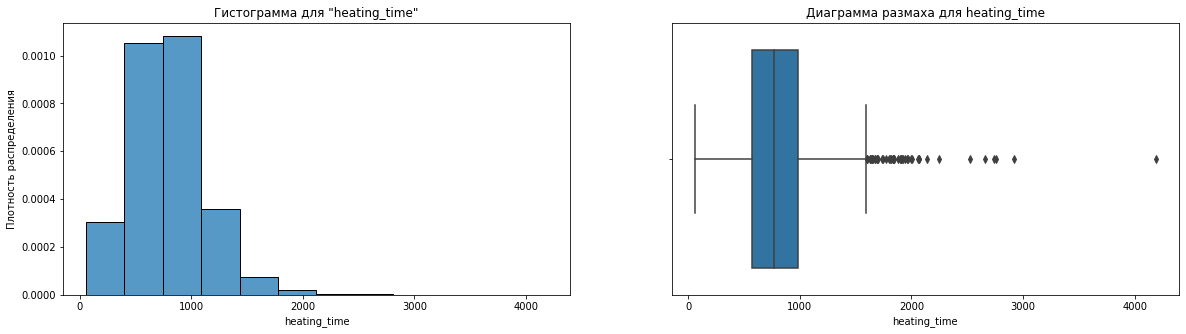

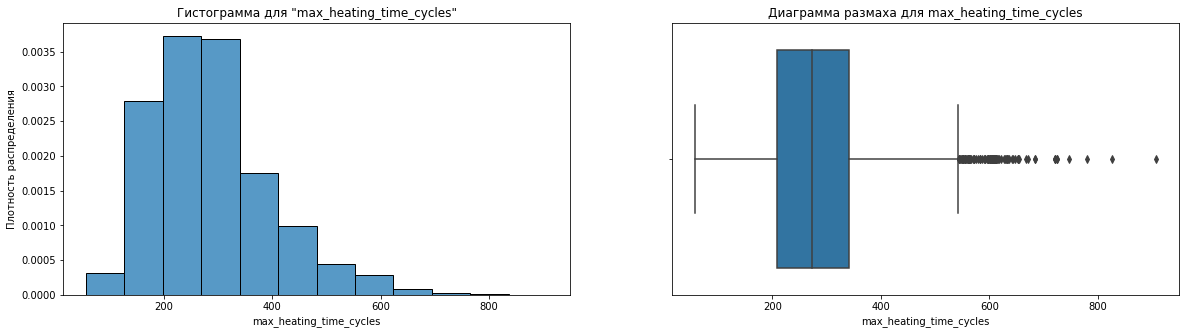

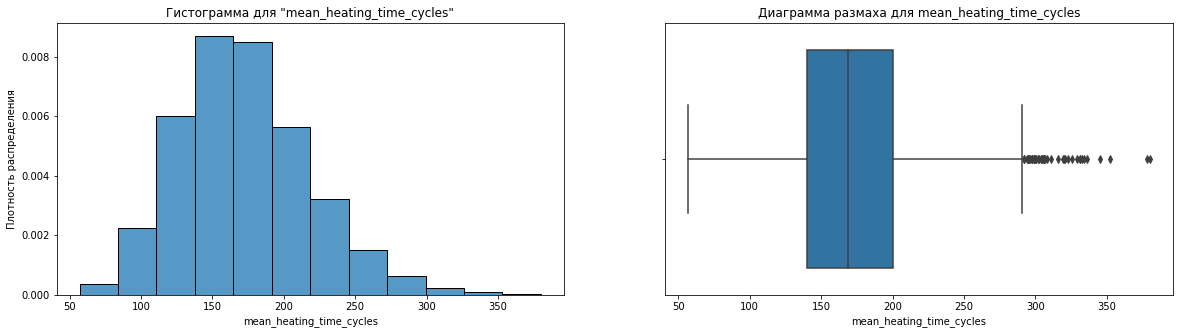

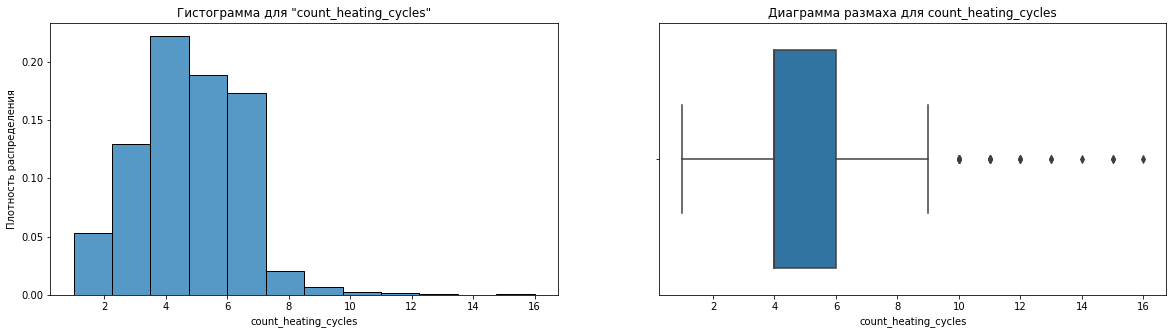

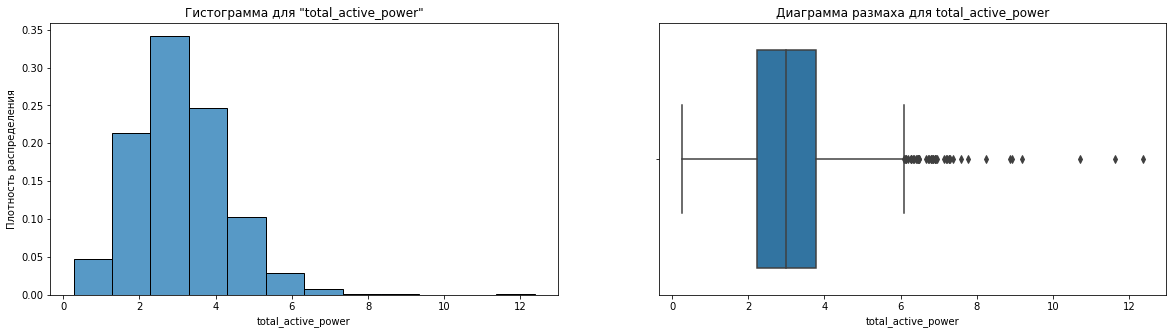

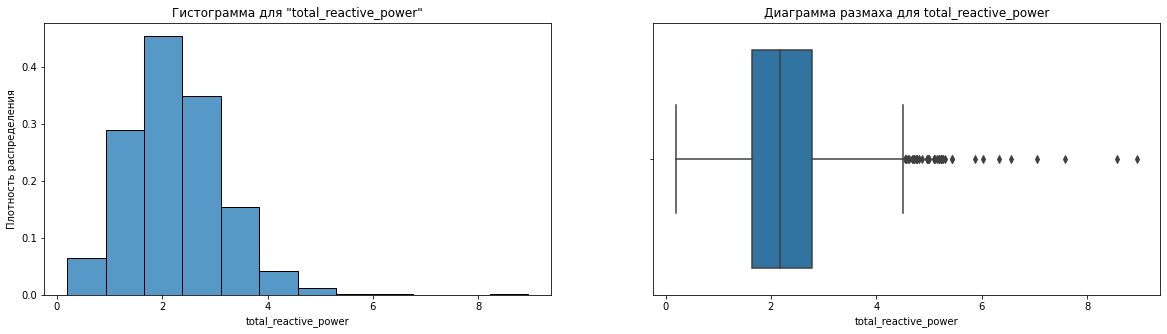

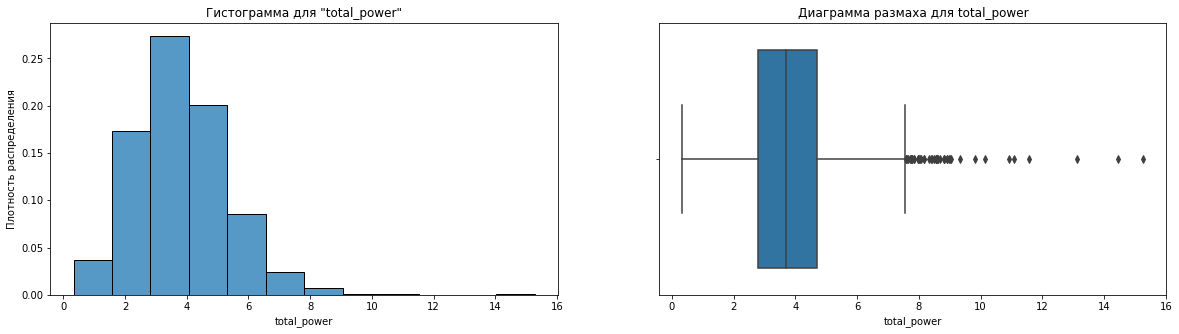

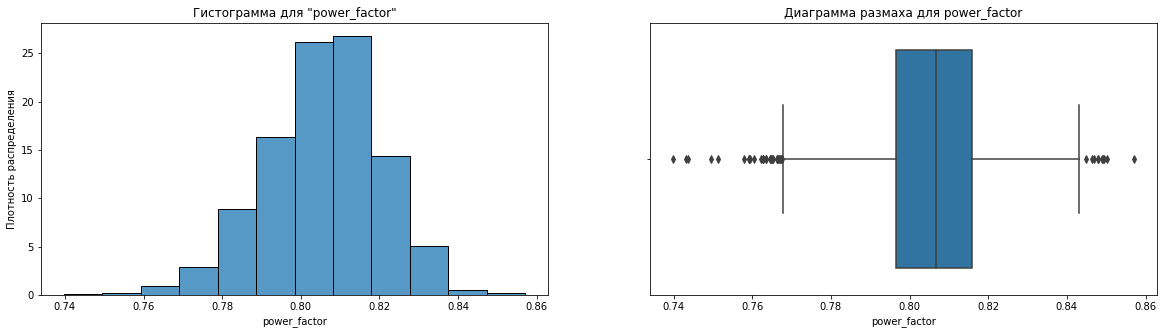

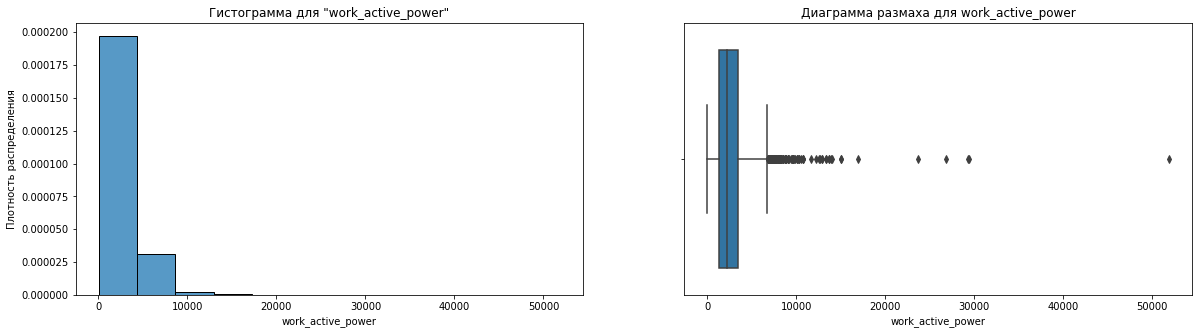

In [25]:
# Построение гистограммы и диаграммы размаха для признаков полученного датафрейма
for feature in [x for x in data_arc_df_agg.columns if x!='key']:
    density_and_box(data_arc_df_agg, feature)

In [26]:
for feature in [x for x in data_arc_df_agg.columns if x!='key']:
    print(feature)
    df_high_border_box, df_low_border_box, df_filtered, df_outliers = border_box(data_arc_df_agg, feature)
    print('-'*50)

heating_time
верхняя граница (high_border_box):  1601.0
нижняя граница (low_border_box):  -47.0
Количество строк датафрейма, которые попали за границы диаграммы размаха:  49
Доля строк датафрейма, которые попали за границы диаграммы размаха:  1.5245799626633478 %
--------------------------------------------------
max_heating_time_cycles
верхняя граница (high_border_box):  543.0
нижняя граница (low_border_box):  7.0
Количество строк датафрейма, которые попали за границы диаграммы размаха:  104
Доля строк датафрейма, которые попали за границы диаграммы размаха:  3.2358431860609835 %
--------------------------------------------------
mean_heating_time_cycles
верхняя граница (high_border_box):  290.9583333333333
нижняя граница (low_border_box):  49.42500000000001
Количество строк датафрейма, которые попали за границы диаграммы размаха:  44
Доля строк датафрейма, которые попали за границы диаграммы размаха:  1.3690105787181084 %
--------------------------------------------------
count_heati

In [27]:
# Тест Шапиро-Уилка на нормальность распределения данных для количественных признаков
for feature in [x for x in data_arc_df_agg.columns if x!='key']:
    print(f'Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для {feature}:\n', 
          shapiro(data_arc_df_agg[f'{feature}']))
    print('-'*50)

Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для heating_time:
 ShapiroResult(statistic=0.9548647403717041, pvalue=1.9257480719012766e-30)
--------------------------------------------------
Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для max_heating_time_cycles:
 ShapiroResult(statistic=0.9443711638450623, pvalue=3.331741842102011e-33)
--------------------------------------------------
Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для mean_heating_time_cycles:
 ShapiroResult(statistic=0.9842891693115234, pvalue=2.0226675287483537e-18)
--------------------------------------------------
Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для count_heating_cycles:
 ShapiroResult(statistic=0.9317268133163452, pvalue=4.945642444597188e-36)
--------------------------------------------------
Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для to

___
Из теста Шапиро-Уилка видно, что перечисленные признаки не имеют нормального распределения
___

In [28]:
# Вывод максимального значения за пределами усов диаграммы размаха для оценки
data_arc_df_agg.query('work_active_power > 50000')

,key,heating_time,max_heating_time_cycles,mean_heating_time_cycles,count_heating_cycles,total_active_power,total_reactive_power,total_power,power_factor,work_active_power
1672,1689,4189,907,279.267,15,12.376,8.949,15.272,0.810,"51,841.539"


In [29]:
# Проверка на наличие явных дубликатов
data_arc_df_agg.duplicated().sum()

0

___
- Выполнили загрузку данных об электродах из таблицы `data_arc`. Выделим основные особенности:
    - Пропуски и явные дубликаты отсутствуют
    - Привели наименования столбцов к стандарту PEP8
    - Для столбцов, содержащих дату и время изменили тип данных на `datetime`
    - Отрицательное значение реактивной мощности заменили его на медианное значение
- Создали датафрейм `data_arc_df_agg` (3214 строк, 10 столбцов), агрегированный по каждому номеру партии. В данный датафрейм добавили признаки:
    - `heating_time` длительность нагрева (суммарное время нагрева для одной партии в секундах), 
    - `total_power` общую мощность (S) (векторная сумма активной (P) и реактивной мощностей (Q): $ S=\sqrt{P^2 + Q^2} $)
    - `power_factor` соотношение активной мощности к реактивной (PF) (показатель, характеризующий эффективность использования электроэнергии: $ PF=P/S $), 
    - `count_heating_cycles` количество циклов нагрева для одной партии 
    - `mean_heating_time_cycles` среднее время нагрева в цикле для одной партии в секундах
    - `max_heating_time_cycles` максимальное время нагрева в цикле для одной партии в секундах
    - `work_active_power` работа, совершаемая активной мощностью (произведение активной мощности на длительность нагрева)
- Значения признаков за пределами усов диаграммы размаха считаем возможными и оставили как есть 
___

### Данные об объёме сыпучих материалов `data_bulk`

In [30]:
# Создание датафрейма с данными из таблицы

query = '''
SELECT  *
FROM data_bulk;
''' 
data_bulk_df = pd.read_sql_query(query, con = engine) 

In [31]:
data_info(data_bulk_df)

,key,Bulk 1,Bulk 2,Bulk 3,Bulk 4,Bulk 5,Bulk 6,Bulk 7,Bulk 8,Bulk 9,Bulk 10,Bulk 11,Bulk 12,Bulk 13,Bulk 14,Bulk 15
0,1,NaN,NaN,NaN,43.000,None,None,None,None,None,None,None,206.0,None,150.0,154.0
1,2,NaN,NaN,NaN,73.000,None,None,None,None,None,None,None,206.0,None,149.0,154.0
2,3,NaN,NaN,NaN,34.000,None,None,None,None,None,None,None,205.0,None,152.0,153.0
3,4,NaN,NaN,NaN,81.000,None,None,None,None,None,None,None,207.0,None,153.0,154.0
4,5,NaN,NaN,NaN,78.000,None,None,None,None,None,None,None,203.0,None,151.0,152.0


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   key      3129 non-null   int64  
 1   Bulk 1   252 non-null    float64
 2   Bulk 2   22 non-null     float64
 3   Bulk 3   1298 non-null   float64
 4   Bulk 4   1014 non-null   float64
 5   Bulk 5   77 non-null     object 
 6   Bulk 6   576 non-null    object 
 7   Bulk 7   25 non-null     object 
 8   Bulk 8   1 non-null      object 
 9   Bulk 9   19 non-null     object 
 10  Bulk 10  176 non-null    object 
 11  Bulk 11  177 non-null    object 
 12  Bulk 12  2450 non-null   object 
 13  Bulk 13  18 non-null     object 
 14  Bulk 14  2806 non-null   object 
 15  Bulk 15  2248 non-null   object 
dtypes: float64(4), int64(1), object(11)
memory usage: 391.2+ KB
--------------------------------------------------
Количест

,count,mean,std,min,25%,50%,75%,max
key,"3,129.000","1,624.384",933.338,1.000,816.000,"1,622.000","2,431.000","3,241.000"
Bulk 1,252.000,39.242,18.278,10.000,27.000,31.000,46.000,185.000
Bulk 2,22.000,253.045,21.181,228.000,242.000,251.500,257.750,325.000
Bulk 3,"1,298.000",113.879,75.483,6.000,58.000,97.500,152.000,454.000
Bulk 4,"1,014.000",104.394,48.184,12.000,72.000,102.000,133.000,281.000


,count,unique,top,freq
Bulk 5,77,55,74.0,5
Bulk 6,576,205,76.0,15
Bulk 7,25,25,208.0,1
Bulk 8,1,1,49.0,1
Bulk 9,19,10,68.0,4
Bulk 10,176,77,105.0,8
Bulk 11,177,101,18.0,7
Bulk 12,2450,331,206.0,224
Bulk 13,18,14,153.0,3
Bulk 14,2806,284,102.0,99


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
Bulk 8,3128
Bulk 13,3111
Bulk 9,3110
Bulk 2,3107
Bulk 7,3104
Bulk 5,3052
Bulk 10,2953
Bulk 11,2952
Bulk 1,2877
Bulk 6,2553


,0
Bulk 8,99.97%
Bulk 13,99.42%
Bulk 9,99.39%
Bulk 2,99.30%
Bulk 7,99.20%
Bulk 5,97.54%
Bulk 10,94.38%
Bulk 11,94.34%
Bulk 1,91.95%
Bulk 6,81.59%


___
- 3129 строк и 16 столбцов
- Необходимо привести наименования столбцов к стандарту PEP8
- Для столбцов `Bulk 5`...`Bulk 15` необходимо изменить тип данных на `float`
- Во всех столбцах, кроме `key` есть пропуски. Пропуск по условию заказчика означает, что материал не добавляли в партию. Оставим их как есть, но добавим столбец с расчетом суммы объёма подаваемого материала. Дополнительно добавим столбец с расчетом количества раз, когда подавали материал. В модели будем использовать именно эти два признака
___

In [32]:
# Приведение столбцов к стандарту PEP8
data_bulk_df.columns = data_bulk_df.columns.str.lower().str.replace(' ', '_')

# Изменение типа данных для столбцов Bulk 5...Bulk 15
for feature in [x for x in data_bulk_df.columns if x!='key']:
    data_bulk_df[feature] = data_bulk_df[feature].astype('float')

In [33]:
# Добавление столбца с расчетом суммы объёма подаваемого материала
data_bulk_df['bulk_total'] = data_bulk_df[list(data_bulk_df.drop('key', axis=1).columns)].sum(axis=1)

In [34]:
# Добавление столбца с расчетом количества раз, когда подавали материал
data_bulk_df['bulk_count'] = data_bulk_df[list(data_bulk_df.drop(['key', 'bulk_total'], axis=1).columns)].count(axis=1)

In [35]:
data_bulk_df.head()

,key,bulk_1,bulk_2,bulk_3,bulk_4,bulk_5,bulk_6,bulk_7,bulk_8,bulk_9,bulk_10,bulk_11,bulk_12,bulk_13,bulk_14,bulk_15,bulk_total,bulk_count
0,1,NaN,NaN,NaN,43.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,206.000,NaN,150.000,154.000,553.000,4
1,2,NaN,NaN,NaN,73.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,206.000,NaN,149.000,154.000,582.000,4
2,3,NaN,NaN,NaN,34.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,205.000,NaN,152.000,153.000,544.000,4
3,4,NaN,NaN,NaN,81.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,207.000,NaN,153.000,154.000,595.000,4
4,5,NaN,NaN,NaN,78.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,203.000,NaN,151.000,152.000,584.000,4


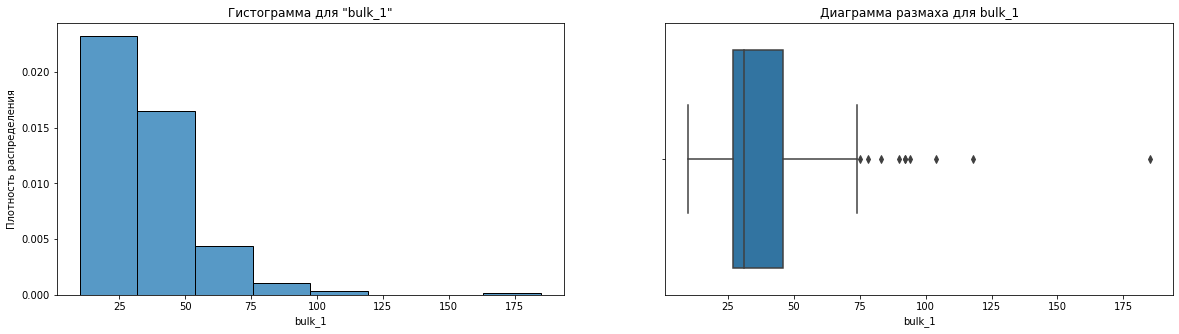

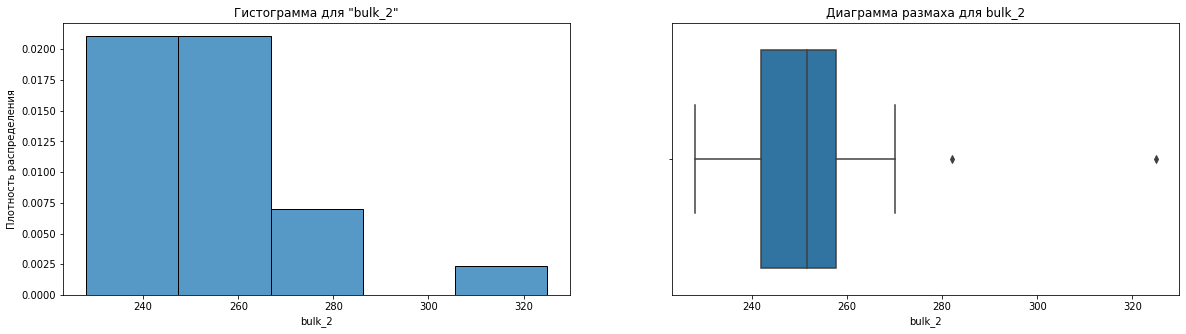

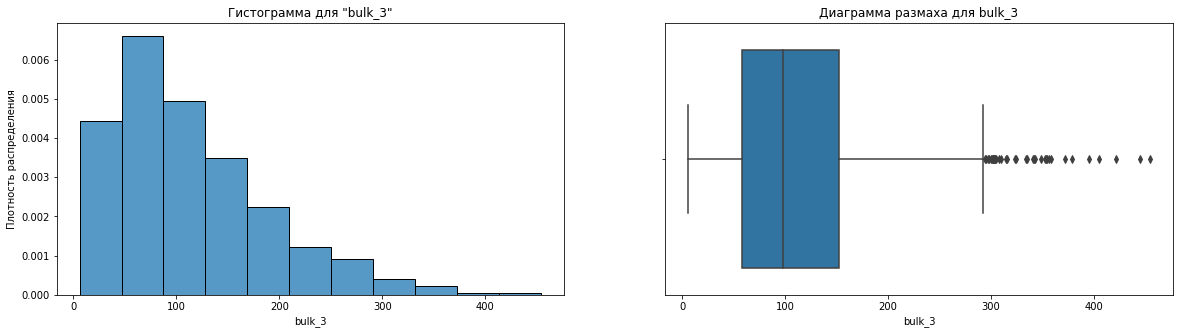

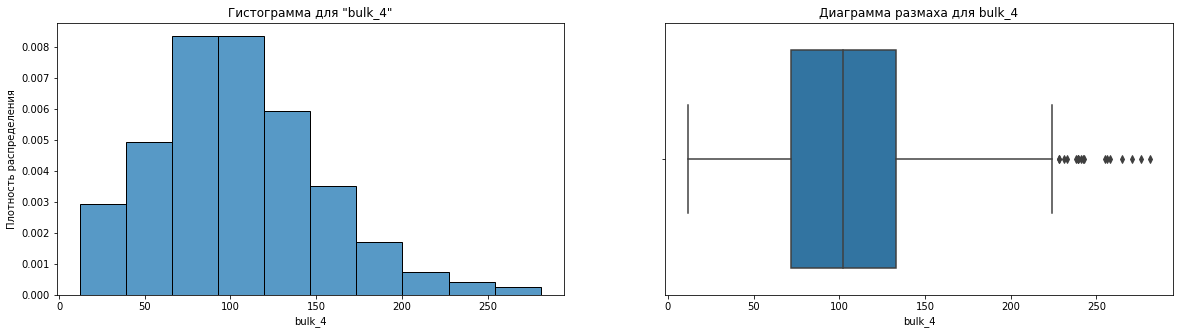

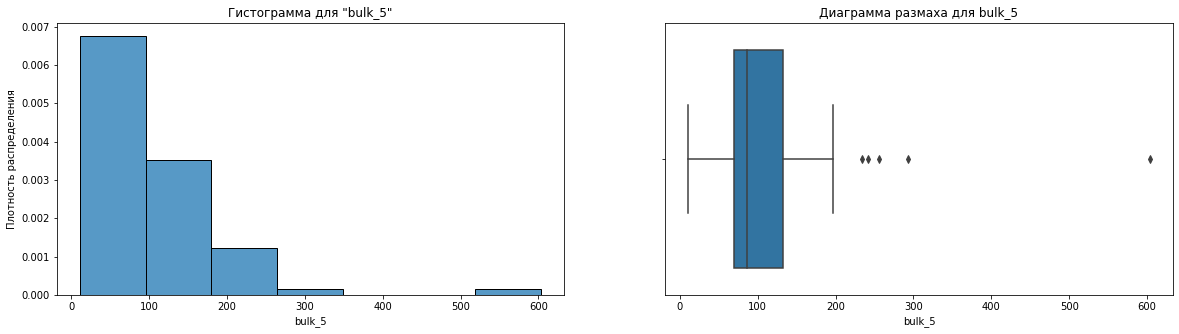

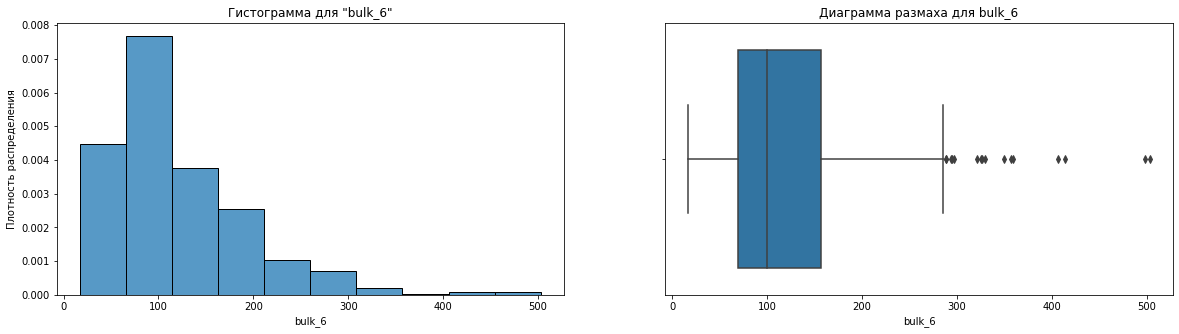

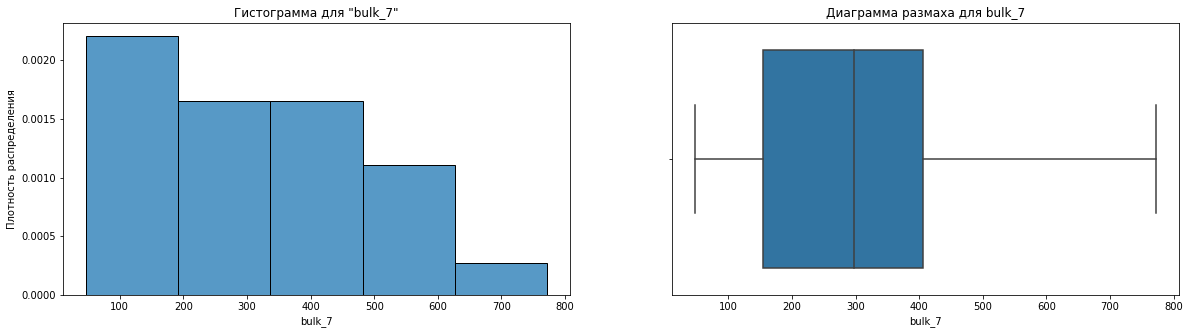

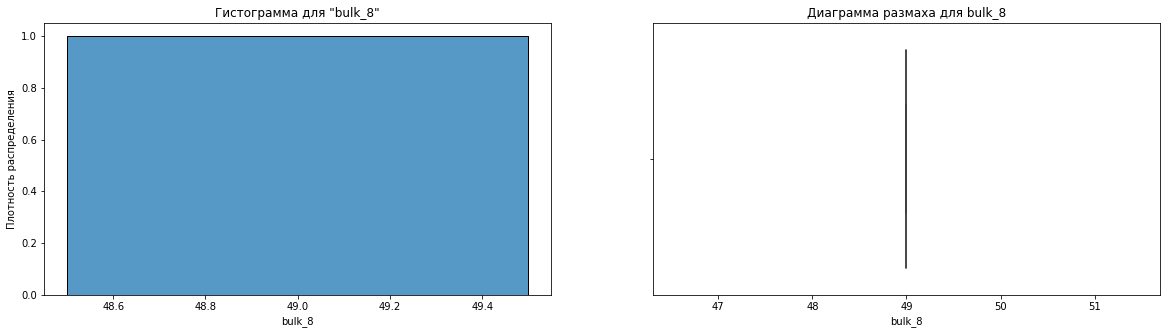

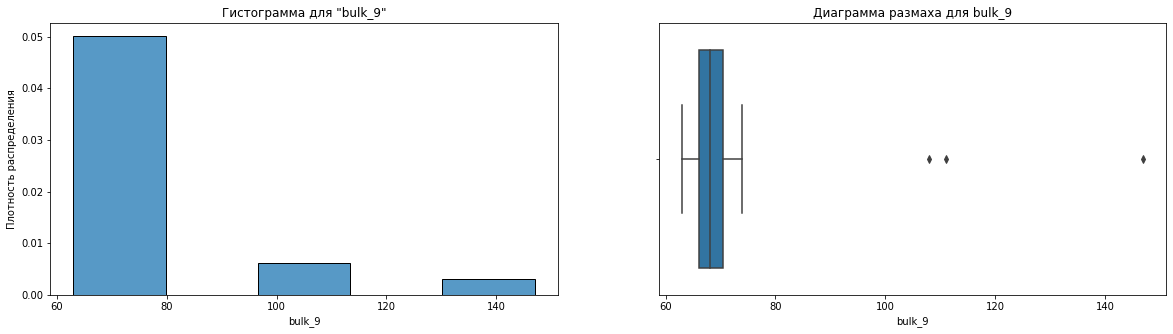

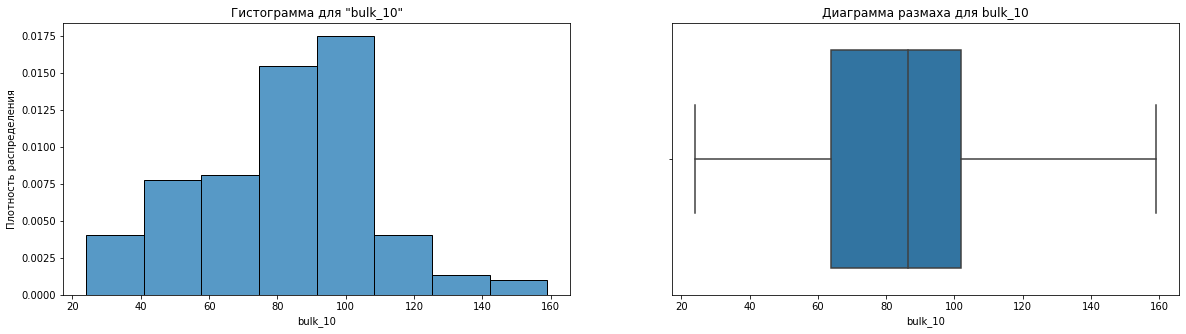

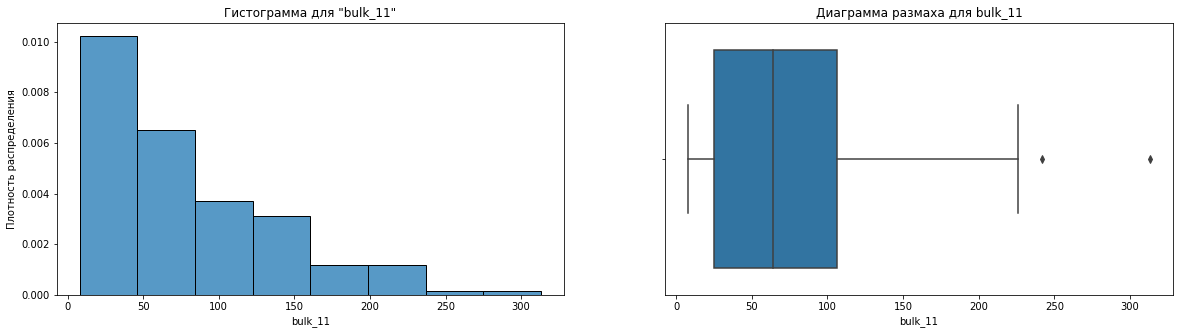

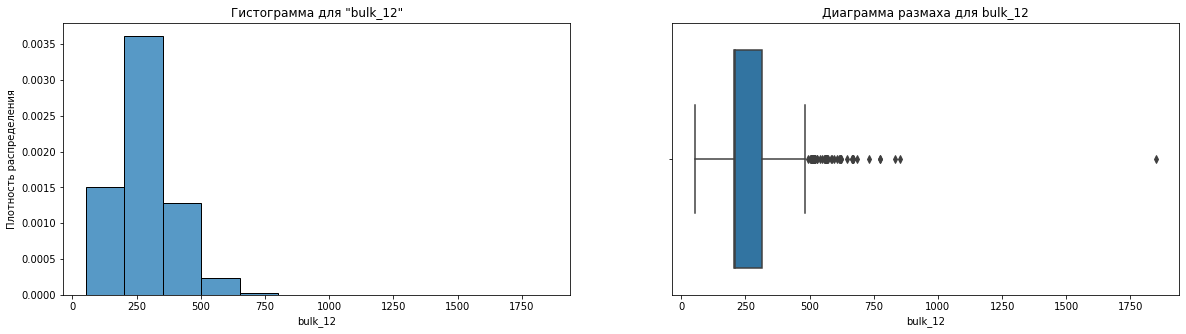

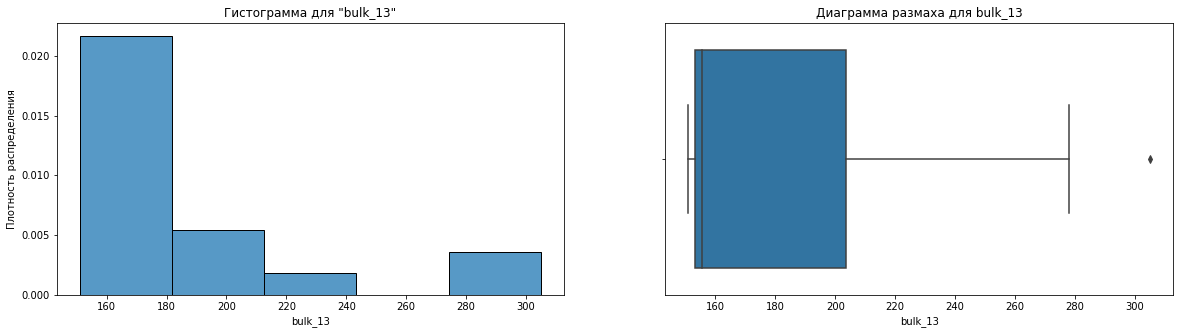

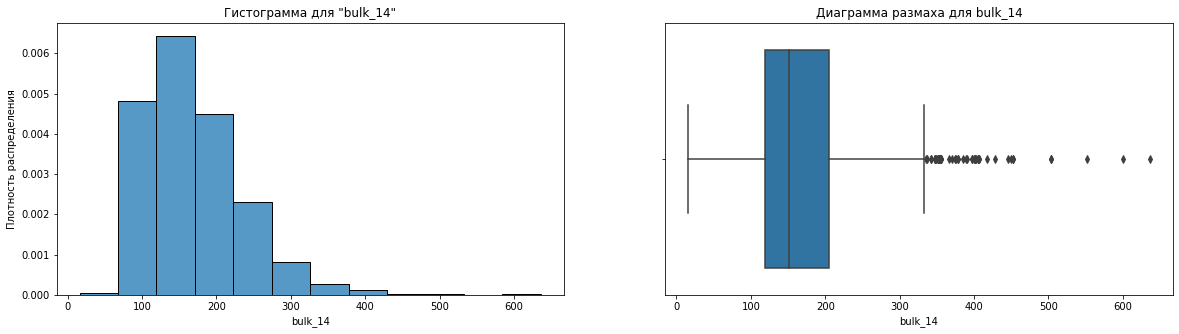

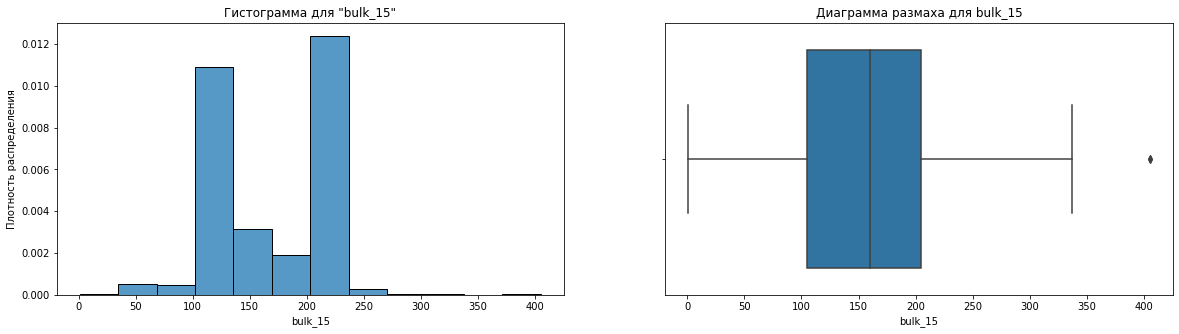

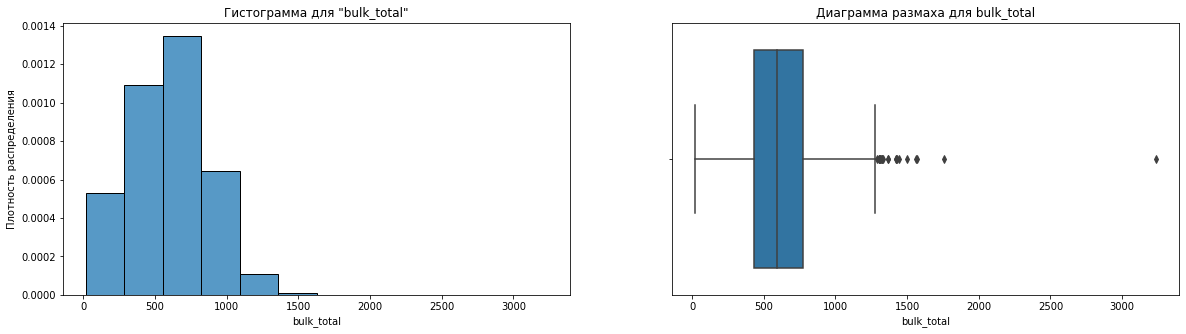

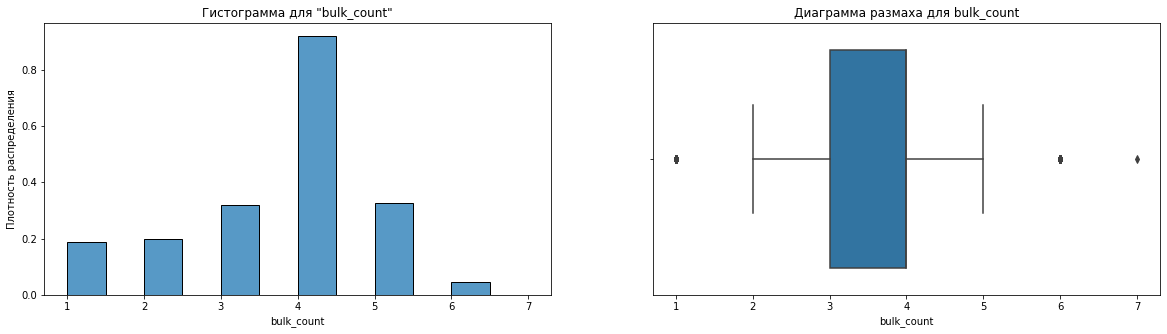

In [36]:
# Построение гистограммы и диаграммы размаха для признаков полученного датафрейма
for feature in [x for x in data_bulk_df.columns if x!='key']:
    density_and_box(data_bulk_df, feature)

In [37]:
for feature in [x for x in data_bulk_df.columns if x!='key']:
    print(feature)
    df_high_border_box, df_low_border_box, df_filtered, df_outliers = border_box(data_bulk_df, feature)
    print('-'*50)

bulk_1
верхняя граница (high_border_box):  74.5
нижняя граница (low_border_box):  -1.5
Количество строк датафрейма, которые попали за границы диаграммы размаха:  10
Доля строк датафрейма, которые попали за границы диаграммы размаха:  0.31959092361776925 %
--------------------------------------------------
bulk_2
верхняя граница (high_border_box):  281.375
нижняя граница (low_border_box):  218.375
Количество строк датафрейма, которые попали за границы диаграммы размаха:  2
Доля строк датафрейма, которые попали за границы диаграммы размаха:  0.06391818472355384 %
--------------------------------------------------
bulk_3
верхняя граница (high_border_box):  293.0
нижняя граница (low_border_box):  -83.0
Количество строк датафрейма, которые попали за границы диаграммы размаха:  38
Доля строк датафрейма, которые попали за границы диаграммы размаха:  1.214445509747523 %
--------------------------------------------------
bulk_4
верхняя граница (high_border_box):  224.5
нижняя граница (low_borde

___
Прежде, чем удалять на наш взгляд аномальные значения я бы все-таки уточнился у бизнеса, возможно на предприятии применяется какая-то своя уникальная технология... В целом, конечно, в интернете можно найти информацию, что общий объем сыпучих материалов для 100 тонного ковша врятли достигнет более 1500 кг (https://patents.google.com/patent/SU1361181A1/ru). 

Уберем из датафрейма строки, где суммарный объем сыпучих материалов более 1500
___

In [38]:
# Вывод строк в которых общий объем сыпучих материалов превышает 1500 кг
data_bulk_df.query('bulk_total>1500')

,key,bulk_1,bulk_2,bulk_3,bulk_4,bulk_5,bulk_6,bulk_7,bulk_8,bulk_9,bulk_10,bulk_11,bulk_12,bulk_13,bulk_14,bulk_15,bulk_total,bulk_count
303,322,185.000,NaN,101.000,58.000,NaN,NaN,406.000,NaN,NaN,NaN,NaN,"1,849.000",NaN,636.000,NaN,"3,235.000",6
308,327,67.000,NaN,NaN,119.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,775.000,NaN,403.000,205.000,"1,569.000",5
1629,1689,NaN,NaN,NaN,NaN,NaN,247.000,NaN,NaN,NaN,NaN,NaN,733.000,305.000,248.000,224.000,"1,757.000",5
1933,1999,54.000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,853.000,NaN,366.000,290.000,"1,563.000",4


In [39]:
# Исключение строк в которых общий объем сыпучих материалов превышает 1500 кг
data_bulk_df = data_bulk_df.query('bulk_total<=1500')

In [40]:
data_bulk_df_agg = data_bulk_df[['key', 'bulk_total', 'bulk_count']]
data_info(data_bulk_df_agg)

,key,bulk_total,bulk_count
0,1,553.000,4
1,2,582.000,4
2,3,544.000,4
3,4,595.000,4
4,5,584.000,4


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 3125 entries, 0 to 3128
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   key         3125 non-null   int64  
 1   bulk_total  3125 non-null   float64
 2   bulk_count  3125 non-null   int64  
dtypes: float64(1), int64(2)
memory usage: 97.7 KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"3,125.000","1,625.075",933.331,1.000,817.000,"1,622.000","2,432.000","3,241.000"
bulk_total,"3,125.000",593.666,270.765,19.000,429.000,591.000,771.000,"1,498.000"
bulk_count,"3,125.000",3.564,1.216,1.000,3.000,4.000,4.000,7.000


,count,mean,std,min,25%,50%,75%,max
key,"3,125.000","1,625.075",933.331,1.000,817.000,"1,622.000","2,432.000","3,241.000"
bulk_total,"3,125.000",593.666,270.765,19.000,429.000,591.000,771.000,"1,498.000"
bulk_count,"3,125.000",3.564,1.216,1.000,3.000,4.000,4.000,7.000


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
key,0
bulk_total,0
bulk_count,0


,0
key,0.00%
bulk_total,0.00%
bulk_count,0.00%


___
Выполнили загрузку данных об объёме сыпучих материалов `data_bulk`. Выделим основные особенности:
- 3125 строк и 16 столбцов
- Привели наименования столбцов к стандарту PEP8
- Для столбцов `Bulk 5`...`Bulk 15` изменили тип данных на `float`
- Во всех столбцах, кроме `key` есть пропуски. Пропуск по условию заказчика означает, что материал не добавляли в партию. Оставили их как есть, но добавили столбец `bulk_total` с расчетом суммы объёма подаваемого материала. Дополнительно добавили столбец `bulk_count` с расчетом количества раз, когда подавали материал. В модели будем использовать именно эти два признака, которые выделили в датафрейме `data_bulk_df_agg` 
- Из датафрейма `data_bulk` исключены строки, в которых общий объем сыпучих материалов превышает 1500 кг
___

### Данные о времени подачи сыпучих материалов `data_bulk_time`

In [41]:
# Создание датафрейма с данными из таблицы

query = '''
SELECT  *
FROM data_bulk_time;
''' 
data_bulk_time_df = pd.read_sql_query(query, con = engine) 

In [42]:
data_info(data_bulk_time_df)

,key,Bulk 1,Bulk 2,Bulk 3,Bulk 4,Bulk 5,Bulk 6,Bulk 7,Bulk 8,Bulk 9,Bulk 10,Bulk 11,Bulk 12,Bulk 13,Bulk 14,Bulk 15
0,1,None,None,None,2019-05-03 11:28:48,None,None,None,None,None,None,None,2019-05-03 11:24:31,None,2019-05-03 11:14:50,2019-05-03 11:10:43
1,2,None,None,None,2019-05-03 11:36:50,None,None,None,None,None,None,None,2019-05-03 11:53:30,None,2019-05-03 11:48:37,2019-05-03 11:44:39
2,3,None,None,None,2019-05-03 12:32:39,None,None,None,None,None,None,None,2019-05-03 12:27:13,None,2019-05-03 12:21:01,2019-05-03 12:16:16
3,4,None,None,None,2019-05-03 12:43:22,None,None,None,None,None,None,None,2019-05-03 12:58:00,None,2019-05-03 12:51:11,2019-05-03 12:46:36
4,5,None,None,None,2019-05-03 13:30:47,None,None,None,None,None,None,None,2019-05-03 13:30:47,None,2019-05-03 13:34:12,2019-05-03 13:30:47


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   key      3129 non-null   int64 
 1   Bulk 1   252 non-null    object
 2   Bulk 2   22 non-null     object
 3   Bulk 3   1298 non-null   object
 4   Bulk 4   1014 non-null   object
 5   Bulk 5   77 non-null     object
 6   Bulk 6   576 non-null    object
 7   Bulk 7   25 non-null     object
 8   Bulk 8   1 non-null      object
 9   Bulk 9   19 non-null     object
 10  Bulk 10  176 non-null    object
 11  Bulk 11  177 non-null    object
 12  Bulk 12  2450 non-null   object
 13  Bulk 13  18 non-null     object
 14  Bulk 14  2806 non-null   object
 15  Bulk 15  2248 non-null   object
dtypes: int64(1), object(15)
memory usage: 391.2+ KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных

,count,mean,std,min,25%,50%,75%,max
key,"3,129.000","1,624.384",933.338,1.000,816.000,"1,622.000","2,431.000","3,241.000"


,count,unique,top,freq
Bulk 1,252,252,2019-09-04 16:01:08,1
Bulk 2,22,22,2019-08-13 07:26:20,1
Bulk 3,1298,1298,2019-08-31 19:53:25,1
Bulk 4,1014,1014,2019-06-28 11:42:38,1
Bulk 5,77,77,2019-07-27 18:12:32,1
Bulk 6,576,576,2019-06-12 05:43:39,1
Bulk 7,25,25,2019-09-05 19:07:49,1
Bulk 8,1,1,2019-07-08 17:14:53,1
Bulk 9,19,19,2019-05-14 12:35:40,1
Bulk 10,176,176,2019-06-28 15:13:56,1


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
Bulk 8,3128
Bulk 13,3111
Bulk 9,3110
Bulk 2,3107
Bulk 7,3104
Bulk 5,3052
Bulk 10,2953
Bulk 11,2952
Bulk 1,2877
Bulk 6,2553


,0
Bulk 8,99.97%
Bulk 13,99.42%
Bulk 9,99.39%
Bulk 2,99.30%
Bulk 7,99.20%
Bulk 5,97.54%
Bulk 10,94.38%
Bulk 11,94.34%
Bulk 1,91.95%
Bulk 6,81.59%


___
- 3129 строк и 16 столбцов
- Необходимо привести наименования столбцов к стандарту PEP8
- Для столбцов `Bulk 1`...`Bulk 15` необходимо изменить тип данных на `datetime`
- Во всех столбцах, кроме `key` есть пропуски. Пропуск по условию заказчика означает, что материал не добавляли в партию. 
___

In [43]:
# Приведение столбцов к стандарту PEP8
data_bulk_time_df.columns = data_bulk_time_df.columns.str.lower().str.replace(' ', '_')

# Изменение типа данных 
for feature in [x for x in data_bulk_time_df.columns if x!='key']:
    data_bulk_time_df[feature] = pd.to_datetime(data_bulk_time_df[feature], format='%Y-%m-%d %H:%M:%S')
    
data_info(data_bulk_time_df)


,key,bulk_1,bulk_2,bulk_3,bulk_4,bulk_5,bulk_6,bulk_7,bulk_8,bulk_9,bulk_10,bulk_11,bulk_12,bulk_13,bulk_14,bulk_15
0,1,NaT,NaT,NaT,2019-05-03 11:28:48,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2019-05-03 11:24:31,NaT,2019-05-03 11:14:50,2019-05-03 11:10:43
1,2,NaT,NaT,NaT,2019-05-03 11:36:50,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2019-05-03 11:53:30,NaT,2019-05-03 11:48:37,2019-05-03 11:44:39
2,3,NaT,NaT,NaT,2019-05-03 12:32:39,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2019-05-03 12:27:13,NaT,2019-05-03 12:21:01,2019-05-03 12:16:16
3,4,NaT,NaT,NaT,2019-05-03 12:43:22,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2019-05-03 12:58:00,NaT,2019-05-03 12:51:11,2019-05-03 12:46:36
4,5,NaT,NaT,NaT,2019-05-03 13:30:47,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2019-05-03 13:30:47,NaT,2019-05-03 13:34:12,2019-05-03 13:30:47


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 16 columns):
 #   Column   Non-Null Count  Dtype         
---  ------   --------------  -----         
 0   key      3129 non-null   int64         
 1   bulk_1   252 non-null    datetime64[ns]
 2   bulk_2   22 non-null     datetime64[ns]
 3   bulk_3   1298 non-null   datetime64[ns]
 4   bulk_4   1014 non-null   datetime64[ns]
 5   bulk_5   77 non-null     datetime64[ns]
 6   bulk_6   576 non-null    datetime64[ns]
 7   bulk_7   25 non-null     datetime64[ns]
 8   bulk_8   1 non-null      datetime64[ns]
 9   bulk_9   19 non-null     datetime64[ns]
 10  bulk_10  176 non-null    datetime64[ns]
 11  bulk_11  177 non-null    datetime64[ns]
 12  bulk_12  2450 non-null   datetime64[ns]
 13  bulk_13  18 non-null     datetime64[ns]
 14  bulk_14  2806 non-null   datetime64[ns]
 15  bulk_15  2248 non-null   datetime64[ns

,count,mean,std,min,25%,50%,75%,max
key,"3,129.000","1,624.384",933.338,1.000,816.000,"1,622.000","2,431.000","3,241.000"


,count,mean,std,min,25%,50%,75%,max
key,"3,129.000","1,624.384",933.338,1.000,816.000,"1,622.000","2,431.000","3,241.000"


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
bulk_8,3128
bulk_13,3111
bulk_9,3110
bulk_2,3107
bulk_7,3104
bulk_5,3052
bulk_10,2953
bulk_11,2952
bulk_1,2877
bulk_6,2553


,0
bulk_8,99.97%
bulk_13,99.42%
bulk_9,99.39%
bulk_2,99.30%
bulk_7,99.20%
bulk_5,97.54%
bulk_10,94.38%
bulk_11,94.34%
bulk_1,91.95%
bulk_6,81.59%


Выполним проверку, что подача материала не измеряется сутками. Для этого добавим столбец в котором посчитаем разницу в секундах между первым и последним добавлением материала

In [44]:
# Добавление столбца с расчетом разницы в секундах между первым и последним добавлением материала
data_bulk_time_df['bulk_duration'] = (
    (data_bulk_time_df.drop('key', axis=1).apply(lambda row: (row.max() - row.min()).total_seconds(), axis=1)).astype(int)
)

data_bulk_time_df.head()

,key,bulk_1,bulk_2,bulk_3,bulk_4,bulk_5,bulk_6,bulk_7,bulk_8,bulk_9,bulk_10,bulk_11,bulk_12,bulk_13,bulk_14,bulk_15,bulk_duration
0,1,NaT,NaT,NaT,2019-05-03 11:28:48,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2019-05-03 11:24:31,NaT,2019-05-03 11:14:50,2019-05-03 11:10:43,1085
1,2,NaT,NaT,NaT,2019-05-03 11:36:50,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2019-05-03 11:53:30,NaT,2019-05-03 11:48:37,2019-05-03 11:44:39,1000
2,3,NaT,NaT,NaT,2019-05-03 12:32:39,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2019-05-03 12:27:13,NaT,2019-05-03 12:21:01,2019-05-03 12:16:16,983
3,4,NaT,NaT,NaT,2019-05-03 12:43:22,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2019-05-03 12:58:00,NaT,2019-05-03 12:51:11,2019-05-03 12:46:36,878
4,5,NaT,NaT,NaT,2019-05-03 13:30:47,NaT,NaT,NaT,NaT,NaT,NaT,NaT,2019-05-03 13:30:47,NaT,2019-05-03 13:34:12,2019-05-03 13:30:47,205


In [45]:
data_bulk_time_df_agg = data_bulk_time_df[['key', 'bulk_duration']]
display(data_bulk_time_df_agg.sort_values(by='bulk_duration', ascending=False).head())
print(f'Максимальная разница между первым и последним добавлением материала в часах: {round(data_bulk_time_df_agg["bulk_duration"].max()/3600, 1)}')

,key,bulk_duration
1895,1958,13683
1819,1881,11552
1818,1880,9336
2859,2965,7238
2470,2562,6671


Максимальная разница между первым и последним добавлением материала в часах: 3.8


In [46]:
data_info(data_bulk_time_df_agg)

,key,bulk_duration
0,1,1085
1,2,1000
2,3,983
3,4,878
4,5,205


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3129 entries, 0 to 3128
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   key            3129 non-null   int64
 1   bulk_duration  3129 non-null   int64
dtypes: int64(2)
memory usage: 49.0 KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"3,129.000","1,624.384",933.338,1.000,816.000,"1,622.000","2,431.000","3,241.000"
bulk_duration,"3,129.000",964.907,798.088,0.000,485.000,877.000,"1,311.000","13,683.000"


,count,mean,std,min,25%,50%,75%,max
key,"3,129.000","1,624.384",933.338,1.000,816.000,"1,622.000","2,431.000","3,241.000"
bulk_duration,"3,129.000",964.907,798.088,0.000,485.000,877.000,"1,311.000","13,683.000"


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
key,0
bulk_duration,0


,0
key,0.00%
bulk_duration,0.00%


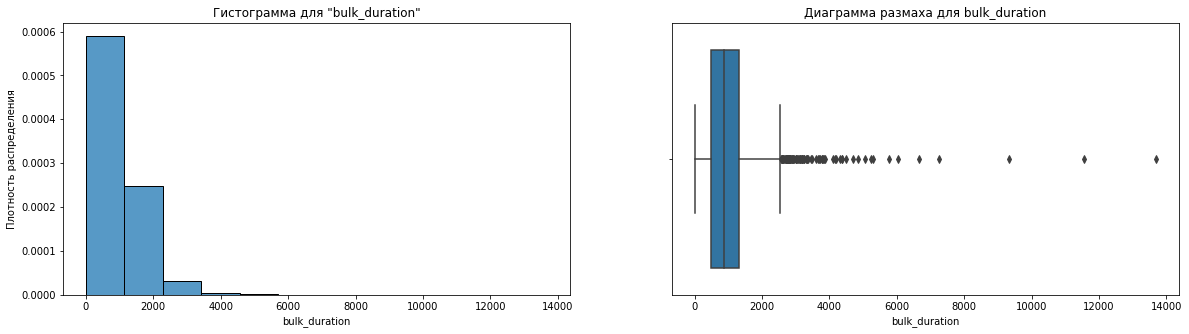

In [47]:
density_and_box(data_bulk_time_df_agg, 'bulk_duration')

In [48]:
df_high_border_box, df_low_border_box, df_filtered, df_outliers = border_box(data_bulk_time_df_agg, 'bulk_duration')

верхняя граница (high_border_box):  2550.0
нижняя граница (low_border_box):  -754.0
Количество строк датафрейма, которые попали за границы диаграммы размаха:  89
Доля строк датафрейма, которые попали за границы диаграммы размаха:  2.8443592201981462 %


In [49]:
print(f'Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для bulk_duration:\n', 
          shapiro(data_bulk_time_df_agg['bulk_duration']))

Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для bulk_duration:
 ShapiroResult(statistic=0.8038560152053833, pvalue=0.0)


In [50]:
data_bulk_time_df.query('bulk_duration>12000')

,key,bulk_1,bulk_2,bulk_3,bulk_4,bulk_5,bulk_6,bulk_7,bulk_8,bulk_9,bulk_10,bulk_11,bulk_12,bulk_13,bulk_14,bulk_15,bulk_duration
1895,1958,NaT,NaT,2019-07-21 14:44:03,NaT,NaT,2019-07-21 14:39:15,NaT,NaT,NaT,NaT,NaT,2019-07-21 14:31:46,NaT,2019-07-21 14:27:11,2019-07-21 10:56:00,13683


___
Выполнили загрузку данных о времени подачи сыпучих материалов `data_bulk_time`. Выделим основные особенности:
- 3129 строк и 16 столбцов
- Привели наименования столбцов к стандарту PEP8
- Для столбцов `Bulk 1`...`Bulk 15` изменили тип данных на `datetime`
- Во всех столбцах, кроме `key` есть пропуски. Пропуск по условию заказчика означает, что материал не добавляли в партию. Оставили их как есть, но добавили столбец `bulk_duration` с расчетом разницы в секундах между первым и последним добавлением материала. В модели будем использовать именно этот признак, который выделили в датафрейме `data_bulk_time_df_agg`
- Значения признаков за пределами усов диаграммы размаха считаем возможными и оставили как есть 
___

### Данные о продувке сплава газом `data_gas`

In [51]:
# Создание датафрейма с данными из таблицы

query = '''
SELECT  *
FROM data_gas;
''' 
data_gas_df = pd.read_sql_query(query, con = engine) 

In [52]:
data_info(data_gas_df)

,key,Газ 1
0,1,29.750
1,2,12.556
2,3,28.555
3,4,18.841
4,5,5.414


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3239 entries, 0 to 3238
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   key     3239 non-null   int64  
 1   Газ 1   3239 non-null   float64
dtypes: float64(1), int64(1)
memory usage: 50.7 KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"3,239.000","1,621.861",935.386,1.000,812.500,"1,622.000","2,431.500","3,241.000"
Газ 1,"3,239.000",11.002,6.220,0.008,7.043,9.836,13.770,77.995


,count,mean,std,min,25%,50%,75%,max
key,"3,239.000","1,621.861",935.386,1.000,812.500,"1,622.000","2,431.500","3,241.000"
Газ 1,"3,239.000",11.002,6.220,0.008,7.043,9.836,13.770,77.995


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
key,0
Газ 1,0


,0
key,0.00%
Газ 1,0.00%


___
- 3239 строк и 2 столбца
- Необходимо привести наименование столбца `Газ 1` к стандарту PEP8
- Пропуски и явные дубликаты отсутствуют
___

In [53]:
# Приведение столбцов к стандарту PEP8
data_gas_df.rename(columns={'Газ 1': 'volume_inert_gas'}, inplace=True)
data_gas_df.head()

,key,volume_inert_gas
0,1,29.750
1,2,12.556
2,3,28.555
3,4,18.841
4,5,5.414


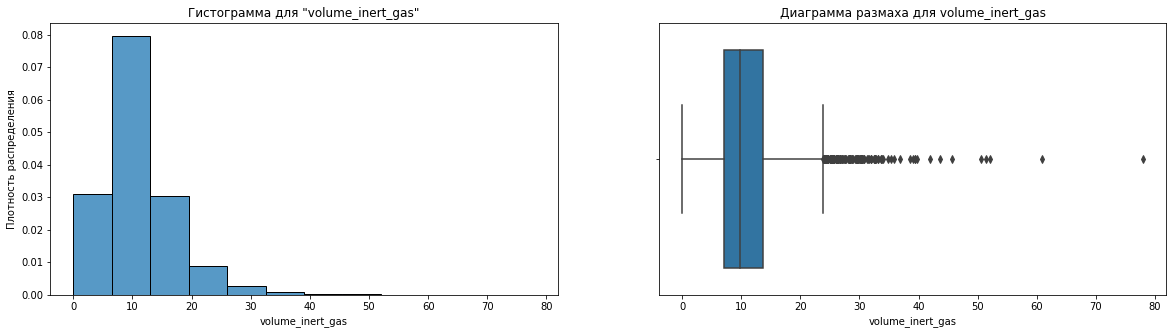

In [54]:
density_and_box(data_gas_df, 'volume_inert_gas')

In [55]:
df_high_border_box, df_low_border_box, df_filtered, df_outliers = border_box(data_gas_df, 'volume_inert_gas')

верхняя граница (high_border_box):  23.860155585675002
нижняя граница (low_border_box):  -3.0471514777250013
Количество строк датафрейма, которые попали за границы диаграммы размаха:  126
Доля строк датафрейма, которые попали за границы диаграммы размаха:  3.890089533806731 %


In [56]:
print(f'Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для volume_inert_gas:\n', 
          shapiro(data_gas_df['volume_inert_gas']))

Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для volume_inert_gas:
 ShapiroResult(statistic=0.8867924809455872, pvalue=1.14906474074635e-43)


___
Выполнили загрузку данных о продувке сплава газом `data_gas`. Выделим основные особенности:
- 3239 строк и 2 столбца
- Привели наименование столбца `Газ 1` к стандарту PEP8 (`volume_inert_gas`)
- Пропуски и явные дубликаты отсутствуют
- Значения признака за пределами усов диаграммы размаха считаем возможными и оставили как есть 
___

### Данные об измерениях температуры `data_temp`

In [57]:
# Создание датафрейма с данными из таблицы

query = '''
SELECT  *
FROM data_temp;
''' 
data_temp_df = pd.read_sql_query(query, con = engine) 

In [58]:
data_info(data_temp_df)

,key,Время замера,Температура
0,1,2019-05-03 11:02:04,1571.0
1,1,2019-05-03 11:07:18,1604.0
2,1,2019-05-03 11:11:34,1618.0
3,1,2019-05-03 11:18:04,1601.0
4,1,2019-05-03 11:25:59,1606.0


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18092 entries, 0 to 18091
Data columns (total 3 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   key           18092 non-null  int64 
 1   Время замера  18092 non-null  object
 2   Температура   14665 non-null  object
dtypes: int64(1), object(2)
memory usage: 424.2+ KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"18,092.000","1,616.461",934.641,1.000,807.750,"1,618.000","2,429.000","3,241.000"


,count,unique,top,freq
Время замера,18092,18092,2019-05-30 00:01:36,1
Температура,14665,172,1593.0,445


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
Температура,3427
key,0
Время замера,0


,0
Температура,18.94%
key,0.00%
Время замера,0.00%


___
- 18092 строки и 3 столбца
- Необходимо привести наименования столбцов к стандарту PEP8
- Для столбца `Время замера` необходимо изменить тип данных на `datetime`
- Для столбца `Температура` необходимо изменить тип данных на `float`
- В столбце `Температура` есть пропуски
___

In [59]:
# Приведение столбцов к стандарту PEP8
data_temp_df.rename(columns={'Время замера': 'temperature_measurement_time', 
                            'Температура': 'temperature'}, inplace=True)

# Изменение типа данных для столбцов, содержащих дату и время
data_temp_df['temperature_measurement_time'] = (
    pd.to_datetime(data_temp_df['temperature_measurement_time'], format='%Y-%m-%d %H:%M:%S')
)

# Изменение типа данных для столбца со значением температуры
data_temp_df['temperature'] = data_temp_df['temperature'].astype(float)

___
Заказчик предупредил, что значения температуры ниже 1500 градусов — аномальные. Удалим данные строки 
___

In [60]:
data_temp_df = data_temp_df[data_temp_df['temperature']>=1500]
data_temp_df.shape

(14660, 3)

In [61]:
data_info(data_temp_df)

,key,temperature_measurement_time,temperature
0,1,2019-05-03 11:02:04,"1,571.000"
1,1,2019-05-03 11:07:18,"1,604.000"
2,1,2019-05-03 11:11:34,"1,618.000"
3,1,2019-05-03 11:18:04,"1,601.000"
4,1,2019-05-03 11:25:59,"1,606.000"


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 14660 entries, 0 to 18086
Data columns (total 3 columns):
 #   Column                        Non-Null Count  Dtype         
---  ------                        --------------  -----         
 0   key                           14660 non-null  int64         
 1   temperature_measurement_time  14660 non-null  datetime64[ns]
 2   temperature                   14660 non-null  float64       
dtypes: datetime64[ns](1), float64(1), int64(1)
memory usage: 458.1 KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"14,660.000","1,325.369",787.408,1.000,654.000,"1,314.000","1,962.250","3,241.000"
temperature,"14,660.000","1,590.853",19.143,"1,515.000","1,580.000","1,590.000","1,599.000","1,705.000"


,count,mean,std,min,25%,50%,75%,max
key,"14,660.000","1,325.369",787.408,1.000,654.000,"1,314.000","1,962.250","3,241.000"
temperature,"14,660.000","1,590.853",19.143,"1,515.000","1,580.000","1,590.000","1,599.000","1,705.000"


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
key,0
temperature_measurement_time,0
temperature,0


,0
key,0.00%
temperature_measurement_time,0.00%
temperature,0.00%


___
Целевой признак — последняя температура партии. Начальную температуру партии можно использовать как входной признак. Любые другие промежуточные значения температуры приведут к утечке целевого признака, их нельзя использовать как входные
___

In [62]:
# Начальная и последняя температура партии
start_temperature_measurement_time = data_temp_df.sort_values(['key', 'temperature_measurement_time']).groupby('key').first()
start_temperature_measurement_time.rename(columns={'temperature_measurement_time': 'start_temperature_measurement_time', 
                                                   'temperature': 'start_temperature'}, inplace=True)

end_temperature_measurement_time = data_temp_df.sort_values(['key', 'temperature_measurement_time']).groupby('key').last()
end_temperature_measurement_time.rename(columns={'temperature_measurement_time': 'end_temperature_measurement_time', 
                                                   'temperature': 'end_temperature'}, inplace=True)

data_temp_df_agg = start_temperature_measurement_time.merge(end_temperature_measurement_time, on='key').reset_index()

In [63]:
# Добавление столбеца с расчетом длительности измерения температуры в секундах
data_temp_df_agg['duration_temperature_measurement_time'] = (
    (data_temp_df_agg['end_temperature_measurement_time'] - data_temp_df_agg['start_temperature_measurement_time']).dt.total_seconds().astype(int)
)

In [64]:
# Исключение признаков start_temperature_measurement_time и end_temperature_measurement_time
data_temp_df_agg = data_temp_df_agg.drop(['start_temperature_measurement_time', 'end_temperature_measurement_time'], axis=1)

In [65]:
# Проверка, что измерений температуры больше чем 1
len(data_temp_df_agg.query('duration_temperature_measurement_time==0'))

# Исключение из датафрейма строк с одним измерением температуры
data_temp_df_agg = data_temp_df_agg.query('duration_temperature_measurement_time>0')

In [66]:
data_info(data_temp_df_agg)

,key,start_temperature,end_temperature,duration_temperature_measurement_time
0,1,"1,571.000","1,613.000",1714
1,2,"1,581.000","1,602.000",1265
2,3,"1,596.000","1,599.000",1753
3,4,"1,601.000","1,625.000",1220
4,5,"1,576.000","1,602.000",1536


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 2475 entries, 0 to 2476
Data columns (total 4 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   key                                    2475 non-null   int64  
 1   start_temperature                      2475 non-null   float64
 2   end_temperature                        2475 non-null   float64
 3   duration_temperature_measurement_time  2475 non-null   int64  
dtypes: float64(2), int64(2)
memory usage: 96.7 KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"2,475.000","1,250.787",719.787,1.000,629.500,"1,252.000","1,872.500","2,499.000"
start_temperature,"2,475.000","1,589.030",24.998,"1,519.000","1,572.000","1,588.000","1,605.000","1,679.000"
end_temperature,"2,475.000","1,595.336",16.023,"1,541.000","1,587.000","1,593.000","1,599.000","1,700.000"
duration_temperature_measurement_time,"2,475.000","2,279.871","1,373.958",270.000,"1,544.500","2,006.000","2,738.500","23,674.000"


,count,mean,std,min,25%,50%,75%,max
key,"2,475.000","1,250.787",719.787,1.000,629.500,"1,252.000","1,872.500","2,499.000"
start_temperature,"2,475.000","1,589.030",24.998,"1,519.000","1,572.000","1,588.000","1,605.000","1,679.000"
end_temperature,"2,475.000","1,595.336",16.023,"1,541.000","1,587.000","1,593.000","1,599.000","1,700.000"
duration_temperature_measurement_time,"2,475.000","2,279.871","1,373.958",270.000,"1,544.500","2,006.000","2,738.500","23,674.000"


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
key,0
start_temperature,0
end_temperature,0
duration_temperature_measurement_time,0


,0
key,0.00%
start_temperature,0.00%
end_temperature,0.00%
duration_temperature_measurement_time,0.00%


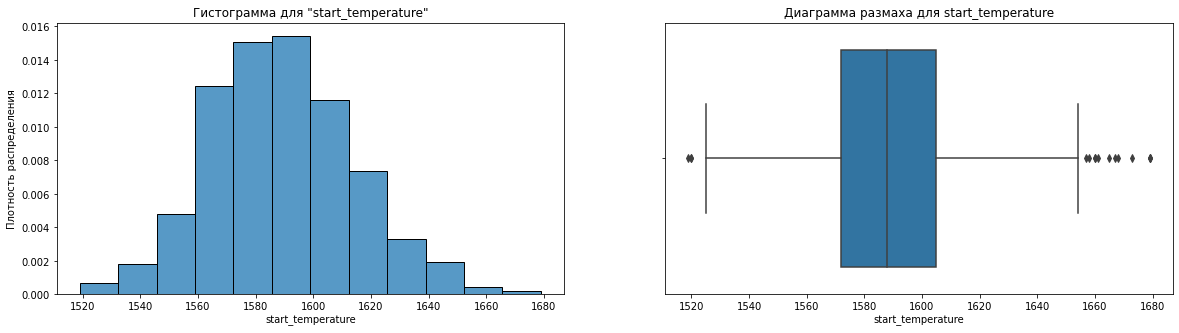

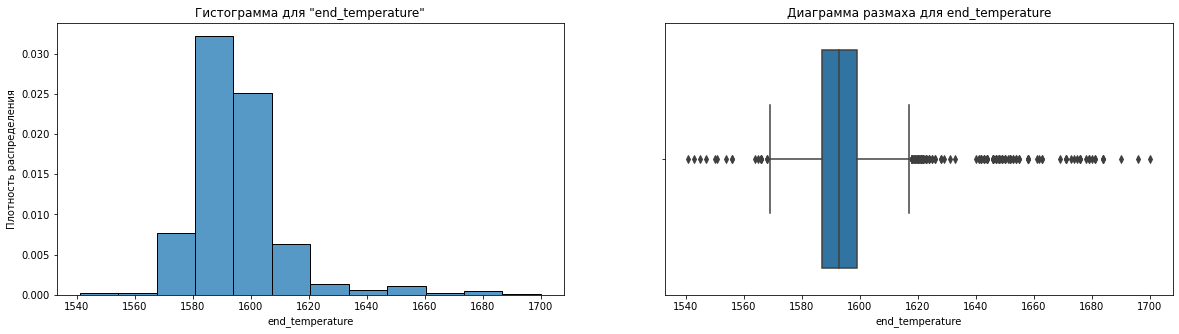

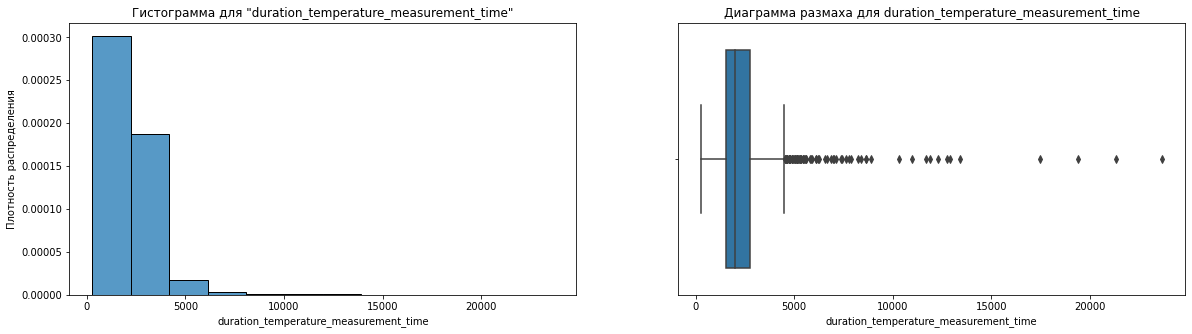

In [67]:
# Построение гистограммы и диаграммы размаха для признаков полученного датафрейма
for feature in ['start_temperature', 'end_temperature', 'duration_temperature_measurement_time']:
    density_and_box(data_temp_df_agg, feature)

In [68]:
for feature in ['start_temperature', 'end_temperature', 'duration_temperature_measurement_time']:
    print(feature)
    df_high_border_box, df_low_border_box, df_filtered, df_outliers = border_box(data_temp_df_agg, feature)
    print('-'*50)

start_temperature
верхняя граница (high_border_box):  1654.5
нижняя граница (low_border_box):  1522.5
Количество строк датафрейма, которые попали за границы диаграммы размаха:  15
Доля строк датафрейма, которые попали за границы диаграммы размаха:  0.6060606060606061 %
--------------------------------------------------
end_temperature
верхняя граница (high_border_box):  1617.0
нижняя граница (low_border_box):  1569.0
Количество строк датафрейма, которые попали за границы диаграммы размаха:  195
Доля строк датафрейма, которые попали за границы диаграммы размаха:  7.878787878787878 %
--------------------------------------------------
duration_temperature_measurement_time
верхняя граница (high_border_box):  4529.5
нижняя граница (low_border_box):  -246.5
Количество строк датафрейма, которые попали за границы диаграммы размаха:  75
Доля строк датафрейма, которые попали за границы диаграммы размаха:  3.0303030303030303 %
--------------------------------------------------


In [69]:
# Тест Шапиро-Уилка на нормальность распределения данных для количественных признаков
for feature in ['start_temperature', 'end_temperature', 'duration_temperature_measurement_time']:
    print(f'Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для {feature}:\n', 
          shapiro(data_temp_df_agg[f'{feature}']))
    print('-'*50)

Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для start_temperature:
 ShapiroResult(statistic=0.9948853254318237, pvalue=1.5519437113198364e-07)
--------------------------------------------------
Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для end_temperature:
 ShapiroResult(statistic=0.8174571990966797, pvalue=0.0)
--------------------------------------------------
Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для duration_temperature_measurement_time:
 ShapiroResult(statistic=0.6568278074264526, pvalue=0.0)
--------------------------------------------------


___
Выполнили загрузку данных об измерениях температуры `data_temp`. Выделим основные особенности:
- 18092 строки и 3 столбца
- Привели наименования столбцов к стандарту PEP8
- Для столбца `Время замера` изменили тип данных на `datetime`
- Для столбца `Температура` изменили тип данных на `float`
- В столбце `Температура` были пропуски. Исключили данные строки и строки, где значения температуры были ниже 1500 градусов как аномальные по условию заказчика.
- Дополнительно исключили строки с партиями, где было всего одно измерение температуры
- Создали датафрейм `data_temp_df_agg` (2475 строк, 6 столбцов), агрегированный по каждому номеру партии. В данный датафрейм добавили признаки:
    - Начальная `start_temperature` и последняя `end_temperature` температура партии. Последняя температура партии является целевым признаком в данном проекте.
    - Длительность измерения температуры в секундах `duration_temperature_measurement_time`
___

In [70]:
data_temp_df_agg

,key,start_temperature,end_temperature,duration_temperature_measurement_time
0,1,"1,571.000","1,613.000",1714
1,2,"1,581.000","1,602.000",1265
2,3,"1,596.000","1,599.000",1753
3,4,"1,601.000","1,625.000",1220
4,5,"1,576.000","1,602.000",1536
...,...,...,...,...
2472,2495,"1,570.000","1,591.000",1380
2473,2496,"1,554.000","1,591.000",1705
2474,2497,"1,571.000","1,589.000",962
2475,2498,"1,591.000","1,594.000",1520


### Данные об объёме проволочных материалов `data_wire`

In [71]:
# Создание датафрейма с данными из таблицы

query = '''
SELECT  *
FROM data_wire;
''' 
data_wire_df = pd.read_sql_query(query, con = engine) 

In [72]:
data_info(data_wire_df)

,key,Wire 1,Wire 2,Wire 3,Wire 4,Wire 5,Wire 6,Wire 7,Wire 8,Wire 9
0,1,60.060,None,None,None,None,None,None,None,None
1,2,96.052,None,None,None,None,None,None,None,None
2,3,91.160,None,None,None,None,None,None,None,None
3,4,89.064,None,None,None,None,None,None,None,None
4,5,89.238,9.11456,None,None,None,None,None,None,None


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   key     3081 non-null   int64  
 1   Wire 1  3055 non-null   float64
 2   Wire 2  1079 non-null   object 
 3   Wire 3  63 non-null     object 
 4   Wire 4  14 non-null     object 
 5   Wire 5  1 non-null      object 
 6   Wire 6  73 non-null     object 
 7   Wire 7  11 non-null     object 
 8   Wire 8  19 non-null     object 
 9   Wire 9  29 non-null     object 
dtypes: float64(1), int64(1), object(8)
memory usage: 240.8+ KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"3,081.000","1,623.426",932.997,1.000,823.000,"1,619.000","2,434.000","3,241.000"
Wire 1,"3,055.000",100.896,42.013,1.919,72.116,100.158,126.060,330.314


,count,unique,top,freq
Wire 2,1079,713,30.09968,20
Wire 3,63,56,93.165077,3
Wire 4,14,14,43.065361,1
Wire 5,1,1,15.132,1
Wire 6,73,69,18.086641,2
Wire 7,11,10,12.354473,2
Wire 8,19,13,46.187439000000005,3
Wire 9,29,25,30.066399,3


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
Wire 5,3080
Wire 7,3070
Wire 4,3067
Wire 8,3062
Wire 9,3052
Wire 3,3018
Wire 6,3008
Wire 2,2002
Wire 1,26
key,0


,0
Wire 5,99.97%
Wire 7,99.64%
Wire 4,99.55%
Wire 8,99.38%
Wire 9,99.06%
Wire 3,97.96%
Wire 6,97.63%
Wire 2,64.98%
Wire 1,0.84%
key,0.00%


___
- 3081 строка и 10 столбцов
- Необходимо привести наименования столбцов к стандарту PEP8
- Для столбцов `Wire 2`...`Wire 5` необходимо изменить тип данных на `float`
- Во всех столбцах, кроме `key` есть пропуски. Пропуск по условию заказчика означает, что материал не добавляли в партию. 
___

In [73]:
# Приведение столбцов к стандарту PEP8
data_wire_df.columns = data_wire_df.columns.str.lower().str.replace(' ', '_')

# Изменение типа данных для столбцов Bulk 5...Bulk 15
for feature in [x for x in data_wire_df.columns if x!='key']:
    data_wire_df[feature] = data_wire_df[feature].astype('float')

In [74]:
# Добавление столбца с расчетом суммы объёма подаваемого материала
data_wire_df['wire_total'] = data_wire_df[list(data_wire_df.drop('key', axis=1).columns)].sum(axis=1)

# Добавление столбца с расчетом количества раз, когда подавали материал
data_wire_df['wire_count'] = data_wire_df[list(data_wire_df.drop(['key', 'wire_total'], axis=1).columns)].count(axis=1)

data_wire_df.head()

,key,wire_1,wire_2,wire_3,wire_4,wire_5,wire_6,wire_7,wire_8,wire_9,wire_total,wire_count
0,1,60.060,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,60.060,1
1,2,96.052,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,96.052,1
2,3,91.160,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,91.160,1
3,4,89.064,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.064,1
4,5,89.238,9.115,NaN,NaN,NaN,NaN,NaN,NaN,NaN,98.353,2


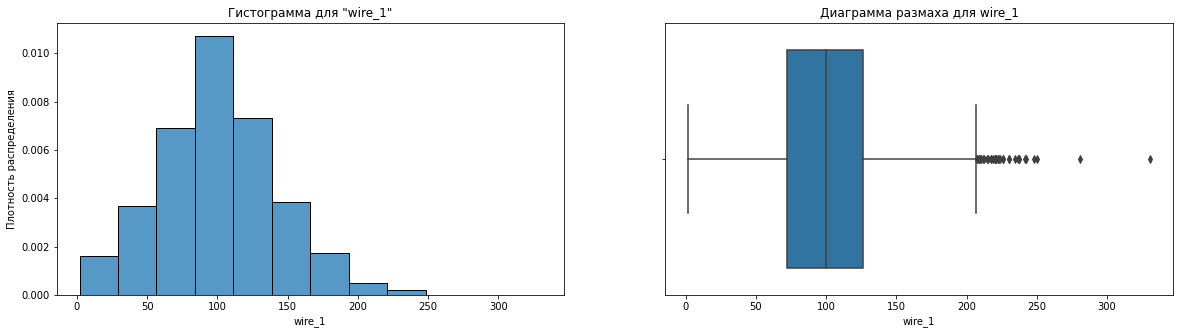

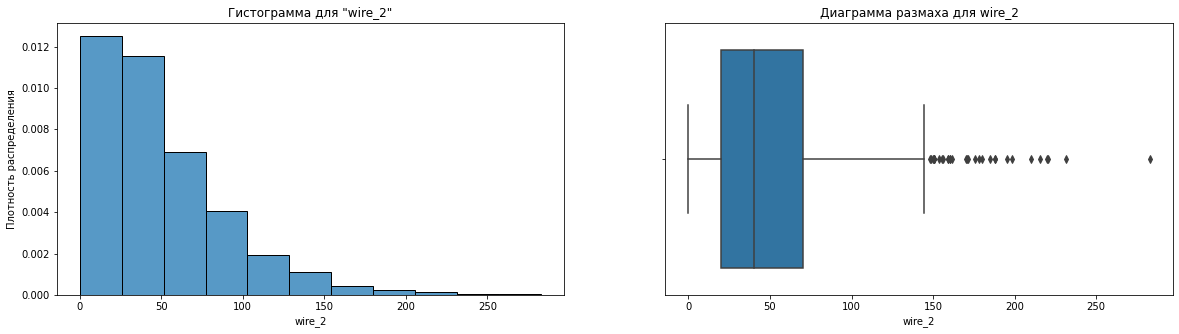

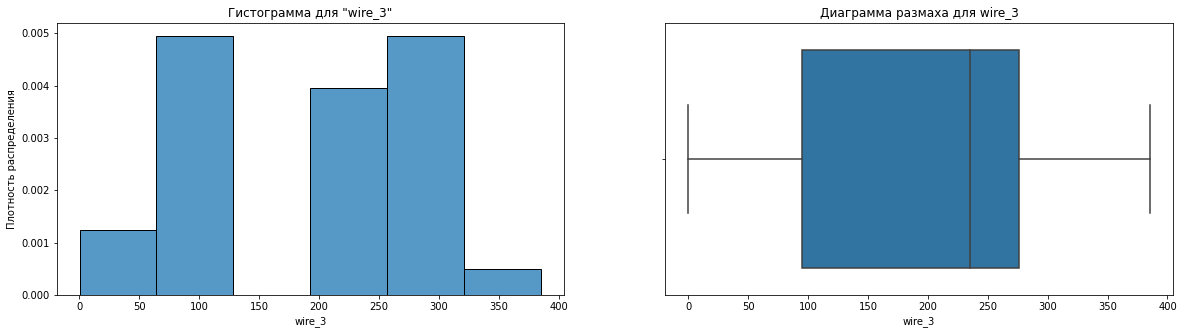

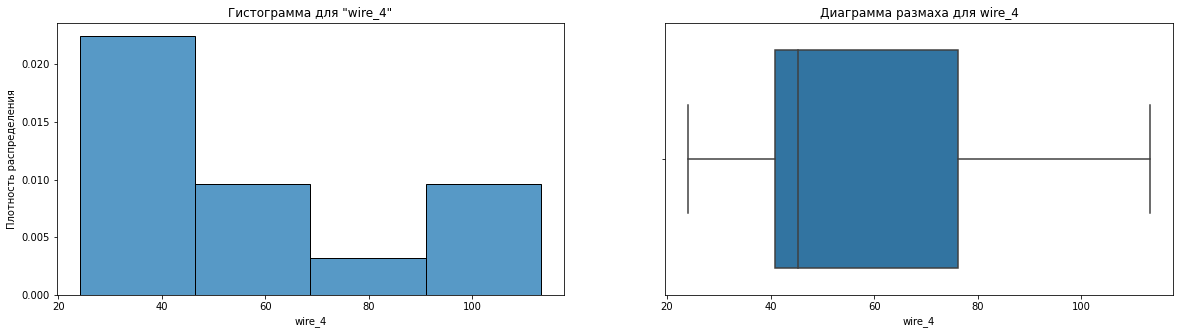

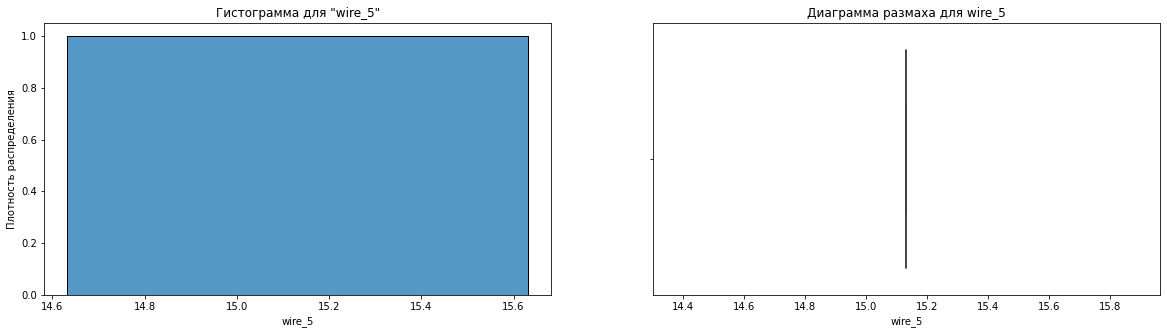

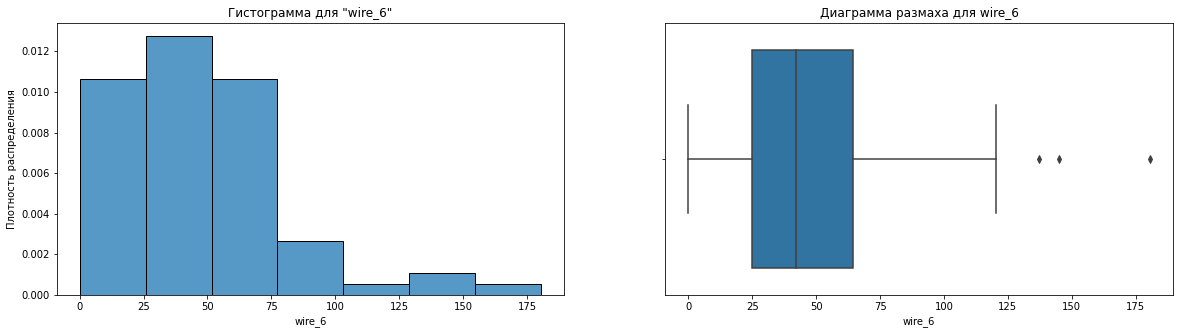

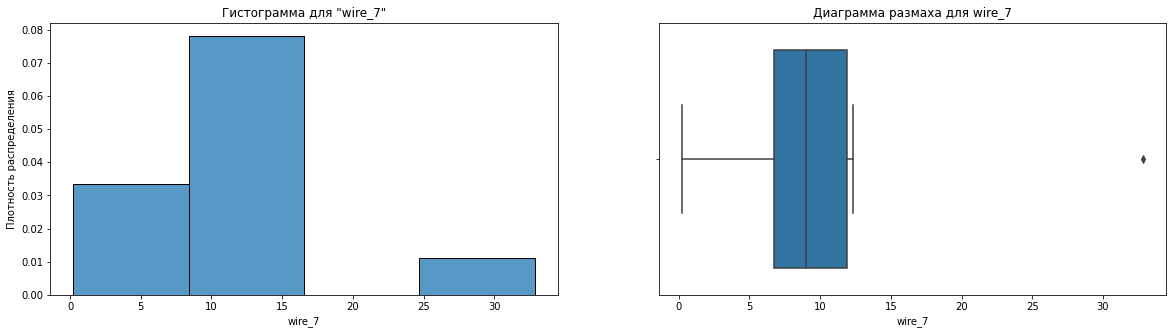

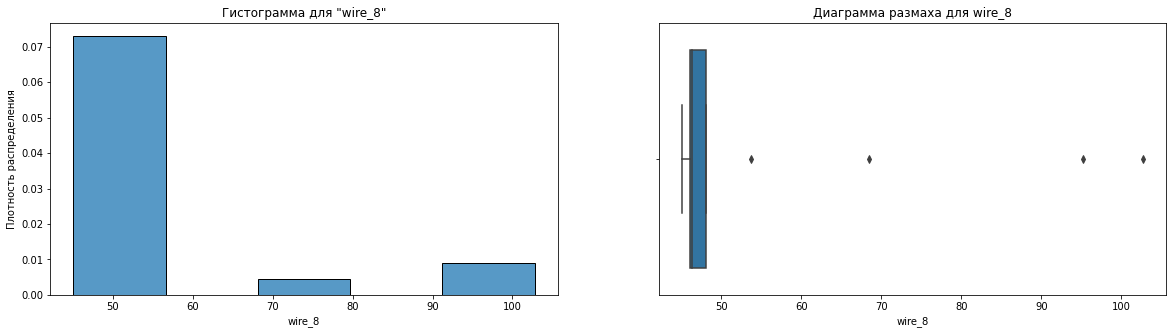

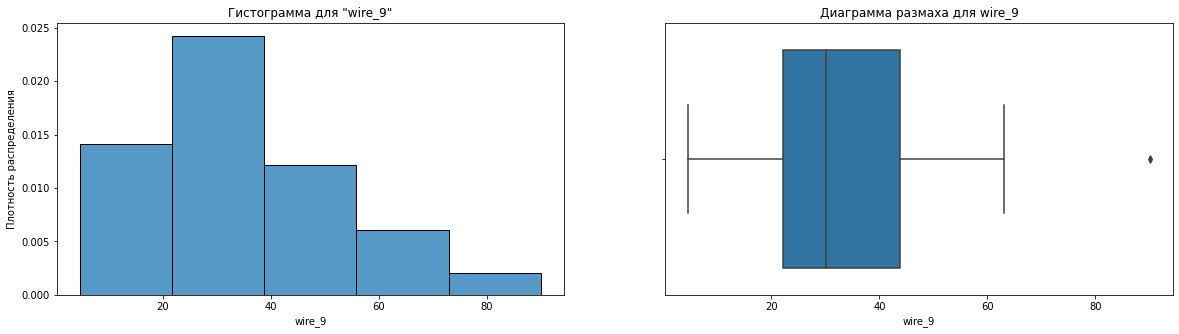

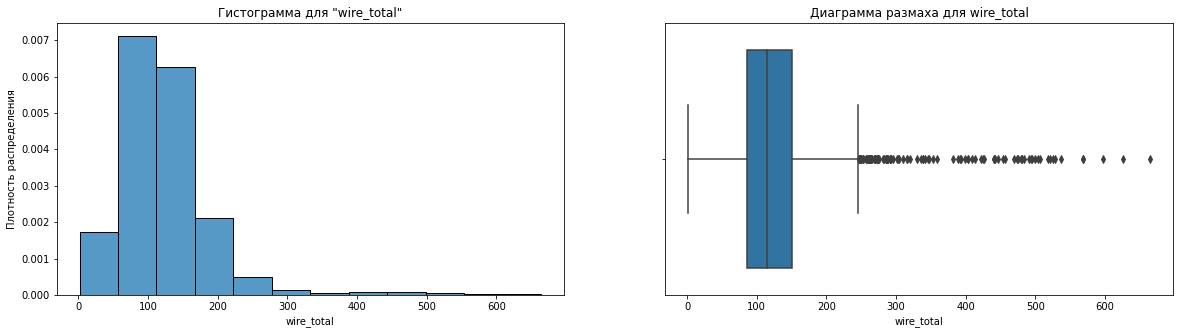

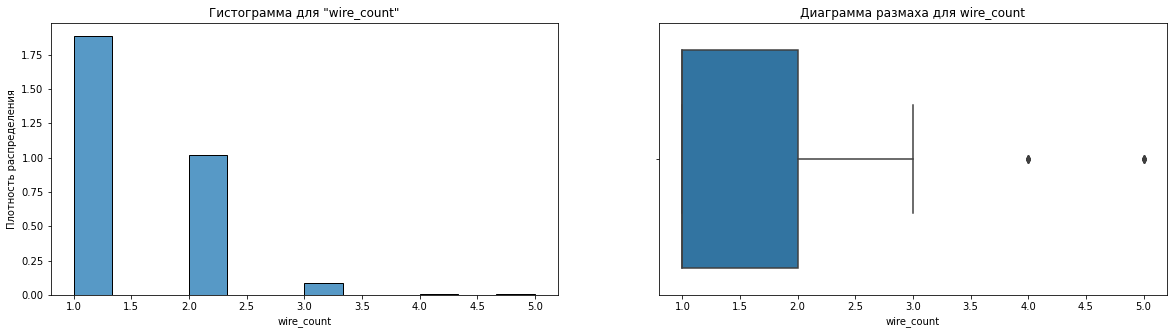

In [75]:
# Построение гистограммы и диаграммы размаха для признаков полученного датафрейма
for feature in [x for x in data_wire_df.columns if x!='key']:
    density_and_box(data_wire_df, feature)

In [76]:
for feature in [x for x in data_wire_df.columns if x!='key']:
    print(feature)
    df_high_border_box, df_low_border_box, df_filtered, df_outliers = border_box(data_wire_df, feature)
    print('-'*50)

wire_1
верхняя граница (high_border_box):  206.97768274999999
нижняя граница (low_border_box):  -8.80151524999998
Количество строк датафрейма, которые попали за границы диаграммы размаха:  36
Доля строк датафрейма, которые попали за границы диаграммы размаха:  1.1684518013631937 %
--------------------------------------------------
wire_2
верхняя граница (high_border_box):  145.27837499999998
нижняя граница (low_border_box):  -54.857136999999994
Количество строк датафрейма, которые попали за границы диаграммы размаха:  32
Доля строк датафрейма, которые попали за границы диаграммы размаха:  1.03862382343395 %
--------------------------------------------------
wire_3
верхняя граница (high_border_box):  547.9274702499999
нижняя граница (low_border_box):  -176.54041174999998
Количество строк датафрейма, которые попали за границы диаграммы размаха:  0
Доля строк датафрейма, которые попали за границы диаграммы размаха:  0.0 %
--------------------------------------------------
wire_4
верхняя г

In [77]:
data_wire_df_agg = data_wire_df[['key', 'wire_total', 'wire_count']]
data_info(data_wire_df_agg)

,key,wire_total,wire_count
0,1,60.060,1
1,2,96.052,1
2,3,91.160,1
3,4,89.064,1
4,5,98.353,2


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   key         3081 non-null   int64  
 1   wire_total  3081 non-null   float64
 2   wire_count  3081 non-null   int64  
dtypes: float64(1), int64(2)
memory usage: 72.3 KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"3,081.000","1,623.426",932.997,1.000,823.000,"1,619.000","2,434.000","3,241.000"
wire_total,"3,081.000",123.723,66.083,1.919,86.112,114.180,150.181,663.852
wire_count,"3,081.000",1.410,0.578,1.000,1.000,1.000,2.000,5.000


,count,mean,std,min,25%,50%,75%,max
key,"3,081.000","1,623.426",932.997,1.000,823.000,"1,619.000","2,434.000","3,241.000"
wire_total,"3,081.000",123.723,66.083,1.919,86.112,114.180,150.181,663.852
wire_count,"3,081.000",1.410,0.578,1.000,1.000,1.000,2.000,5.000


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
key,0
wire_total,0
wire_count,0


,0
key,0.00%
wire_total,0.00%
wire_count,0.00%


___
Выполнили загрузку данных об объёме проволочных материалов `data_wire`. Выделим основные особенности:
- 3081 строка и 10 столбцов
- Привели наименования столбцов к стандарту PEP8
- Для столбцов `Wire 2`...`Wire 5` изменили тип данных на `float`
- Во всех столбцах, кроме `key` есть пропуски. Пропуск по условию заказчика означает, что материал не добавляли в партию. Оставили их как есть, но добавили столбец `wire_total` с расчетом суммы объёма подаваемого материала. Дополнительно добавили столбец `wire_count` с расчетом количества раз, когда подавали материал. В модели будем использовать именно эти два признака, которые выделили в датафрейме `data_wire_df_agg` 
- Значения признаков за пределами усов диаграммы размаха считаем возможными и оставили как есть 
___

### Данные о времени подачи проволочных материалов `data_wire_time`

In [78]:
# Создание датафрейма с данными из таблицы

query = '''
SELECT  *
FROM data_wire_time;
''' 
data_wire_time_df = pd.read_sql_query(query, con = engine) 

In [79]:
data_info(data_wire_time_df)

,key,Wire 1,Wire 2,Wire 3,Wire 4,Wire 5,Wire 6,Wire 7,Wire 8,Wire 9
0,1,2019-05-03 11:06:19,None,None,None,None,None,None,None,None
1,2,2019-05-03 11:36:50,None,None,None,None,None,None,None,None
2,3,2019-05-03 12:11:46,None,None,None,None,None,None,None,None
3,4,2019-05-03 12:43:22,None,None,None,None,None,None,None,None
4,5,2019-05-03 13:20:44,2019-05-03 13:15:34,None,None,None,None,None,None,None


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   key     3081 non-null   int64 
 1   Wire 1  3055 non-null   object
 2   Wire 2  1079 non-null   object
 3   Wire 3  63 non-null     object
 4   Wire 4  14 non-null     object
 5   Wire 5  1 non-null      object
 6   Wire 6  73 non-null     object
 7   Wire 7  11 non-null     object
 8   Wire 8  19 non-null     object
 9   Wire 9  29 non-null     object
dtypes: int64(1), object(9)
memory usage: 240.8+ KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"3,081.000","1,623.426",932.997,1.000,823.000,"1,619.000","2,434.000","3,241.000"


,count,unique,top,freq
Wire 1,3055,3055,2019-07-07 16:35:32,1
Wire 2,1079,1079,2019-08-20 03:45:26,1
Wire 3,63,63,2019-06-12 14:38:14,1
Wire 4,14,14,2019-07-20 16:11:26,1
Wire 5,1,1,2019-08-13 06:14:30,1
Wire 6,73,73,2019-05-08 09:01:22,1
Wire 7,11,11,2019-08-13 01:13:45,1
Wire 8,19,19,2019-08-16 05:36:19,1
Wire 9,29,29,2019-08-09 09:11:30,1


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
Wire 5,3080
Wire 7,3070
Wire 4,3067
Wire 8,3062
Wire 9,3052
Wire 3,3018
Wire 6,3008
Wire 2,2002
Wire 1,26
key,0


,0
Wire 5,99.97%
Wire 7,99.64%
Wire 4,99.55%
Wire 8,99.38%
Wire 9,99.06%
Wire 3,97.96%
Wire 6,97.63%
Wire 2,64.98%
Wire 1,0.84%
key,0.00%


___
- 3081 строка и 10 столбцов
- Необходимо привести наименования столбцов к стандарту PEP8
- Для столбцов `Wire 1`...`Wire 9` необходимо изменить тип данных на `datetime`
- Во всех столбцах, кроме `key` есть пропуски. Пропуск по условию заказчика означает, что материал не добавляли в партию. 
___

In [80]:
# Приведение столбцов к стандарту PEP8
data_wire_time_df.columns = data_wire_time_df.columns.str.lower().str.replace(' ', '_')

# Изменение типа данных 
for feature in [x for x in data_wire_time_df.columns if x!='key']:
    data_wire_time_df[feature] = pd.to_datetime(data_wire_time_df[feature], format='%Y-%m-%d %H:%M:%S')
    
data_info(data_wire_time_df)

,key,wire_1,wire_2,wire_3,wire_4,wire_5,wire_6,wire_7,wire_8,wire_9
0,1,2019-05-03 11:06:19,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
1,2,2019-05-03 11:36:50,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
2,3,2019-05-03 12:11:46,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
3,4,2019-05-03 12:43:22,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT
4,5,2019-05-03 13:20:44,2019-05-03 13:15:34,NaT,NaT,NaT,NaT,NaT,NaT,NaT


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   key     3081 non-null   int64         
 1   wire_1  3055 non-null   datetime64[ns]
 2   wire_2  1079 non-null   datetime64[ns]
 3   wire_3  63 non-null     datetime64[ns]
 4   wire_4  14 non-null     datetime64[ns]
 5   wire_5  1 non-null      datetime64[ns]
 6   wire_6  73 non-null     datetime64[ns]
 7   wire_7  11 non-null     datetime64[ns]
 8   wire_8  19 non-null     datetime64[ns]
 9   wire_9  29 non-null     datetime64[ns]
dtypes: datetime64[ns](9), int64(1)
memory usage: 240.8 KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"3,081.000","1,623.426",932.997,1.000,823.000,"1,619.000","2,434.000","3,241.000"


,count,mean,std,min,25%,50%,75%,max
key,"3,081.000","1,623.426",932.997,1.000,823.000,"1,619.000","2,434.000","3,241.000"


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
wire_5,3080
wire_7,3070
wire_4,3067
wire_8,3062
wire_9,3052
wire_3,3018
wire_6,3008
wire_2,2002
wire_1,26
key,0


,0
wire_5,99.97%
wire_7,99.64%
wire_4,99.55%
wire_8,99.38%
wire_9,99.06%
wire_3,97.96%
wire_6,97.63%
wire_2,64.98%
wire_1,0.84%
key,0.00%


Выполним проверку, что подача материала не измеряется сутками. Для этого добавим столбец в котором посчитаем разницу в секундах между первым и последним добавлением материала

In [81]:
# Добавление столбца с расчетом разницы в секундах между первым и последним добавлением материала
data_wire_time_df['wire_duration'] = (
    (data_wire_time_df.drop('key', axis=1).apply(lambda row: (row.max() - row.min()).total_seconds(), axis=1)).astype(int)
)

data_wire_time_df.head()

,key,wire_1,wire_2,wire_3,wire_4,wire_5,wire_6,wire_7,wire_8,wire_9,wire_duration
0,1,2019-05-03 11:06:19,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,0
1,2,2019-05-03 11:36:50,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,0
2,3,2019-05-03 12:11:46,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,0
3,4,2019-05-03 12:43:22,NaT,NaT,NaT,NaT,NaT,NaT,NaT,NaT,0
4,5,2019-05-03 13:20:44,2019-05-03 13:15:34,NaT,NaT,NaT,NaT,NaT,NaT,NaT,310


In [82]:
data_wire_time_df_agg = data_wire_time_df[['key', 'wire_duration']]
display(data_wire_time_df_agg.sort_values(by='wire_duration', ascending=False).head())
print(f'Максимальная разница между первым и последним добавлением материала в часах: {round(data_wire_time_df_agg["wire_duration"].max()/3600, 1)}')

,key,wire_duration
2012,2110,5937
2010,2108,5492
2439,2566,5013
2440,2567,3578
97,113,3477


Максимальная разница между первым и последним добавлением материала в часах: 1.6


In [83]:
data_info(data_wire_time_df_agg)

,key,wire_duration
0,1,0
1,2,0
2,3,0
3,4,0
4,5,310


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3081 entries, 0 to 3080
Data columns (total 2 columns):
 #   Column         Non-Null Count  Dtype
---  ------         --------------  -----
 0   key            3081 non-null   int64
 1   wire_duration  3081 non-null   int64
dtypes: int64(2)
memory usage: 48.3 KB
--------------------------------------------------
Количество явных дубликатов: 0
% явных дубликатов в полученном датафрейме: 0.0 %
--------------------------------------------------
Числовое описание данных:


,count,mean,std,min,25%,50%,75%,max
key,"3,081.000","1,623.426",932.997,1.000,823.000,"1,619.000","2,434.000","3,241.000"
wire_duration,"3,081.000",214.519,396.132,0.000,0.000,0.000,401.000,"5,937.000"


,count,mean,std,min,25%,50%,75%,max
key,"3,081.000","1,623.426",932.997,1.000,823.000,"1,619.000","2,434.000","3,241.000"
wire_duration,"3,081.000",214.519,396.132,0.000,0.000,0.000,401.000,"5,937.000"


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
key,0
wire_duration,0


,0
key,0.00%
wire_duration,0.00%


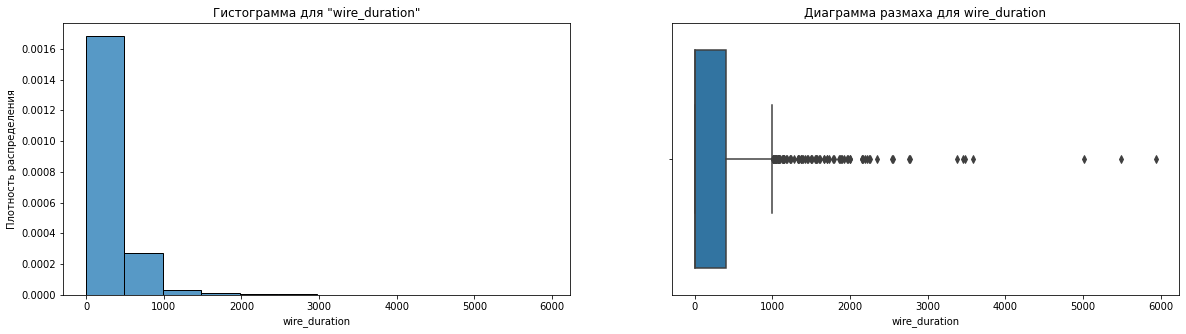

In [84]:
density_and_box(data_wire_time_df_agg, 'wire_duration')

In [85]:
df_high_border_box, df_low_border_box, df_filtered, df_outliers = border_box(data_wire_time_df_agg, 'wire_duration')

верхняя граница (high_border_box):  1002.5
нижняя граница (low_border_box):  -601.5
Количество строк датафрейма, которые попали за границы диаграммы размаха:  94
Доля строк датафрейма, которые попали за границы диаграммы размаха:  3.050957481337228 %


In [86]:
print(f'Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для bulk_duration:\n', 
          shapiro(data_wire_time_df_agg['wire_duration']))

Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для bulk_duration:
 ShapiroResult(statistic=0.5709046125411987, pvalue=0.0)


___
Выполнили загрузку данных о времени подачи проволочных материалов `data_wire_time`. Выделим основные особенности:
- 3081 строка и 10 столбцов
- Привели наименования столбцов к стандарту PEP8
- Для столбцов `Wire 1`...`Wire 9` изменили тип данных на `datetime`
- Во всех столбцах, кроме `key` есть пропуски. Пропуск по условию заказчика означает, что материал не добавляли в партию. Оставили их как есть, но добавили столбец `wire_duration` с расчетом разницы в секундах между первым и последним добавлением материала. В модели будем использовать именно этот признак, который выделили в датафрейме `data_wire_time_df_agg`
- Значения признаков за пределами усов диаграммы размаха считаем возможными и оставили как есть 
___

### Объединение таблиц

Бизнес-информация:
- Каждой партии должно соответствовать одно наблюдение.
- Во все партии точно добавлялись сыпучие и проволочные материалы, везде была выполнена продувка газом и сплав всегда нагревался.


Перечень предобработанных таблиц:

| **Датафрейм**| **Описание**                      |**Размеры датафрейма (строк, столбцов)**|
|:-------------------------|:------------------------------|:------------------------|
| `data_arc_df_agg`                 |Данные об электродах  |(3214, 10)  |
| `data_bulk_df_agg`                 |Данные об объёме сыпучих материалов  |(3129, 3)  |
| `data_bulk_time_df_agg`                 |Данные о времени подачи сыпучих материалов  |(3129, 2)  |
| `data_gas_df`                 |Данные о продувке сплава газом  |(3239, 2)  |
| `data_temp_df_agg`                 |Данные об измерениях температуры  |(2475, 4) |
| `data_wire_df_agg`                 |Данные об объёме проволочных материало  |(3081, 3)  |
| `data_wire_time_df_agg`                 |Данные о времени подачи проволочных материалов  |(3081, 2)  |


In [87]:
final_df = (
    data_temp_df_agg
        .merge(data_arc_df_agg, on='key', how='inner')
        .merge(data_bulk_df_agg, on='key', how='inner')
        .merge(data_bulk_time_df_agg, on='key', how='inner')
        .merge(data_gas_df, on='key', how='inner')
        .merge(data_wire_df_agg, on='key', how='inner')
        .merge(data_wire_time_df_agg, on='key', how='inner')
)

data_info(final_df)

,key,start_temperature,end_temperature,duration_temperature_measurement_time,heating_time,max_heating_time_cycles,mean_heating_time_cycles,count_heating_cycles,total_active_power,total_reactive_power,total_power,power_factor,work_active_power,bulk_total,bulk_count,bulk_duration,volume_inert_gas,wire_total,wire_count,wire_duration
0,1,"1,571.000","1,613.000",1714,1098,365,219.600,5,3.037,2.143,3.717,0.817,"3,334.330",553.000,4,1085,29.750,60.060,1,0
1,2,"1,581.000","1,602.000",1265,811,338,202.750,4,2.139,1.453,2.586,0.827,"1,735.060",582.000,4,1000,12.556,96.052,1,0
2,3,"1,596.000","1,599.000",1753,655,280,131.000,5,4.064,2.937,5.014,0.810,"2,661.685",544.000,4,983,28.555,91.160,1,0
3,4,"1,601.000","1,625.000",1220,741,278,185.250,4,2.706,2.057,3.399,0.796,"2,005.508",595.000,4,878,18.841,89.064,1,0
4,5,"1,576.000","1,602.000",1536,869,415,217.250,4,2.253,1.688,2.815,0.800,"1,957.814",584.000,4,205,5.414,98.353,2,310


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 2325 entries, 0 to 2324
Data columns (total 20 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   key                                    2325 non-null   int64  
 1   start_temperature                      2325 non-null   float64
 2   end_temperature                        2325 non-null   float64
 3   duration_temperature_measurement_time  2325 non-null   int64  
 4   heating_time                           2325 non-null   int64  
 5   max_heating_time_cycles                2325 non-null   int64  
 6   mean_heating_time_cycles               2325 non-null   float64
 7   count_heating_cycles                   2325 non-null   int64  
 8   total_active_power                     2325 non-null   float64
 9   total_reactive_power                   2325 non-null   

,count,mean,std,min,25%,50%,75%,max
key,"2,325.000","1,252.121",714.634,1.000,631.000,"1,255.000","1,868.000","2,499.000"
start_temperature,"2,325.000","1,587.354",23.593,"1,519.000","1,571.000","1,587.000","1,603.000","1,660.000"
end_temperature,"2,325.000","1,593.345",11.189,"1,541.000","1,587.000","1,593.000","1,598.000","1,653.000"
duration_temperature_measurement_time,"2,325.000","2,310.428","1,310.055",270.000,"1,579.000","2,045.000","2,790.000","21,331.000"
heating_time,"2,325.000",805.249,331.483,57.000,581.000,778.000,992.000,"2,919.000"
max_heating_time_cycles,"2,325.000",289.295,106.441,57.000,212.000,276.000,339.000,780.000
mean_heating_time_cycles,"2,325.000",171.968,43.706,57.000,141.000,169.400,198.500,378.000
count_heating_cycles,"2,325.000",4.687,1.584,1.000,4.000,5.000,6.000,16.000
total_active_power,"2,325.000",3.118,1.199,0.268,2.294,3.032,3.830,11.632
total_reactive_power,"2,325.000",2.295,0.889,0.196,1.670,2.224,2.826,8.573


,count,mean,std,min,25%,50%,75%,max
key,"2,325.000","1,252.121",714.634,1.000,631.000,"1,255.000","1,868.000","2,499.000"
start_temperature,"2,325.000","1,587.354",23.593,"1,519.000","1,571.000","1,587.000","1,603.000","1,660.000"
end_temperature,"2,325.000","1,593.345",11.189,"1,541.000","1,587.000","1,593.000","1,598.000","1,653.000"
duration_temperature_measurement_time,"2,325.000","2,310.428","1,310.055",270.000,"1,579.000","2,045.000","2,790.000","21,331.000"
heating_time,"2,325.000",805.249,331.483,57.000,581.000,778.000,992.000,"2,919.000"
max_heating_time_cycles,"2,325.000",289.295,106.441,57.000,212.000,276.000,339.000,780.000
mean_heating_time_cycles,"2,325.000",171.968,43.706,57.000,141.000,169.400,198.500,378.000
count_heating_cycles,"2,325.000",4.687,1.584,1.000,4.000,5.000,6.000,16.000
total_active_power,"2,325.000",3.118,1.199,0.268,2.294,3.032,3.830,11.632
total_reactive_power,"2,325.000",2.295,0.889,0.196,1.670,2.224,2.826,8.573


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
key,0
start_temperature,0
wire_count,0
wire_total,0
volume_inert_gas,0
bulk_duration,0
bulk_count,0
bulk_total,0
work_active_power,0
power_factor,0


,0
key,0.00%
start_temperature,0.00%
wire_count,0.00%
wire_total,0.00%
volume_inert_gas,0.00%
bulk_duration,0.00%
bulk_count,0.00%
bulk_total,0.00%
work_active_power,0.00%
power_factor,0.00%


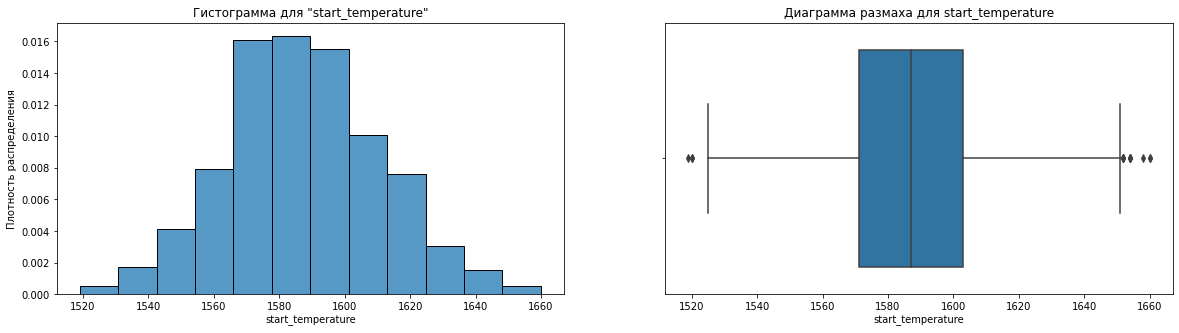

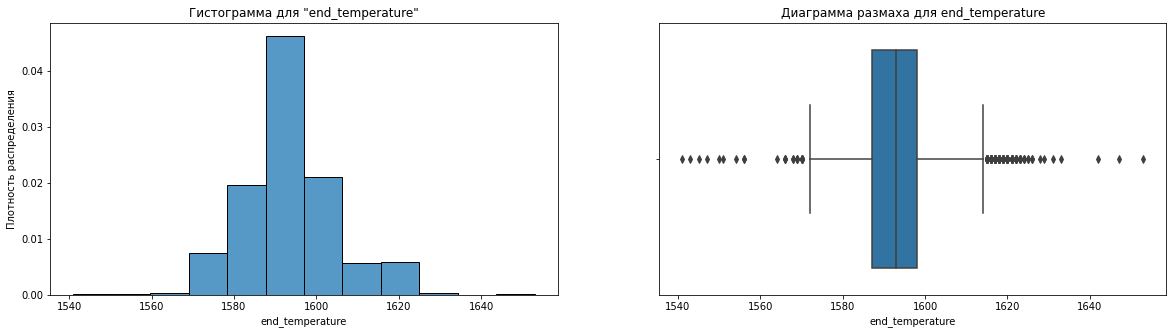

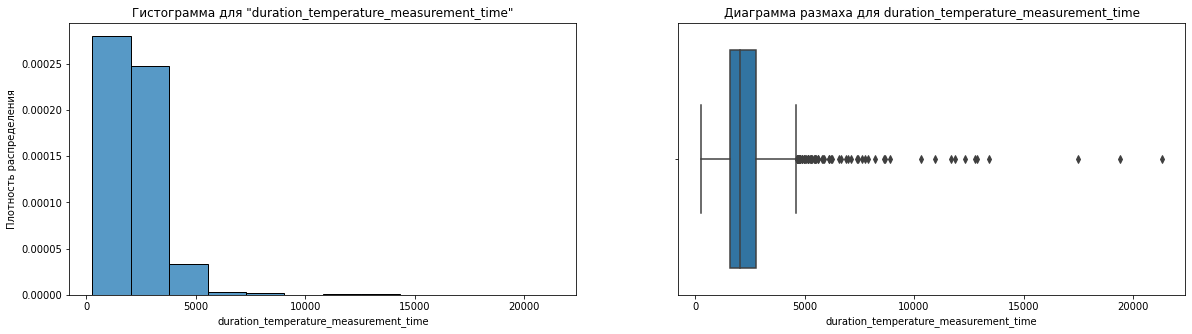

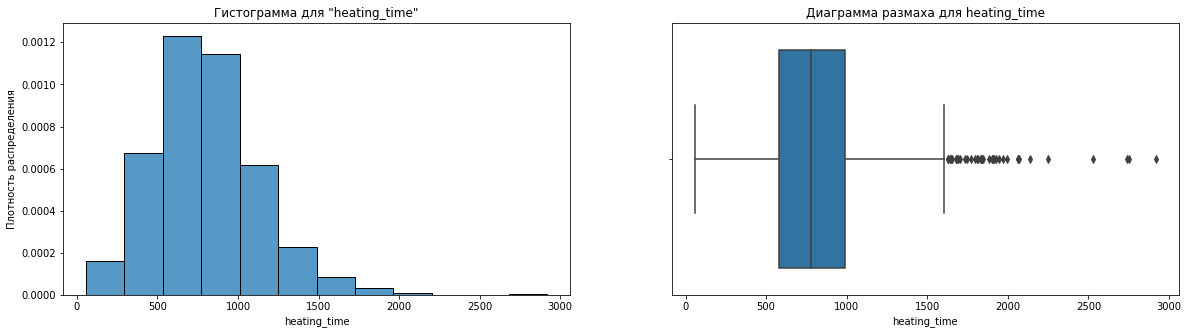

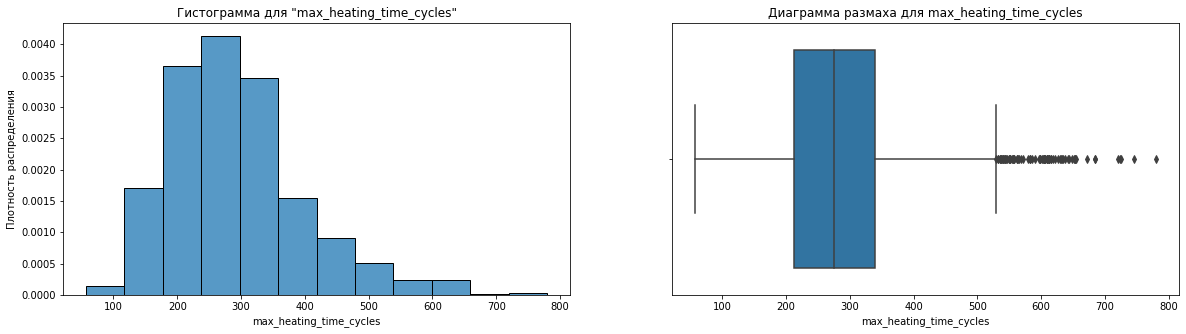

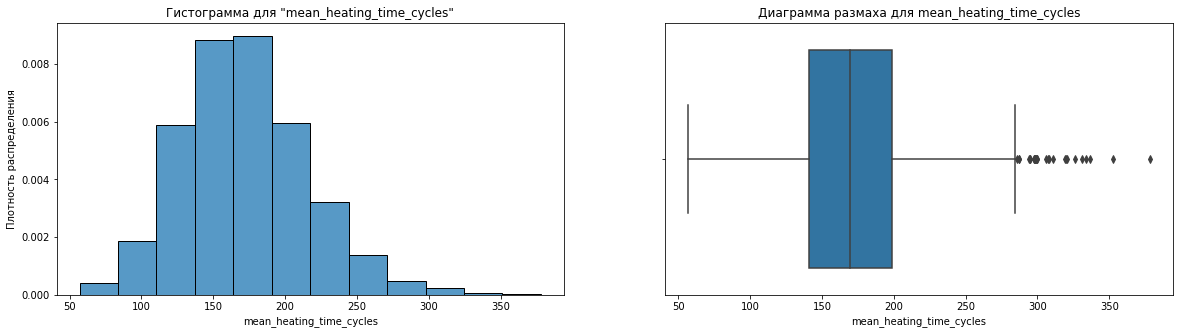

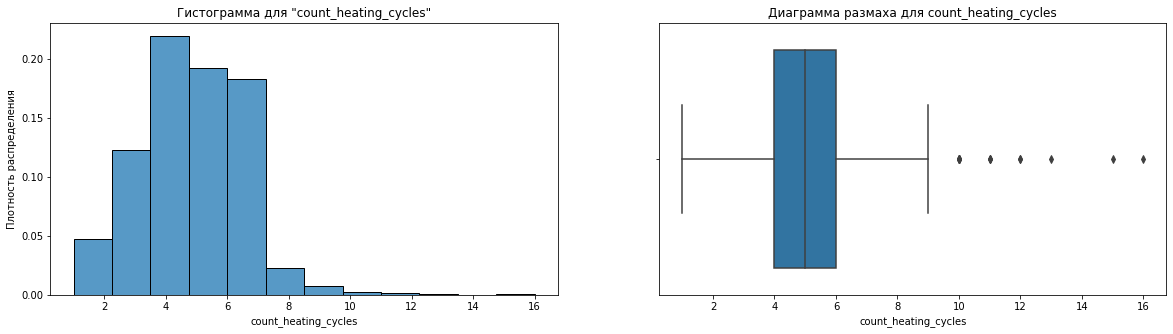

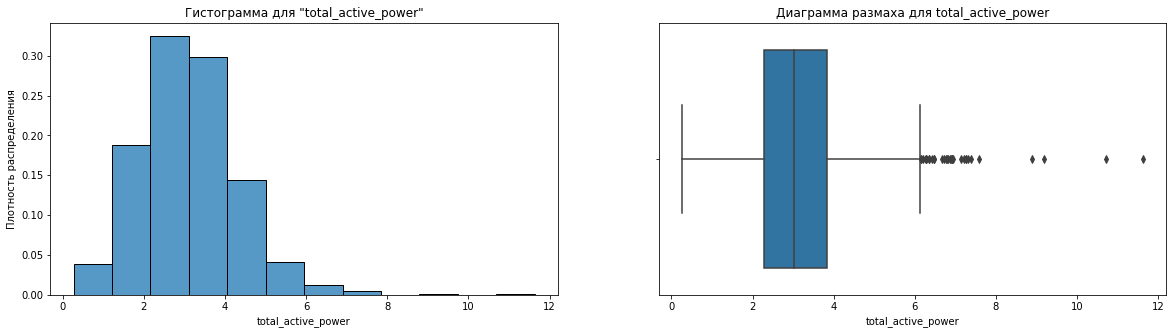

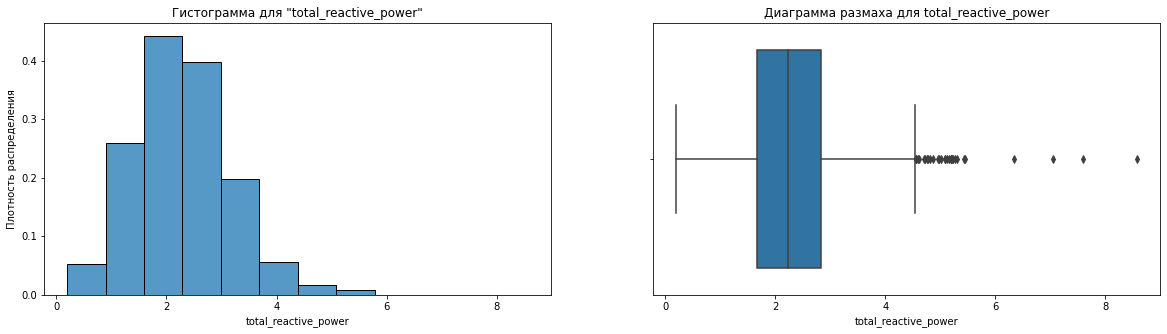

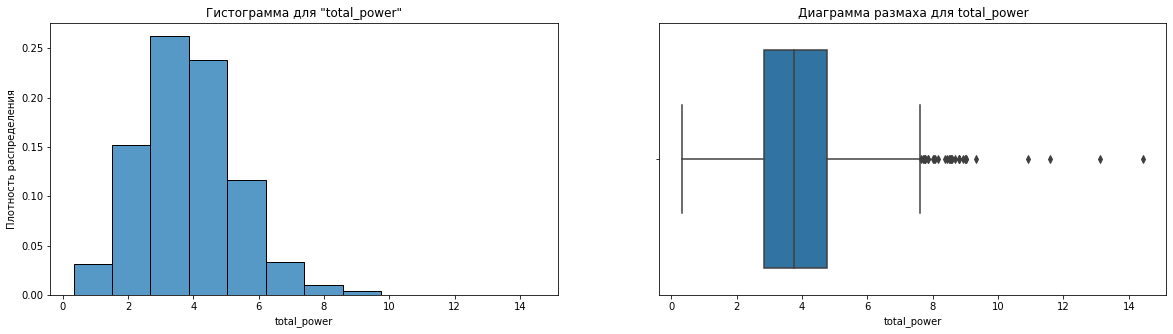

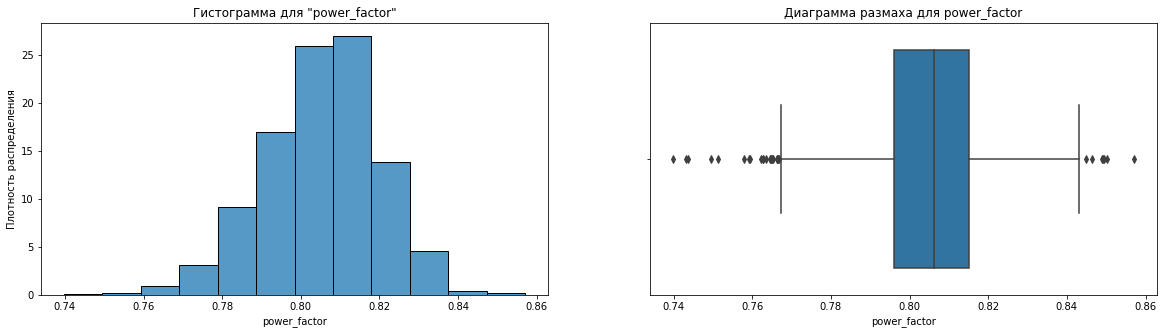

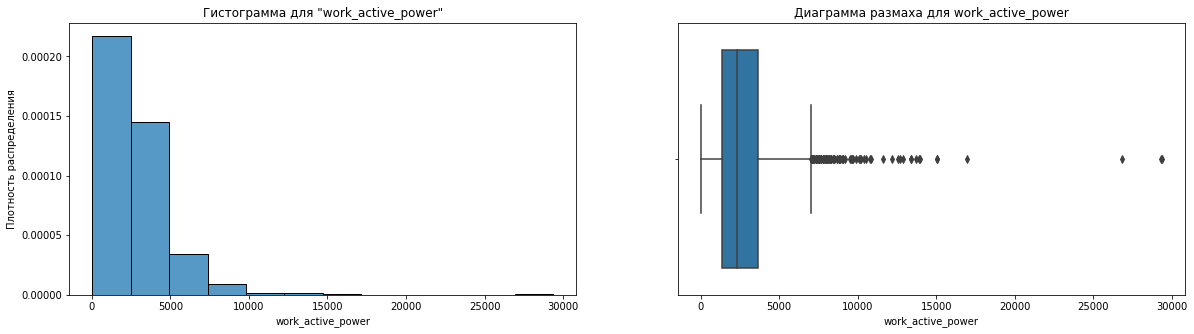

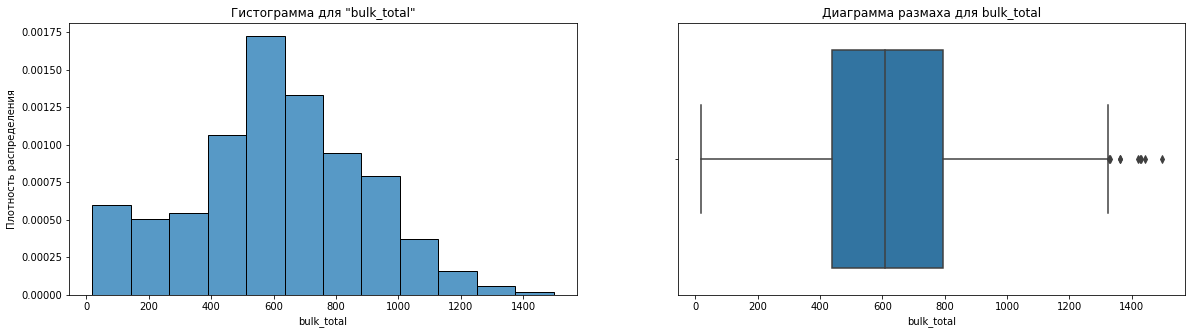

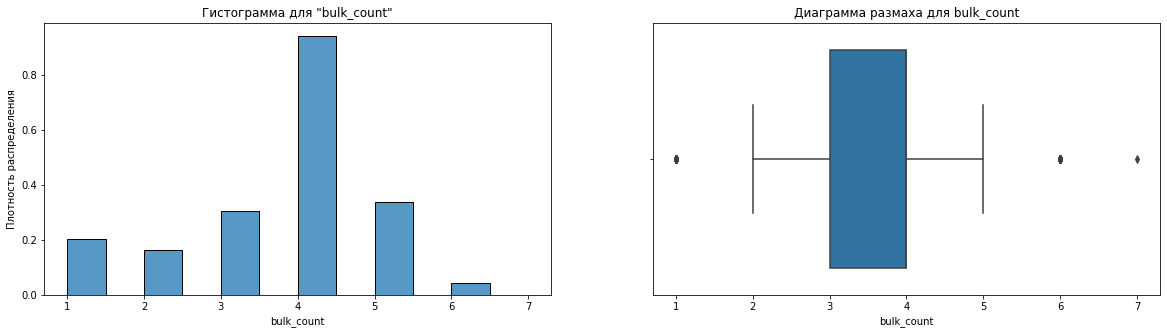

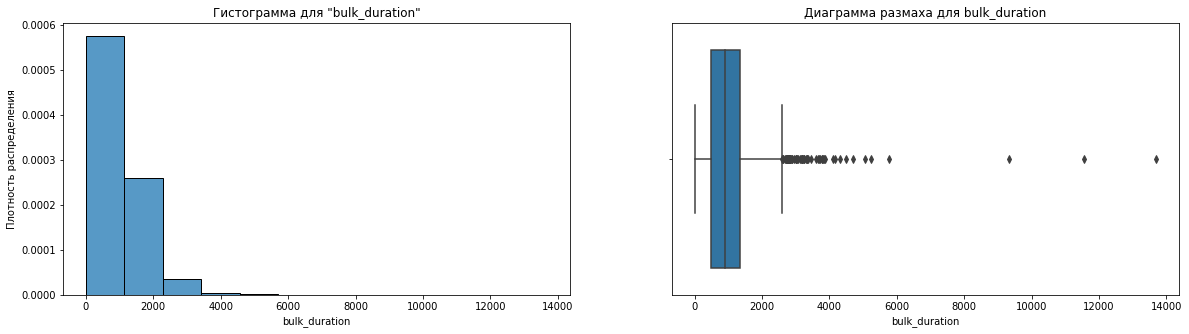

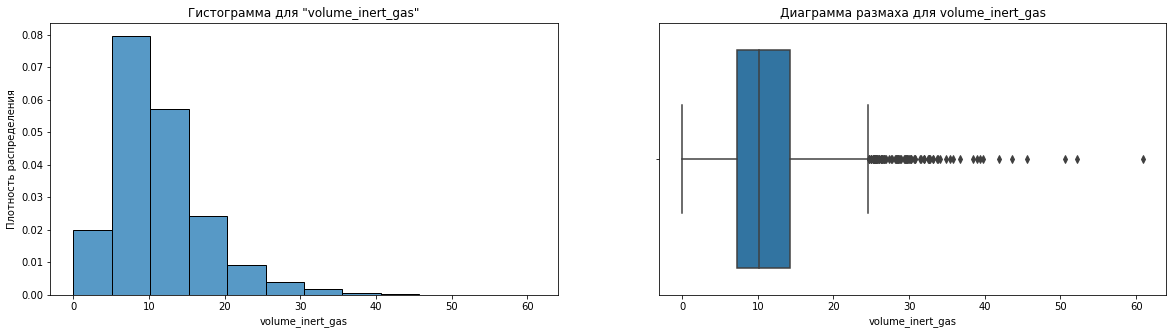

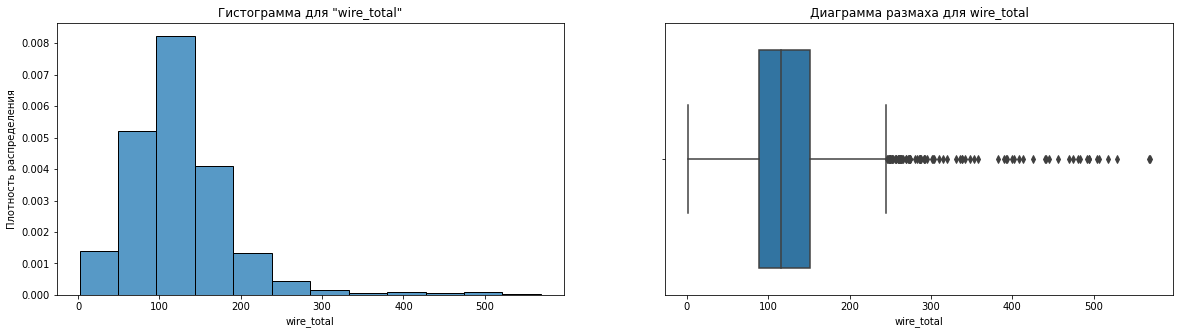

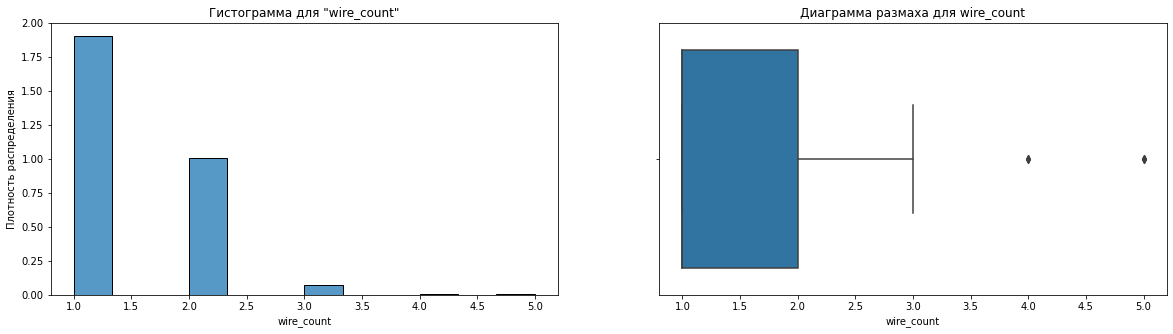

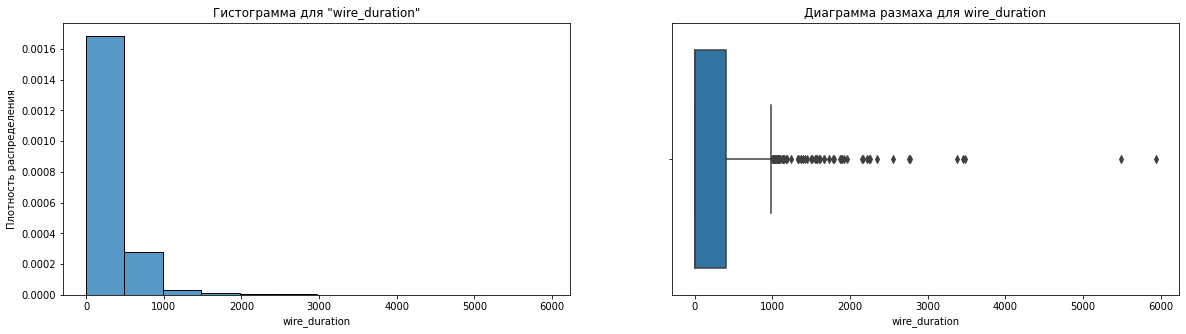

In [88]:
# Построение гистограммы и диаграммы размаха для признаков полученного датафрейма
for feature in [x for x in final_df.columns if x!='key']:
    density_and_box(final_df, feature)

In [89]:
for feature in [x for x in final_df.columns if x!='key']:
    print(feature)
    df_high_border_box, df_low_border_box, df_filtered, df_outliers = border_box(final_df, feature)
    print('-'*50)

start_temperature
верхняя граница (high_border_box):  1651.0
нижняя граница (low_border_box):  1523.0
Количество строк датафрейма, которые попали за границы диаграммы размаха:  14
Доля строк датафрейма, которые попали за границы диаграммы размаха:  0.6021505376344086 %
--------------------------------------------------
end_temperature
верхняя граница (high_border_box):  1614.5
нижняя граница (low_border_box):  1570.5
Количество строк датафрейма, которые попали за границы диаграммы размаха:  180
Доля строк датафрейма, которые попали за границы диаграммы размаха:  7.741935483870968 %
--------------------------------------------------
duration_temperature_measurement_time
верхняя граница (high_border_box):  4606.5
нижняя граница (low_border_box):  -237.5
Количество строк датафрейма, которые попали за границы диаграммы размаха:  66
Доля строк датафрейма, которые попали за границы диаграммы размаха:  2.838709677419355 %
--------------------------------------------------
heating_time
верхняя

In [90]:
# Тест Шапиро-Уилка на нормальность распределения данных для количественных признаков
for feature in [x for x in final_df.columns if x!='key']:
    print(f'Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для {feature}:\n', 
          shapiro(final_df[f'{feature}']))
    print('-'*50)

Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для start_temperature:
 ShapiroResult(statistic=0.9976032972335815, pvalue=0.0012562032788991928)
--------------------------------------------------
Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для end_temperature:
 ShapiroResult(statistic=0.9596048593521118, pvalue=6.151748852243662e-25)
--------------------------------------------------
Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для duration_temperature_measurement_time:
 ShapiroResult(statistic=0.6898391246795654, pvalue=0.0)
--------------------------------------------------
Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для heating_time:
 ShapiroResult(statistic=0.9648014903068542, pvalue=2.2091005198875923e-23)
--------------------------------------------------
Результат выполнения теста Шапиро-Уилка на нормальность распределения данных для max_heating_time_cy

___
Выполнили объединение предобработанных таблиц в один датафрейм `final_df`. Выделим основные его особенности:
- 2325 строк и 20 столбцов
- Пропусков и явных дубликатов нет
- Целевой признак - последняя температура партии `end_temperature`
- Признаки `count_heating_cycles`, `bulk_count`, `wire_count` скорее относятся к категориальным признакам 
- Значения признаков за пределами усов диаграммы размаха считаем возможными и оставили как есть 
- Выполнение теста Шапиро-Уилка показало, что ни один из признаков не имеет нормального распределения
___

In [91]:
# Определение списка количественных признаков
num_cols = [x for x in final_df.columns if x not in ['key', 'count_heating_cycles', 'bulk_count', 'wire_count']]
num_cols

['start_temperature',
 'end_temperature',
 'duration_temperature_measurement_time',
 'heating_time',
 'max_heating_time_cycles',
 'mean_heating_time_cycles',
 'total_active_power',
 'total_reactive_power',
 'total_power',
 'power_factor',
 'work_active_power',
 'bulk_total',
 'bulk_duration',
 'volume_inert_gas',
 'wire_total',
 'wire_duration']

In [92]:
# Определение списка категориальных признаков
cat_cols = ['count_heating_cycles', 'bulk_count', 'wire_count']
cat_cols

['count_heating_cycles', 'bulk_count', 'wire_count']

### Корреляционный анализ

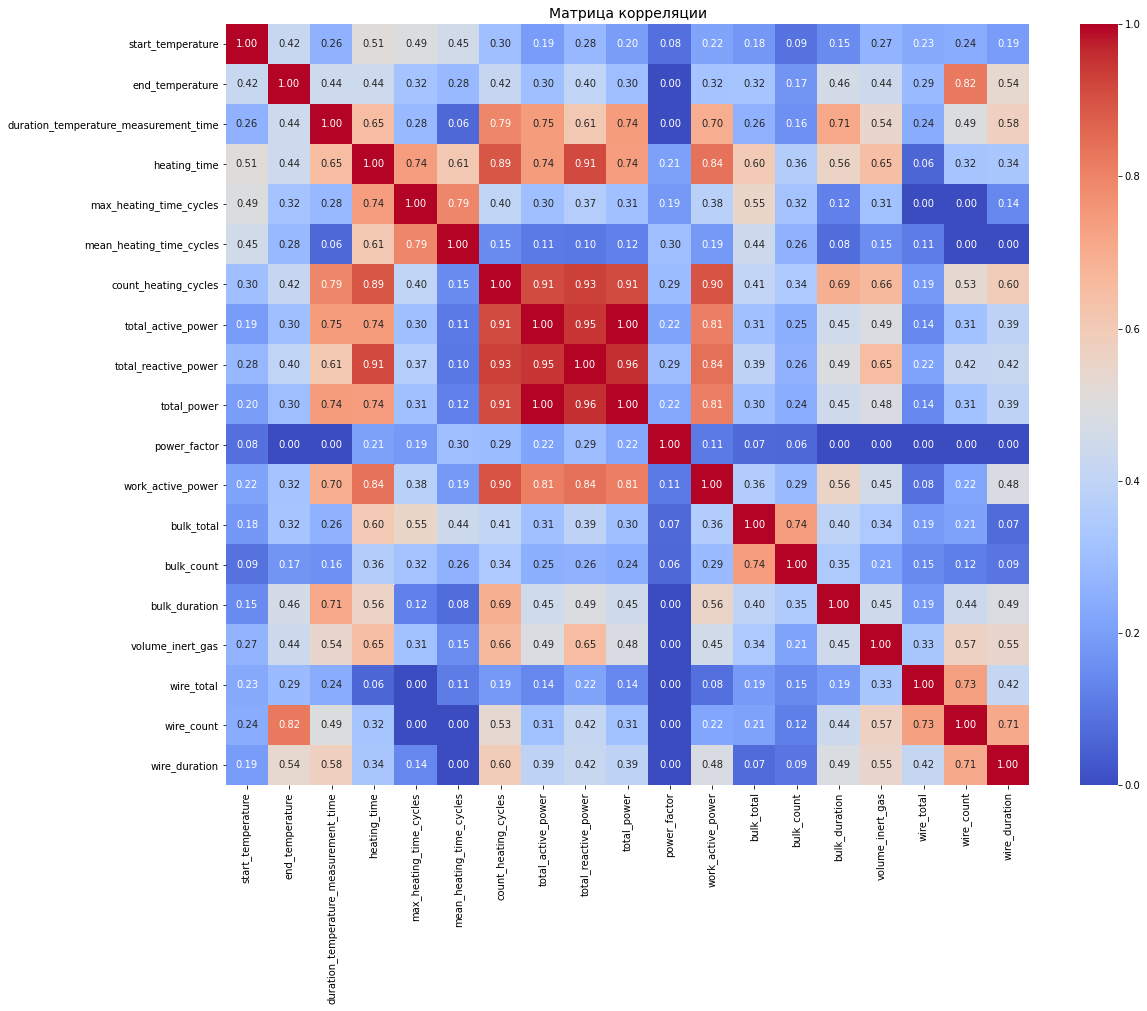

In [93]:
# Расчет коэффициентов коррелиции Фи
# Вызовем метод 'phik_matrix', чтобы построить матрицу корреляций для входных признаков в датафрейме
# Выведем матрицу корреляций в виде тепловой карты
plt.figure(figsize=(18, 14))
sns.heatmap(final_df.drop('key', axis=1).phik_matrix(interval_cols=num_cols), 
            annot=True, 
            fmt='.2f', 
            cmap="coolwarm") 
plt.title("Матрица корреляции", fontsize=14)
plt.show()

In [94]:
# Оценка степени мультиколлинеарности между признаками с помощью Variance Inflation Factor (VIF)
# Как правило, значение VIF выше 5 требует внимания, а выше 10 — серьезного рассмотрения изменений в модели 

# добавление константы
VIFs_df = add_constant(final_df[num_cols])

# расчет VIF для каждого количественного признака
# VIF - Коэффициент инфляции дисперсии
VIFs = pd.DataFrame()
VIFs['Feature'] = VIFs_df.columns
VIFs['VIF'] = [variance_inflation_factor(VIFs_df.values, i) for i in range(VIFs_df.shape[1])]
display(VIFs.sort_values(by='VIF',ascending=False))

,Feature,VIF
9,total_power,"1,263,233.594"
7,total_active_power,"531,542.400"
8,total_reactive_power,"158,267.635"
0,const,"44,152.515"
4,heating_time,14.124
11,work_active_power,13.385
10,power_factor,6.520
3,duration_temperature_measurement_time,4.097
6,mean_heating_time_cycles,3.836
5,max_heating_time_cycles,3.381


___
- Наблюдается очень высокая корреляция между признаками:
    - `total_power`|`total_active_power` (1.00) 
    - `total_power` | `total_reactive_power`(0.98) 
- Предлагаю исключать признаки с высокими значениями VIF с пересчетом коэффициентов корреляции и VIF. Далее из датафрейма исключим признаки `total_active_power`, `total_reactive_power` и `work_active_power`
___

In [95]:
print('До изменений', final_df.shape)
final_df = final_df.drop(['total_active_power', 'total_reactive_power', 'work_active_power'], axis=1)
print('После изменений', final_df.shape)

До изменений (2325, 20)
После изменений (2325, 17)


In [96]:
# Обновление списка количественных признаков
num_cols = [x for x in final_df.columns if x not in ['key', 'count_heating_cycles', 'bulk_count', 'wire_count']]
num_cols

['start_temperature',
 'end_temperature',
 'duration_temperature_measurement_time',
 'heating_time',
 'max_heating_time_cycles',
 'mean_heating_time_cycles',
 'total_power',
 'power_factor',
 'bulk_total',
 'bulk_duration',
 'volume_inert_gas',
 'wire_total',
 'wire_duration']

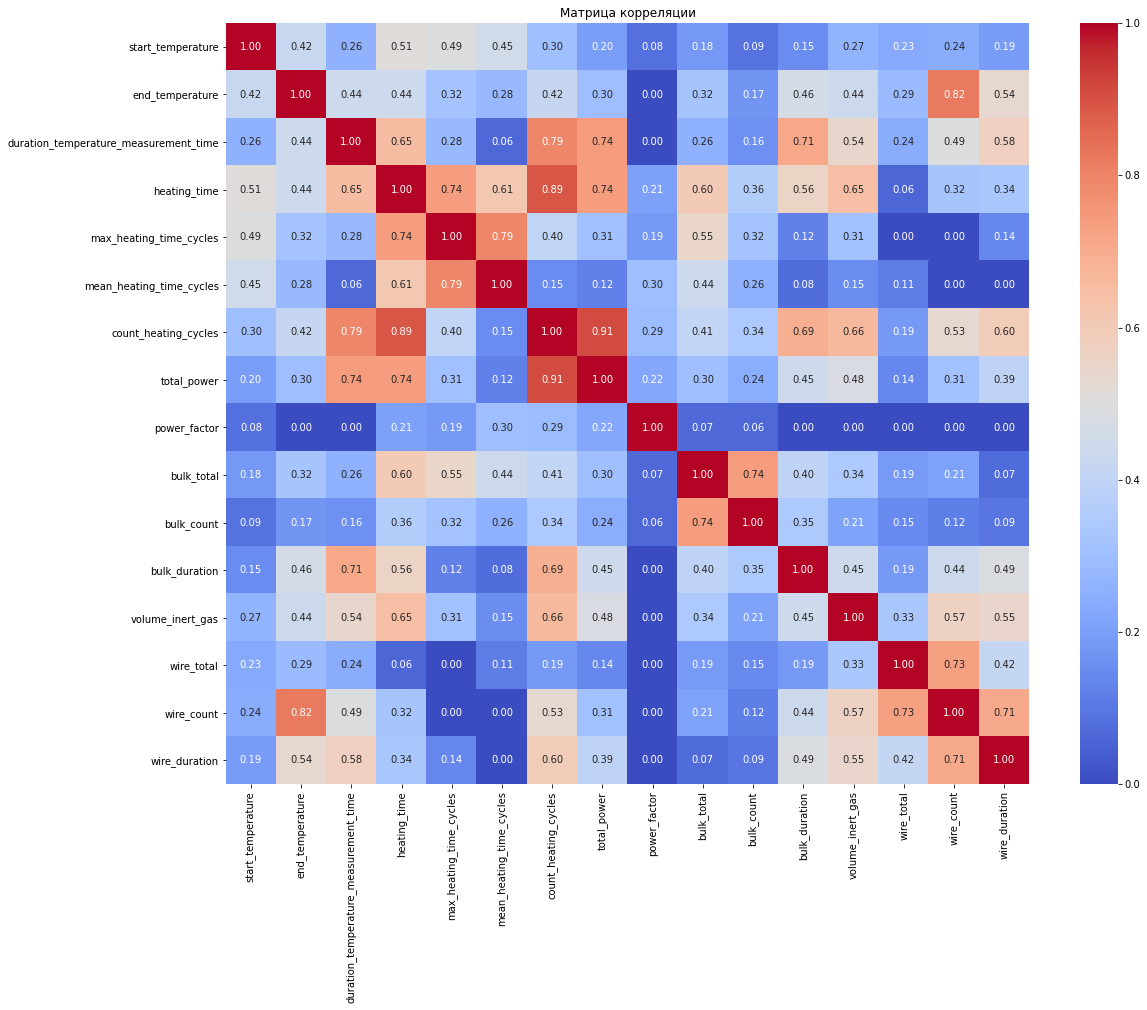

In [97]:
# Расчет коэффициентов коррелиции Фи
# Вызовем метод 'phik_matrix', чтобы построить матрицу корреляций для входных признаков в датафрейме
# Выведем матрицу корреляций в виде тепловой карты
plt.figure(figsize=(18, 14))
sns.heatmap(final_df.drop('key', axis=1).phik_matrix(interval_cols=num_cols), 
            annot=True, 
            fmt='.2f', 
            cmap="coolwarm") 
plt.title("Матрица корреляции")
plt.show()

In [98]:
# Оценка степени мультиколлинеарности между признаками с помощью Variance Inflation Factor (VIF)
# Как правило, значение VIF выше 5 требует внимания, а выше 10 — серьезного рассмотрения изменений в модели 

# добавление константы
VIFs_df = add_constant(final_df[num_cols])

# расчет VIF для каждого количественного признака
# VIF - Коэффициент инфляции дисперсии
VIFs = pd.DataFrame()
VIFs['Feature'] = VIFs_df.columns
VIFs['VIF'] = [variance_inflation_factor(VIFs_df.values, i) for i in range(VIFs_df.shape[1])]
display(VIFs.sort_values(by='VIF',ascending=False))

,Feature,VIF
0,const,"25,963.841"
4,heating_time,9.252
6,mean_heating_time_cycles,3.802
7,total_power,3.757
3,duration_temperature_measurement_time,3.582
5,max_heating_time_cycles,3.317
1,start_temperature,2.905
10,bulk_duration,2.228
9,bulk_total,1.931
2,end_temperature,1.828


___
- Выполнили корреляционный анализ, в результате которого ислючили три признака с высокой степенью мультиколлинеарности: `total_active_power`, `total_reactive_power` и `work_active_power`. В результате для обучения модели осталось 15 признаков.
- Наибольшее влияние на целевой признак имеют:
    - Количество раз `wire_count` и длительность `wire_duration` подачи проволочных материалов 
    - Длительность подачи сыпучих материалов `bulk_duration`
    - Общая мощность `total_power`
    - Температура старта нагрева `start_temperature`
    - Количество циклов нагрева `count_heating_cycles` 
    - Длительность измерения температуры `duration_temperature_measurement_time`
___

### Подготовка данных для обучения 

Основные особенности данных:
- Целевой признак - `end_temperature` представлен в численном формате, корректировок не требует
- Для количественных признаков необходимо выполнить масштабирование в зависимости от модели, учтем это далее при создании Pipeline. 
- Категориальные признаки уже представлены в целочисленном формате, кодировать нет необходимости.  

In [99]:
data_info(final_df)

,key,start_temperature,end_temperature,duration_temperature_measurement_time,heating_time,max_heating_time_cycles,mean_heating_time_cycles,count_heating_cycles,total_power,power_factor,bulk_total,bulk_count,bulk_duration,volume_inert_gas,wire_total,wire_count,wire_duration
0,1,"1,571.000","1,613.000",1714,1098,365,219.600,5,3.717,0.817,553.000,4,1085,29.750,60.060,1,0
1,2,"1,581.000","1,602.000",1265,811,338,202.750,4,2.586,0.827,582.000,4,1000,12.556,96.052,1,0
2,3,"1,596.000","1,599.000",1753,655,280,131.000,5,5.014,0.810,544.000,4,983,28.555,91.160,1,0
3,4,"1,601.000","1,625.000",1220,741,278,185.250,4,3.399,0.796,595.000,4,878,18.841,89.064,1,0
4,5,"1,576.000","1,602.000",1536,869,415,217.250,4,2.815,0.800,584.000,4,205,5.414,98.353,2,310


--------------------------------------------------
Основная информация о датафрейме:
<class 'pandas.core.frame.DataFrame'>
Int64Index: 2325 entries, 0 to 2324
Data columns (total 17 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   key                                    2325 non-null   int64  
 1   start_temperature                      2325 non-null   float64
 2   end_temperature                        2325 non-null   float64
 3   duration_temperature_measurement_time  2325 non-null   int64  
 4   heating_time                           2325 non-null   int64  
 5   max_heating_time_cycles                2325 non-null   int64  
 6   mean_heating_time_cycles               2325 non-null   float64
 7   count_heating_cycles                   2325 non-null   int64  
 8   total_power                            2325 non-null   float64
 9   power_factor                           2325 non-null   

,count,mean,std,min,25%,50%,75%,max
key,"2,325.000","1,252.121",714.634,1.000,631.000,"1,255.000","1,868.000","2,499.000"
start_temperature,"2,325.000","1,587.354",23.593,"1,519.000","1,571.000","1,587.000","1,603.000","1,660.000"
end_temperature,"2,325.000","1,593.345",11.189,"1,541.000","1,587.000","1,593.000","1,598.000","1,653.000"
duration_temperature_measurement_time,"2,325.000","2,310.428","1,310.055",270.000,"1,579.000","2,045.000","2,790.000","21,331.000"
heating_time,"2,325.000",805.249,331.483,57.000,581.000,778.000,992.000,"2,919.000"
max_heating_time_cycles,"2,325.000",289.295,106.441,57.000,212.000,276.000,339.000,780.000
mean_heating_time_cycles,"2,325.000",171.968,43.706,57.000,141.000,169.400,198.500,378.000
count_heating_cycles,"2,325.000",4.687,1.584,1.000,4.000,5.000,6.000,16.000
total_power,"2,325.000",3.872,1.490,0.332,2.842,3.760,4.764,14.450
power_factor,"2,325.000",0.805,0.015,0.740,0.796,0.806,0.815,0.857


,count,mean,std,min,25%,50%,75%,max
key,"2,325.000","1,252.121",714.634,1.000,631.000,"1,255.000","1,868.000","2,499.000"
start_temperature,"2,325.000","1,587.354",23.593,"1,519.000","1,571.000","1,587.000","1,603.000","1,660.000"
end_temperature,"2,325.000","1,593.345",11.189,"1,541.000","1,587.000","1,593.000","1,598.000","1,653.000"
duration_temperature_measurement_time,"2,325.000","2,310.428","1,310.055",270.000,"1,579.000","2,045.000","2,790.000","21,331.000"
heating_time,"2,325.000",805.249,331.483,57.000,581.000,778.000,992.000,"2,919.000"
max_heating_time_cycles,"2,325.000",289.295,106.441,57.000,212.000,276.000,339.000,780.000
mean_heating_time_cycles,"2,325.000",171.968,43.706,57.000,141.000,169.400,198.500,378.000
count_heating_cycles,"2,325.000",4.687,1.584,1.000,4.000,5.000,6.000,16.000
total_power,"2,325.000",3.872,1.490,0.332,2.842,3.760,4.764,14.450
power_factor,"2,325.000",0.805,0.015,0.740,0.796,0.806,0.815,0.857


--------------------------------------------------
Количество пропущенных значений (количество и %):


,0
key,0
power_factor,0
wire_count,0
wire_total,0
volume_inert_gas,0
bulk_duration,0
bulk_count,0
bulk_total,0
total_power,0
start_temperature,0


,0
key,0.00%
power_factor,0.00%
wire_count,0.00%
wire_total,0.00%
volume_inert_gas,0.00%
bulk_duration,0.00%
bulk_count,0.00%
bulk_total,0.00%
total_power,0.00%
start_temperature,0.00%


In [100]:
# Исключение целевого признака из списка количественных признаков
num_cols = [x for x in num_cols if x!='end_temperature']
num_cols

['start_temperature',
 'duration_temperature_measurement_time',
 'heating_time',
 'max_heating_time_cycles',
 'mean_heating_time_cycles',
 'total_power',
 'power_factor',
 'bulk_total',
 'bulk_duration',
 'volume_inert_gas',
 'wire_total',
 'wire_duration']

In [101]:
# Установка столбца с номером партии в качестве индекса датафрейма
final_df = final_df.set_index('key')
final_df.head()

,start_temperature,end_temperature,duration_temperature_measurement_time,heating_time,max_heating_time_cycles,mean_heating_time_cycles,count_heating_cycles,total_power,power_factor,bulk_total,bulk_count,bulk_duration,volume_inert_gas,wire_total,wire_count,wire_duration
key,,,,,,,,,,,,,,,,
1,"1,571.000","1,613.000",1714,1098,365,219.600,5,3.717,0.817,553.000,4,1085,29.750,60.060,1,0
2,"1,581.000","1,602.000",1265,811,338,202.750,4,2.586,0.827,582.000,4,1000,12.556,96.052,1,0
3,"1,596.000","1,599.000",1753,655,280,131.000,5,5.014,0.810,544.000,4,983,28.555,91.160,1,0
4,"1,601.000","1,625.000",1220,741,278,185.250,4,3.399,0.796,595.000,4,878,18.841,89.064,1,0
5,"1,576.000","1,602.000",1536,869,415,217.250,4,2.815,0.800,584.000,4,205,5.414,98.353,2,310


In [102]:
# Разделение данных: 75% train+valid, 25% test
X_train, X_test, y_train, y_test = train_test_split(final_df.drop('end_temperature', axis=1), 
                                                            final_df['end_temperature'], 
                                                            test_size=TEST_SIZE,
                                                            random_state=RANDOM_STATE)

In [103]:
# вывод размера и доли полученных выборок
print('X_train', X_train.shape)
print('y_train', y_train.shape[0])
print(f'Доля train+valid: {X_train.shape[0]/final_df.shape[0]:.2f}')
print('X_test', X_test.shape)
print('y_test', y_test.shape[0])
print(f'Доля test: {X_test.shape[0]/final_df.shape[0]:.2f}')

X_train (1743, 15)
y_train 1743
Доля train+valid: 0.75
X_test (582, 15)
y_test 582
Доля test: 0.25


___
**Вывод**

В рамках исследовательского анализа и предобработки данных выполнили следующее:

1. Загрузили и проанализировали исходные данные:
    - `data_arc` — данные об электродах;
    - `data_bulk` — данные об объёме сыпучих материалов;
    - `data_bulk_time` — данные о времени подачи сыпучих материалов;
    - `data_gas` — данные о продувке сплава газом;
    - `data_temp` — данные об измерениях температуры;
    - `data_wire` — данные об объёме проволочных материалов;
    - `data_wire_time` — данные о времени подачи проволочных материалов.
2. Выполнили предобработку данных:
    - Привели наименования столбцов к стандарту PEP8
    - Для столбцов, содержащих дату и время изменили тип данных на `datetime`. Для столбцов, содержащих численные значения изменили тип на `float`/`int`.
    - Отрицательное значение реактивной мощности заменили его на медианное значение
    - В столбце `Температура` были пропуски. Исключили данные строки и строки, где значения температуры были ниже 1500 градусов как аномальные по условию заказчика.
    - Удалили строки, где общий объем сыпучих материалов превышал 1500 кг как аномальные
    - Дополнительно исключили строки с партиями, где было всего одно измерение температуры
    - Добавили дополнительные признаки:
        - `heating_time` длительность нагрева (суммарное время нагрева для одной партии в секундах), 
        - `total_power` общую мощность (S) (векторная сумма активной (P) и реактивной мощностей (Q): $ S=\sqrt{P^2 + Q^2} $)
        - `power_factor` соотношение активной мощности к реактивной (PF) (показатель, характеризующий эффективность использования электроэнергии: $ PF=P/S $), 
        - `count_heating_cycles` количество циклов нагрева для одной партии 
        - `mean_heating_time_cycles` среднее время нагрева в цикле для одной партии в секундах
        - `max_heating_time_cycles` максимальное время нагрева в цикле для одной партии в секундах
        - `work_active_power` работа, совершаемая активной мощностью (произведение активной мощности на длительность нагрева)
        - `bulk_total`, `wire_total` с расчетом суммы объёма подаваемого материала
        - `bulk_count`, `wire_count` с расчетом количества раз, когда подавали материал
        - `bulk_duration`, `wire_duration` с расчетом разницы в секундах между первым и последним добавлением материала
        - Начальная `start_temperature` и последняя `end_temperature` температура партии. Последняя температура партии является целевым признаком в данном проекте.
        - Длительность измерения температуры в секундах `duration_temperature_measurement_time`
    - Объединили предобработанные таблицы в один датафрейм `final_df` с учетом:
        - Каждой партии должно соответствовать одно наблюдение.
        - Во все партии точно добавлялись сыпучие и проволочные материалы, везде была выполнена продувка газом и сплав всегда нагревался.
    - Провели корреляционный анализ, в результате которого ислючили три признака с высокой степенью мультиколлинеарности: `total_active_power`, `total_reactive_power` и `work_active_power`. В результате для обучения модели осталось 15 признаков в `final_df`(2329, 16). Наибольшее влияние на целевой признак имеют:
        - Количество раз `wire_count` и длительность `wire_duration` подачи проволочных материалов 
        - Длительность подачи сыпучих материалов `bulk_duration`
        - Общая мощность `total_power`
        - Температура старта нагрева `start_temperature`
        - Количество циклов нагрева `count_heating_cycles` 
        - Длительность измерения температуры `duration_temperature_measurement_time`
3. Подготовили тренировочную и тестовую выборки в соотношении 75% / 25%:
    - Целевой признак - `end_temperature`
    - X_train (1743, 15) | y_train (1746)
    - X_test (582, 15) | y_test (583)
___

## Обучение моделей и поиск лучшей

In [104]:
# Создание препроцессинга 
preprocessor = ColumnTransformer(
    transformers = [
        ('num', StandardScaler(), num_cols)
    ], 
    remainder='passthrough'
)

In [105]:
# Создание пайплайна: подготовка данных и модель
def pipe(model):
    return Pipeline(
        [
            ('preprocessor', preprocessor), 
            ('model', model)
        ]
    )

In [106]:
# Результаты
results = []

### Обучение модели линейной регрессии `LinearRegression`

In [107]:
lr_pipeline = pipe(LinearRegression())

# создание словаря гиперпараметров модели
lr_params = {'preprocessor__num': [StandardScaler(), MinMaxScaler()]}

In [108]:
%%time
# Перебор гиперпараметров с помощью RandomizedSearchCV
lr_search = RandomizedSearchCV(lr_pipeline, 
                               lr_params, 
                               n_iter=2, 
                               scoring='neg_mean_absolute_error',  # минимизируем MAE
                               cv=CV,
                               random_state=RANDOM_STATE,
                               verbose=2,
                               n_jobs=-1)
lr_search.fit(X_train, y_train)

Fitting 3 folds for each of 2 candidates, totalling 6 fits
[CV] END .................preprocessor__num=StandardScaler(); total time=   0.0s
[CV] END .................preprocessor__num=StandardScaler(); total time=   0.1s
[CV] END .................preprocessor__num=StandardScaler(); total time=   0.1s
[CV] END ...................preprocessor__num=MinMaxScaler(); total time=   0.1s
[CV] END ...................preprocessor__num=MinMaxScaler(); total time=   0.0s
[CV] END ...................preprocessor__num=MinMaxScaler(); total time=   0.1s
CPU times: user 285 ms, sys: 265 ms, total: 550 ms
Wall time: 515 ms


RandomizedSearchCV(cv=3,
                   estimator=Pipeline(steps=[('preprocessor',
                                              ColumnTransformer(remainder='passthrough',
                                                                transformers=[('num',
                                                                               StandardScaler(),
                                                                               ['start_temperature',
                                                                                'duration_temperature_measurement_time',
                                                                                'heating_time',
                                                                                'max_heating_time_cycles',
                                                                                'mean_heating_time_cycles',
                                                                                'total_power',
             

In [109]:
# сохранение результатов RandomizedSearchCV
results_lr_search = pd.DataFrame(lr_search.cv_results_).sort_values(by='rank_test_score').reset_index(drop=True)

# Сохранение обученного пайплайна 
best_lr = lr_search.best_estimator_

# сохранение метрики качества на кросс-валидации
mae_lr = lr_search.best_score_*(-1)

In [110]:
print(f'Параметры пайплайна: {lr_search.best_params_}')
print(f'MAE на кросс-валидации {mae_lr}')
print(f'Время обучения: {results_lr_search["mean_fit_time"][0]:.2f} сек')
print(f'Среднее время предсказания и расчета метрики качества на кросс-валидации: {results_lr_search["mean_score_time"][0]:.2f} сек')
display(results_lr_search.head(3))

Параметры пайплайна: {'preprocessor__num': StandardScaler()}
MAE на кросс-валидации 6.3125201882173245
Время обучения: 0.07 сек
Среднее время предсказания и расчета метрики качества на кросс-валидации: 0.01 сек


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_preprocessor__num,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,0.065,0.040,0.006,0.000,StandardScaler(),{'preprocessor__num': StandardScaler()},-6.301,-6.314,-6.323,-6.313,0.009,1
1,0.060,0.035,0.006,0.001,MinMaxScaler(),{'preprocessor__num': MinMaxScaler()},-6.301,-6.314,-6.323,-6.313,0.009,2


In [111]:
results.append({
    'model': 'LinearRegression',
    'params': lr_search.best_params_,
    'mae': mae_lr,
    'train_time': results_lr_search["mean_fit_time"][0],
    'predict_score_time': results_lr_search["mean_score_time"][0] 
})

### Обучение модели случайного леса `RandomForestRegressor`

In [112]:
rf_pipeline = pipe(RandomForestRegressor(random_state=RANDOM_STATE))

# создание словаря гиперпараметров модели
rf_params = {
    'model__n_estimators': np.arange(50, 500, 50),
    'model__max_depth': np.arange(3, 20, 1),
    'preprocessor__num': [StandardScaler(), MinMaxScaler(), 'passthrough']
}

In [113]:
%%time

# Перебор гиперпараметров с помощью RandomizedSearchCV
rf_search = RandomizedSearchCV(
    rf_pipeline, 
    rf_params,
    n_iter=50,
    scoring='neg_mean_absolute_error',   
    cv=CV,
    random_state=RANDOM_STATE,
    verbose=2,
    n_jobs=-1
)

rf_search.fit(X_train, y_train)

print('---')

Fitting 3 folds for each of 50 candidates, totalling 150 fits
[CV] END model__max_depth=16, model__n_estimators=300, preprocessor__num=passthrough; total time=   2.6s
[CV] END model__max_depth=16, model__n_estimators=300, preprocessor__num=passthrough; total time=   2.5s
[CV] END model__max_depth=16, model__n_estimators=300, preprocessor__num=passthrough; total time=   2.5s
[CV] END model__max_depth=12, model__n_estimators=100, preprocessor__num=StandardScaler(); total time=   0.8s
[CV] END model__max_depth=12, model__n_estimators=100, preprocessor__num=StandardScaler(); total time=   0.9s
[CV] END model__max_depth=12, model__n_estimators=100, preprocessor__num=StandardScaler(); total time=   0.8s
[CV] END model__max_depth=10, model__n_estimators=350, preprocessor__num=MinMaxScaler(); total time=   2.7s
[CV] END model__max_depth=10, model__n_estimators=350, preprocessor__num=MinMaxScaler(); total time=   2.4s
[CV] END model__max_depth=10, model__n_estimators=350, preprocessor__num=MinM

In [114]:
# сохранение результатов RandomizedSearchCV
results_rf_search = pd.DataFrame(rf_search.cv_results_).sort_values(by='rank_test_score').reset_index(drop=True)

# Сохранение обученного пайплайна 
best_rf = rf_search.best_estimator_

# сохранение метрики качества на кросс-валидации
mae_rf = rf_search.best_score_*(-1)

In [115]:
print(f'Параметры пайплайна: {rf_search.best_params_}')
print(f'MAE на кросс-валидации {mae_rf}')
print(f'Время обучения: {results_rf_search["mean_fit_time"][0]:.2f} сек')
print(f'Среднее время предсказания и расчета метрики качества на кросс-валидации: {results_rf_search["mean_score_time"][0]:.2f} сек')
display(results_rf_search.head(3))

Параметры пайплайна: {'preprocessor__num': 'passthrough', 'model__n_estimators': 400, 'model__max_depth': 15}
MAE на кросс-валидации 6.3945401988723445
Время обучения: 3.26 сек
Среднее время предсказания и расчета метрики качества на кросс-валидации: 0.07 сек


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_preprocessor__num,param_model__n_estimators,param_model__max_depth,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,3.257,0.060,0.068,0.000,passthrough,400,15,"{'preprocessor__num': 'passthrough', 'model__n_estimators': 400, 'model__max_depth': 15}",-6.366,-6.171,-6.647,-6.395,0.196,1
1,3.832,0.025,0.081,0.002,passthrough,450,19,"{'preprocessor__num': 'passthrough', 'model__n_estimators': 450, 'model__max_depth': 19}",-6.384,-6.174,-6.643,-6.400,0.192,2
2,2.046,0.008,0.046,0.002,MinMaxScaler(),250,15,"{'preprocessor__num': MinMaxScaler(), 'model__n_estimators': 250, 'model__max_depth': 15}",-6.371,-6.176,-6.658,-6.402,0.198,3


In [116]:
results.append({
    'model': 'RandomForestRegressor',
    'params': rf_search.best_params_,
    'mae': mae_rf,
    'train_time': results_rf_search["mean_fit_time"][0],
    'predict_score_time': results_rf_search["mean_score_time"][0] 
})

### Обучение модели градиентного бустинга `LGBMRegressor`

In [117]:
lgbm_pipeline = pipe(LGBMRegressor(verbose=-1, random_state=RANDOM_STATE))

# создание словаря гиперпараметров модели
lgbm_params = {
    'model__n_estimators': np.arange(50, 300, 50),
    'model__num_leaves': np.arange(20, 200, 20),
    'model__max_depth': np.arange(3, 12, 1),
    'model__learning_rate': np.arange(0.05, 0.7, 0.05),
    'preprocessor': [StandardScaler(), 'passthrough']
}

In [118]:
%%time

# Перебор гиперпараметров с помощью RandomizedSearchCV
lgbm_search = RandomizedSearchCV(
    lgbm_pipeline, 
    lgbm_params,
    n_iter=30,
    scoring='neg_mean_absolute_error',   
    cv=CV,
    random_state=RANDOM_STATE,
    verbose=2,
    n_jobs=-1
)

lgbm_search.fit(X_train, y_train)

print('---')

Fitting 3 folds for each of 30 candidates, totalling 90 fits
[CV] END model__learning_rate=0.4, model__max_depth=10, model__n_estimators=50, model__num_leaves=160, preprocessor=passthrough; total time=   0.5s
[CV] END model__learning_rate=0.4, model__max_depth=10, model__n_estimators=50, model__num_leaves=160, preprocessor=passthrough; total time=   0.5s
[CV] END model__learning_rate=0.4, model__max_depth=10, model__n_estimators=50, model__num_leaves=160, preprocessor=passthrough; total time=   0.7s
[CV] END model__learning_rate=0.5, model__max_depth=4, model__n_estimators=250, model__num_leaves=180, preprocessor=passthrough; total time=   0.8s
[CV] END model__learning_rate=0.5, model__max_depth=4, model__n_estimators=250, model__num_leaves=180, preprocessor=passthrough; total time=   0.8s
[CV] END model__learning_rate=0.5, model__max_depth=4, model__n_estimators=250, model__num_leaves=180, preprocessor=passthrough; total time=   0.9s
[CV] END model__learning_rate=0.1, model__max_depth

In [119]:
# сохранение результатов RandomizedSearchCV
results_lgbm_search = pd.DataFrame(lgbm_search.cv_results_).sort_values(by='rank_test_score').reset_index(drop=True)

# Сохранение обученного пайплайна 
best_lgbm = lgbm_search.best_estimator_

# сохранение метрики качества на кросс-валидации
mae_lgbm = lgbm_search.best_score_*(-1)

In [120]:
print(f'Параметры пайплайна: {lgbm_search.best_params_}')
print(f'MAE на кросс-валидации {mae_lgbm}')
print(f'Время обучения: {results_lgbm_search["mean_fit_time"][0]:.2f} сек')
print(f'Среднее время предсказания и расчета метрики качества на кросс-валидации: {results_lgbm_search["mean_score_time"][0]:.2f} сек')
display(results_lgbm_search.head(3))

Параметры пайплайна: {'preprocessor': 'passthrough', 'model__num_leaves': 60, 'model__n_estimators': 200, 'model__max_depth': 3, 'model__learning_rate': 0.05}
MAE на кросс-валидации 6.481232471815129
Время обучения: 0.43 сек
Среднее время предсказания и расчета метрики качества на кросс-валидации: 0.03 сек


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_preprocessor,param_model__num_leaves,param_model__n_estimators,param_model__max_depth,param_model__learning_rate,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,0.431,0.044,0.034,0.042,passthrough,60,200,3,0.050,"{'preprocessor': 'passthrough', 'model__num_leaves': 60, 'model__n_estimators': 200, 'model__max_depth': 3, 'model__learning_rate': 0.05}",-6.274,-6.498,-6.672,-6.481,0.163,1
1,6.332,6.552,0.005,0.000,passthrough,100,200,11,0.050,"{'preprocessor': 'passthrough', 'model__num_leaves': 100, 'model__n_estimators': 200, 'model__max_depth': 11, 'model__learning_rate': 0.05}",-6.285,-6.507,-6.803,-6.532,0.212,2
2,1.032,0.121,0.007,0.003,StandardScaler(),180,100,11,0.100,"{'preprocessor': StandardScaler(), 'model__num_leaves': 180, 'model__n_estimators': 100, 'model__max_depth': 11, 'model__learning_rate': 0.1}",-6.315,-6.459,-6.908,-6.561,0.252,3


In [121]:
results.append({
    'model': 'LGBMRegressor',
    'params': lgbm_search.best_params_,
    'mae': mae_lgbm,
    'train_time': results_lgbm_search["mean_fit_time"][0],
    'predict_score_time': results_lgbm_search["mean_score_time"][0] 
})

### Обучение модели градиентного бустинга `CatBoostRegressor`

In [122]:
catboost_pipeline = pipe(CatBoostRegressor(early_stopping_rounds=50, 
                                                 cat_features=cat_cols,
                                                 random_state=RANDOM_STATE, 
                                                 verbose=500))

# создание словаря гиперпараметров модели
catboost_params = {
    'model__iterations': np.arange(500, 1500, 100),
    'model__depth': np.arange(3, 10, 1),
    'model__learning_rate': np.arange(0.05, 0.7, 0.05),
    'preprocessor': ['passthrough']
}

In [123]:
%%time


# Перебор гиперпараметров с помощью RandomizedSearchCV
catboost_search = RandomizedSearchCV(
    catboost_pipeline, 
    catboost_params,
    n_iter=40,
    scoring='neg_mean_absolute_error',   
    cv=CV,
    random_state=RANDOM_STATE,
    verbose=1,
    n_jobs=-1
)

catboost_search.fit(X_train, y_train)

print('---')

Fitting 3 folds for each of 40 candidates, totalling 120 fits
0:	learn: 10.0056363	total: 104ms	remaining: 1m 53s
500:	learn: 0.0004636	total: 23s	remaining: 27.5s
1000:	learn: 0.0000003	total: 45.8s	remaining: 4.53s
1099:	learn: 0.0000001	total: 50.4s	remaining: 0us
0:	learn: 9.6897534	total: 44.5ms	remaining: 48.9s
500:	learn: 0.0006911	total: 22.9s	remaining: 27.3s
1000:	learn: 0.0000003	total: 46.2s	remaining: 4.57s
1099:	learn: 0.0000001	total: 50.8s	remaining: 0us
0:	learn: 9.6058759	total: 42.2ms	remaining: 46.4s
500:	learn: 0.0009378	total: 23.3s	remaining: 27.8s
1000:	learn: 0.0000007	total: 46.1s	remaining: 4.56s
1099:	learn: 0.0000002	total: 50.6s	remaining: 0us
0:	learn: 11.2008779	total: 1.84ms	remaining: 1.28s
500:	learn: 5.0100932	total: 702ms	remaining: 279ms
699:	learn: 4.4871195	total: 978ms	remaining: 0us
0:	learn: 10.7603457	total: 1.85ms	remaining: 1.29s
500:	learn: 5.3159828	total: 710ms	remaining: 282ms
699:	learn: 4.7999353	total: 1s	remaining: 0us
0:	learn: 10.

In [124]:
# сохранение результатов RandomizedSearchCV
results_catboost_search = pd.DataFrame(catboost_search.cv_results_).sort_values(by='rank_test_score').reset_index(drop=True)

# Сохранение обученного пайплайна 
best_catboost = catboost_search.best_estimator_

# сохранение метрики качества на кросс-валидации
mae_catboost = catboost_search.best_score_*(-1)

In [125]:
print(f'Параметры пайплайна: {catboost_search.best_params_}')
print(f'MAE на кросс-валидации {mae_catboost}')
print(f'Время обучения: {results_catboost_search["mean_fit_time"][0]:.2f} сек')
print(f'Среднее время предсказания и расчета метрики качества на кросс-валидации: {results_catboost_search["mean_score_time"][0]:.2f} сек')
display(results_catboost_search.head(3))

Параметры пайплайна: {'preprocessor': 'passthrough', 'model__learning_rate': 0.05, 'model__iterations': 500, 'model__depth': 5}
MAE на кросс-валидации 6.321027584739564
Время обучения: 2.61 сек
Среднее время предсказания и расчета метрики качества на кросс-валидации: 0.00 сек


,mean_fit_time,std_fit_time,mean_score_time,std_score_time,param_preprocessor,param_model__learning_rate,param_model__iterations,param_model__depth,params,split0_test_score,split1_test_score,split2_test_score,mean_test_score,std_test_score,rank_test_score
0,2.606,0.248,0.004,0.001,passthrough,0.050,500,5,"{'preprocessor': 'passthrough', 'model__learning_rate': 0.05, 'model__iterations': 500, 'model__depth': 5}",-6.235,-6.224,-6.504,-6.321,0.129,1
1,3.416,0.436,0.004,0.000,passthrough,0.050,1400,3,"{'preprocessor': 'passthrough', 'model__learning_rate': 0.05, 'model__iterations': 1400, 'model__depth': 3}",-6.306,-6.214,-6.553,-6.358,0.143,2
2,6.839,0.399,0.004,0.000,passthrough,0.050,1100,6,"{'preprocessor': 'passthrough', 'model__learning_rate': 0.05, 'model__iterations': 1100, 'model__depth': 6}",-6.243,-6.260,-6.584,-6.363,0.157,3


In [126]:
results.append({
    'model': 'CatBoostRegressor',
    'params': catboost_search.best_params_,
    'mae': mae_catboost,
    'train_time': results_catboost_search["mean_fit_time"][0],
    'predict_score_time': results_catboost_search["mean_score_time"][0] 
})

### Полносвязная нейронная сеть 

In [127]:
# Выбор устройства для вычислений
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
device = '/GPU:0' if len(tf.config.list_physical_devices('GPU')) > 0 else '/CPU:0'
print(f"Используемое устройство: {device}")

Num GPUs Available:  0
Используемое устройство: /CPU:0


In [128]:
# Разделение тренеровочных данных: 75% train, 25% valid
X_train_subset, X_val_subset, y_train_subset, y_val_subset = train_test_split(X_train, 
                                                                              y_train, 
                                                                              test_size=TEST_SIZE, 
                                                                              random_state=RANDOM_STATE)

In [129]:
# вывод размера и доли полученных выборок
print('X_train_subset', X_train_subset.shape)
print('y_train_subset', y_train_subset.shape[0])
print(f'Доля train: {X_train_subset.shape[0]/X_train.shape[0]:.2f}')
print('X_val_subset', X_val_subset.shape)
print('y_val_subset', y_val_subset.shape[0])
print(f'Доля valid: {X_val_subset.shape[0]/X_train.shape[0]:.2f}')

X_train_subset (1307, 15)
y_train_subset 1307
Доля train: 0.75
X_val_subset (436, 15)
y_val_subset 436
Доля valid: 0.25


In [130]:
# Масштабирование количественных признаков
scaler = StandardScaler()
X_train_subset[num_cols] = scaler.fit_transform(X_train_subset[num_cols])
X_val_subset[num_cols] = scaler.transform(X_val_subset[num_cols])

/tmp/ipykernel_5599/3187098957.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X_train_subset[num_cols] = scaler.fit_transform(X_train_subset[num_cols])
/opt/conda/lib/python3.9/site-packages/pandas/core/indexing.py:1738: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value[:, i].tolist(), pi)
/tmp/ipykernel_5599/3187098957.py:4: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value inst

In [131]:
# Проверка 
X_train_subset.head()

,start_temperature,duration_temperature_measurement_time,heating_time,max_heating_time_cycles,mean_heating_time_cycles,count_heating_cycles,total_power,power_factor,bulk_total,bulk_count,bulk_duration,volume_inert_gas,wire_total,wire_count,wire_duration
key,,,,,,,,,,,,,,,
2301,2.837,-0.866,-1.515,-0.819,-0.307,2,-1.165,-0.879,-1.049,3,-1.265,-1.492,0.056,2,0.992
1887,-0.375,0.668,0.977,0.104,0.332,6,1.918,-0.968,1.752,6,1.743,0.659,0.711,1,-0.541
950,-0.375,-0.304,-0.148,-0.204,0.397,4,-0.977,1.210,0.972,5,0.495,1.050,0.227,2,0.681
1868,-2.235,-0.291,1.064,1.531,2.650,4,-0.090,0.698,-0.936,2,-1.265,0.559,4.608,3,2.271
2116,-0.333,-0.435,-1.158,-1.453,-1.480,4,-0.399,-0.178,-0.975,2,-0.777,0.035,-0.809,1,-0.541


In [132]:
# Архитектура полносвязной нейронной сети (далее - модель)
fnn_model = Sequential([
    Dense(512, activation='relu', input_shape=(X_train_subset.shape[1],)),
    BatchNormalization(),
    Dropout(0.2),

    Dense(256, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    Dense(128, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),
    
    Dense(64, activation='relu'),
    BatchNormalization(),
    Dropout(0.1),

    Dense(32, activation='relu'),
    BatchNormalization(),
    
    Dense(1)
])

# Компиляция модели
fnn_model.compile(optimizer=Adam(learning_rate=0.001),
                loss='mse',
                metrics=['mae'])

# Настройка ранней остановки
early_stop = EarlyStopping(monitor='val_loss',
                           patience=20,
                           restore_best_weights=True,
                           verbose=1)

2026-01-18 09:03:06.839635: I tensorflow/core/platform/cpu_feature_guard.cc:151] This TensorFlow binary is optimized with oneAPI Deep Neural Network Library (oneDNN) to use the following CPU instructions in performance-critical operations:  AVX2 AVX512F FMA
To enable them in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [133]:
# Выполнение обучения модели
with tf.device(device): # Указываем устройство для обучения
    fnn_model.fit(
    X_train_subset, y_train_subset,
    validation_data=(X_val_subset, y_val_subset),
    epochs=5000,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1)

Epoch 1/5000
41/41 [==============================] - 2s 23ms/step - loss: 2537465.2500 - mae: 1592.9080 - val_loss: 2538356.7500 - val_mae: 1593.1865
Epoch 2/5000
41/41 [==============================] - 1s 19ms/step - loss: 2535962.7500 - mae: 1592.4453 - val_loss: 2532523.2500 - val_mae: 1591.3613
Epoch 3/5000
41/41 [==============================] - 1s 18ms/step - loss: 2533755.5000 - mae: 1591.7555 - val_loss: 2529440.0000 - val_mae: 1590.3934
Epoch 4/5000
41/41 [==============================] - 1s 17ms/step - loss: 2530739.5000 - mae: 1590.8090 - val_loss: 2524668.5000 - val_mae: 1588.8956
Epoch 5/5000
41/41 [==============================] - 1s 17ms/step - loss: 2526872.0000 - mae: 1589.5925 - val_loss: 2522145.5000 - val_mae: 1588.1008
Epoch 6/5000
41/41 [==============================] - 1s 17ms/step - loss: 2522127.5000 - mae: 1588.1000 - val_loss: 2517910.0000 - val_mae: 1586.7689
Epoch 7/5000
41/41 [==============================] - 1s 16ms/step - loss: 2516509.2500 - mae:

In [134]:
# Вывод описания архитектуры модели
fnn_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 dense (Dense)               (None, 512)               8192      
                                                                 
 batch_normalization (BatchN  (None, 512)              2048      
 ormalization)                                                   
                                                                 
 dropout (Dropout)           (None, 512)               0         
                                                                 
 dense_1 (Dense)             (None, 256)               131328    
                                                                 
 batch_normalization_1 (Batc  (None, 256)              1024      
 hNormalization)                                                 
                                                                 
 dropout_1 (Dropout)         (None, 256)               0

In [135]:
# Получение предсказаний и метрики качества на валидации 
fnn_preds = fnn_model.predict(X_val_subset).flatten()
fnn_mae = mean_absolute_error(y_val_subset, fnn_preds)
print(f'MAE: {fnn_mae:.4f}')

MAE: 6.6929


In [136]:
results.append({
    'model': 'FNN-Model',
    'params': pd.NA,
    'mae': fnn_mae,
    'train_time': pd.NA,
    'predict_score_time': pd.NA
})

### Анализ моделей

In [137]:
# вывод в одной таблице результатов обучения моделей, их оптимальных параметров и метрик качества RMSE на кросс-валидации
results_df = pd.DataFrame(results).sort_values(by='mae').reset_index(drop=True)
display(results_df)

,model,params,mae,train_time,predict_score_time
0,LinearRegression,{'preprocessor__num': StandardScaler()},6.313,0.065,0.006
1,CatBoostRegressor,"{'preprocessor': 'passthrough', 'model__learning_rate': 0.05, 'model__iterations': 500, 'model__depth': 5}",6.321,2.606,0.004
2,RandomForestRegressor,"{'preprocessor__num': 'passthrough', 'model__n_estimators': 400, 'model__max_depth': 15}",6.395,3.257,0.068
3,LGBMRegressor,"{'preprocessor': 'passthrough', 'model__num_leaves': 60, 'model__n_estimators': 200, 'model__max_depth': 3, 'model__learning_rate': 0.05}",6.481,0.431,0.034
4,FNN-Model,<NA>,6.693,<NA>,<NA>


___
**Вывод**

Выполнили обучение различных моделей и нашли лучшую:
- 1 место `LinearRegression`, `MAE` = `6.313`
- 2 место `CatBoostRegressor` с параметрами `{'preprocessor': 'passthrough', 'model__learning_rate': 0.05, 'model__iterations': 500, 'model__depth': 5}`, где `MAE` на кроссвалидации = `6.321` 
- 3 место `RandomForestRegressor`, `MAE` = `6.395`
- 4 место `LGBMRegressor`, `MAE` = `6.481` 
- 5 место полносвязная нейронная сеть `FNN-Model`, `MAE` на валидации `6.693`
        
Можно отметить, что все модели показали схожее качество предсказаний на валидации, выбрали в качестве лучшей `CatBoostRegressor`
___

## Тестирование лучшей модели и демонстрация ее работы

In [139]:
# Получение предсказаний на тестовых данных
y_test_pred_catboost = best_catboost.predict(X_test)
#y_test_pred_lr = best_lr.predict(X_test)

In [140]:
# Расчет метрик качества на тестовых данных
#mae_test_lr = mean_absolute_error(y_test, y_test_pred_lr)
#print(f' MAE на тестовых данных: {mae_test_lr:.4f}')

#r2_test_lr = r2_score(y_test, y_test_pred_lr)
#print(f' R^2 на тестовых данных: {r2_test_lr:.4f}')

 MAE на тестовых данных: 6.5786
 R^2 на тестовых данных: 0.4069


In [141]:
# Расчет метрик качества на тестовых данных
mae_test_catboost = mean_absolute_error(y_test, y_test_pred_catboost)
print(f' MAE на тестовых данных: {mae_test_catboost:.4f}')

r2_test_catboost = r2_score(y_test, y_test_pred_catboost)
print(f' R^2 на тестовых данных: {r2_test_catboost:.4f}')

 MAE на тестовых данных: 6.1647
 R^2 на тестовых данных: 0.4525


___
- По результатам тестирования модель `CatBoostRegressor` показала результат `MAE` = `~6.2`, удовлетворяющий требование заказчика, где `MAE` должно быть менее `6.8`
- Метрика качества R² показывает, насколько хорошо наша модель объясняет изменения в целевой переменной по сравнению с простым средним значением. В нашем случае модель объясняет ~45% дисперсии целевого признака. 

Далее сравним результаты нашей лучшей и константной моделей. В качестве константной возьмем модель `DummyRegressor` с предсказанием среднего значения
___

In [142]:
dummy = DummyRegressor(strategy="mean")
dummy.fit(X_train, y_train)
dummy_preds = dummy.predict(X_test)

dummy_mae = mean_absolute_error(y_test, dummy_preds)
dummy_r2 = r2_score(y_test, dummy_preds)

print('DummyRegressor')
print(f'MAE на тестовых данных: {dummy_mae:.4f}')
print(f'R2 на тестовых данных: {dummy_r2:.4f}')

DummyRegressor
MAE на тестовых данных: 8.2321
R2 на тестовых данных: -0.0026


___
Дополнительно построим график целевых и предсказанных значений по последней температуры партии с помощью нашей лучшей и константной моделей

In [143]:
# Создание датафрейма с целевой переменной
predictions = y_test.to_frame()

# Добавление столбца с предсказаниями нашей и константной модели
predictions['end_temperature_pred_catboost'] = y_test_pred_catboost
predictions['end_temperature_pred_dummy_mean'] = dummy_preds

# Выполнение сортировки по возрастанию индексов
predictions = predictions.sort_index()
predictions.head()

,end_temperature,end_temperature_pred_catboost,end_temperature_pred_dummy_mean
key,,,
1,"1,613.000","1,600.960","1,593.199"
4,"1,625.000","1,599.867","1,593.199"
12,"1,591.000","1,596.148","1,593.199"
13,"1,619.000","1,600.012","1,593.199"
14,"1,606.000","1,605.049","1,593.199"


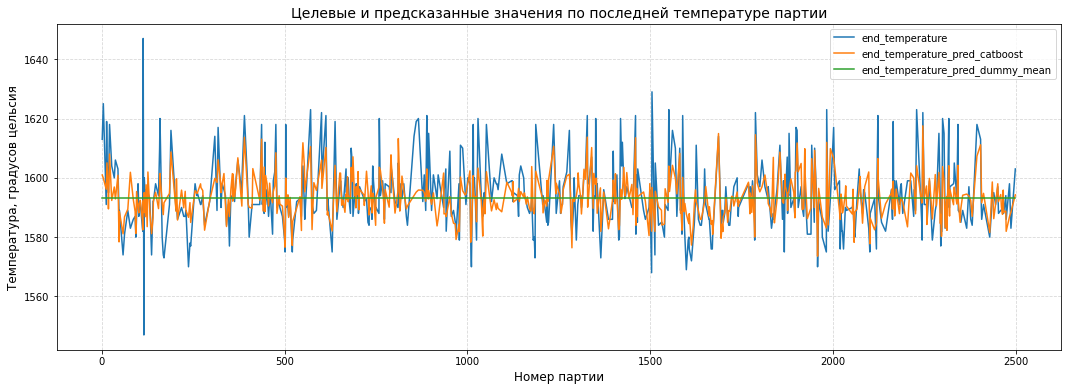

In [144]:
# Построение графика целевых и предсказанных значений по последней температуры партии
plt.figure(figsize=(18, 6))
plt.plot(predictions['end_temperature'], label='end_temperature')
plt.plot(predictions['end_temperature_pred_catboost'], label='end_temperature_pred_catboost')
plt.plot(predictions['end_temperature_pred_dummy_mean'], label='end_temperature_pred_dummy_mean')
plt.grid(linestyle='--', alpha=0.5)
plt.title('Целевые и предсказанные значения по последней температуре партии', fontsize=14)
plt.xlabel('Номер партии', fontsize=12)
plt.ylabel('Температура, градусов цельсия', fontsize=12)
plt.legend()
plt.show()

### Анализ важности признаков

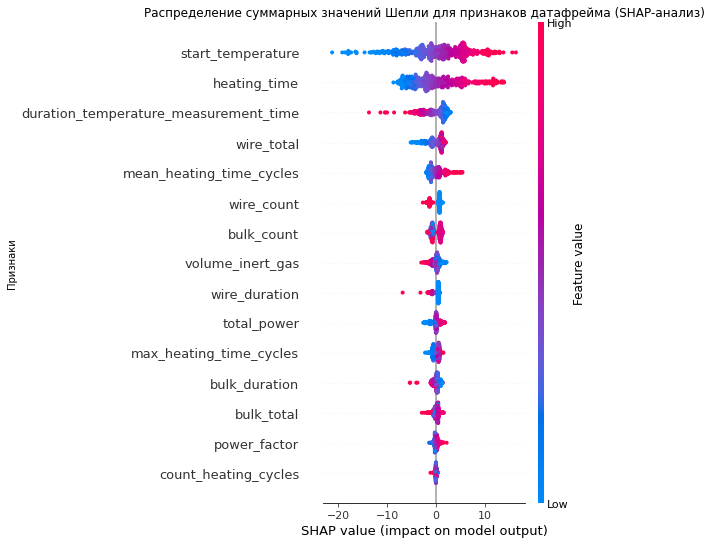

In [145]:
# Создаем Explainer
explainer_catboost = shap.TreeExplainer(best_catboost['model'])

# Получаем SHAP-значения для данных
shap_values_catboost = explainer_catboost(X_test)

# Визуализиурем важность признаков для для класса 1 
shap.summary_plot(shap_values_catboost, X_test, max_display=30, show=False)
plt.ylabel('Признаки')
plt.title(f'Распределение суммарных значений Шепли для признаков датафрейма (SHAP-анализ)')
plt.show()

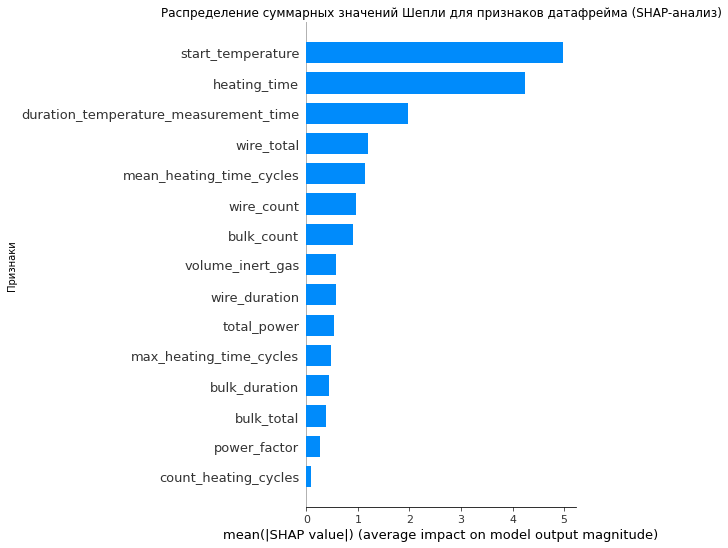

In [146]:
shap.summary_plot(shap_values_catboost, 
                  X_test,  
                  plot_type="bar", 
                  max_display=30,
                  show=False)
plt.ylabel('Признаки')
plt.title(f'Распределение суммарных значений Шепли для признаков датафрейма (SHAP-анализ)')
plt.show()

Истиное значение y: 1599.0
Предсказанное значение y: 1590.7522238866802


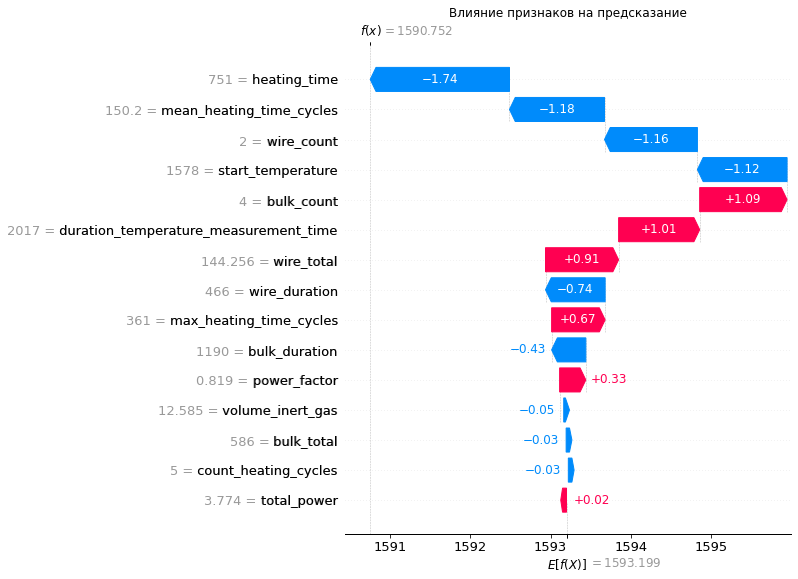

In [149]:
## для примера визуализируем индивидуальные SHAP-значения записи в датафрейме
print(f'Истиное значение y: {y_test.loc[2168]}') # первая строка с key=2168
print(f'Предсказанное значение y: {y_test_pred_catboost[0]}')
shap.plots.waterfall(shap_values_catboost[0], max_display=30, show=False)
plt.title(f'Влияние признаков на предсказание')
plt.show()

___
**Вывод**

- По результатам тестирования модель `CatBoostRegressor` показала результат `MAE` = ~6.2, удовлетворяющий требование заказчика, где `MAE` должно быть менее 6.8. В нашем случае модель в среднем ошибается на 6.2 градуса цельсия в прогнозах последней температуры партии и объясняет ~45% дисперсии данного признака. 
- В рамках анализа важности признаков, особо выделяются следующие признаки:
    - время нагрева `heating_time`, рост которого влияет на рост последней температуры партии
    - аналогично влияет и значение начальной температуры партии `start_temperature` 
    - далее менее влияют такие признаки, как: 
        - время процесса измерения температуры`duration_temperature_measurement_time`, что фактически является временем всего процесса
        - объем проволочных материалов и количество раз их добавления `wire_total` и `wire_count`
        - среднее время нагрева в цикле `mean_heating_time_cycles` 
        - количество раз добавления сыпучих материалов`bulk_count`
        - объем продувки сплава инертным газом`volume_inert_gas`
___

### График зависимости входного и целевого признаков

#### Зависимость последней температуры от времени нагрева партии

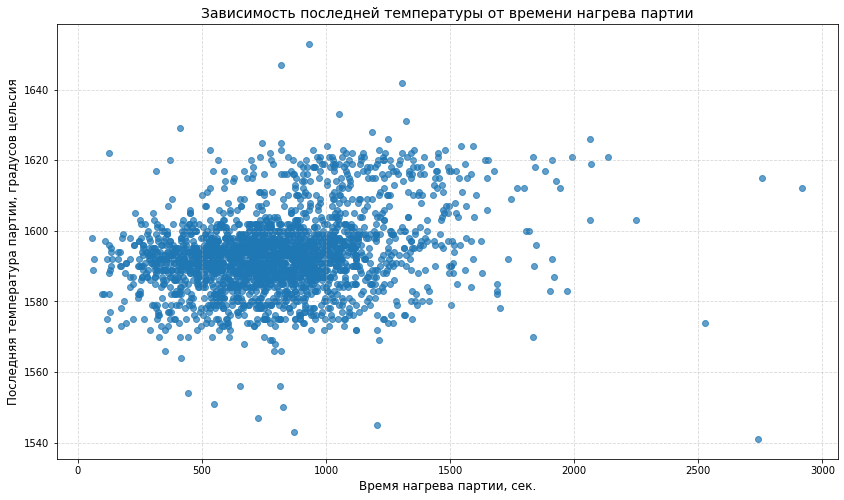

In [167]:
# Построение scatter plot
plt.figure(figsize=(14, 8))
plt.scatter(final_df['heating_time'], final_df['end_temperature'], 
           alpha=0.7)
plt.title('Зависимость последней температуры от времени нагрева партии', fontsize=14)
plt.xlabel('Время нагрева партии, сек.', fontsize=12)
plt.ylabel('Последняя температура партии, градусов цельсия', fontsize=12)
plt.grid(linestyle='--', alpha=0.5)
plt.show()

___
Умеренная положительная связь, коэффициент корреляции равен 0.42
___

In [159]:
# Зависимость последней температуры партии от времени нагрева
heating_time_end_temperature = (
    final_df.groupby('heating_time')['end_temperature'].agg(['count', 'mean', 'median', 'min', 'max']).reset_index()
)
heating_time_end_temperature.rename(columns={'count': 'count', 
                                             'mean': 'mean_end_temperature', 
                                             'median': 'median_end_temperature', 
                                             'min': 'min_end_temperature', 
                                             'max': 'max_end_temperature'}, inplace=True)
# Фильтрация случаев с count>1
heating_time_end_temperature = heating_time_end_temperature.query('count>1')
print(heating_time_end_temperature.shape)
display(heating_time_end_temperature.head())

(620, 6)


,heating_time,count,mean_end_temperature,median_end_temperature,min_end_temperature,max_end_temperature
6,119,2,"1,583.500","1,583.500","1,575.000","1,592.000"
7,125,2,"1,577.000","1,577.000","1,572.000","1,582.000"
9,127,2,"1,609.000","1,609.000","1,596.000","1,622.000"
12,132,2,"1,592.500","1,592.500","1,590.000","1,595.000"
19,173,2,"1,575.500","1,575.500","1,573.000","1,578.000"


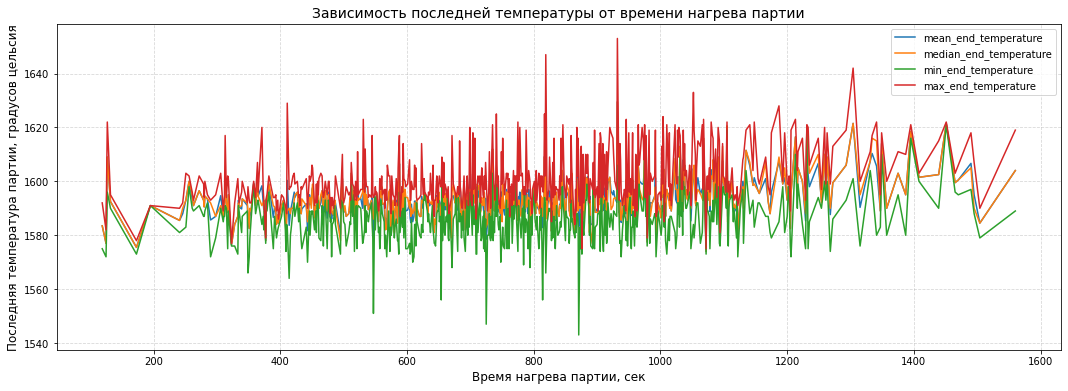

In [160]:
# Построение графика зависимости последней температуры от времени нагрева партии
plt.figure(figsize=(18, 6))
plt.plot(heating_time_end_temperature['heating_time'], 
         heating_time_end_temperature['mean_end_temperature'], 
         label='mean_end_temperature')
plt.plot(heating_time_end_temperature['heating_time'], 
         heating_time_end_temperature['median_end_temperature'], 
         label='median_end_temperature')
plt.plot(heating_time_end_temperature['heating_time'], 
         heating_time_end_temperature['min_end_temperature'], 
         label='min_end_temperature')
plt.plot(heating_time_end_temperature['heating_time'], 
         heating_time_end_temperature['max_end_temperature'], 
         label='max_end_temperature')
plt.grid(linestyle='--', alpha=0.5)
plt.title('Зависимость последней температуры от времени нагрева партии', fontsize=14)
plt.xlabel('Время нагрева партии, сек', fontsize=12)
plt.ylabel('Последняя температура партии, градусов цельсия', fontsize=12)
plt.legend()
plt.show()

#### Зависимость последней температуры от значения начальной температуры партии

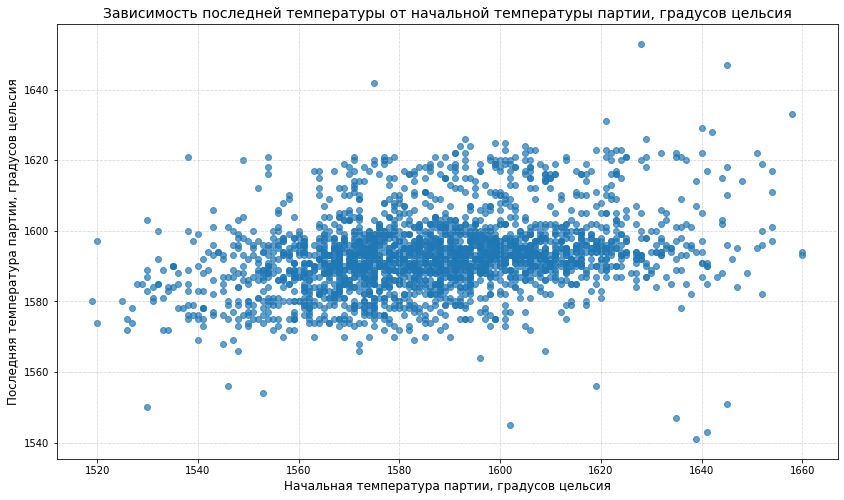

In [168]:
# Построение scatter plot
plt.figure(figsize=(14, 8))
plt.scatter(final_df['start_temperature'], final_df['end_temperature'], 
           alpha=0.7)
plt.title('Зависимость последней температуры от начальной температуры партии, градусов цельсия', fontsize=14)
plt.xlabel('Начальная температура партии, градусов цельсия', fontsize=12)
plt.ylabel('Последняя температура партии, градусов цельсия', fontsize=12)
plt.grid(linestyle='--', alpha=0.5)
plt.show()

___
Умеренная положительная связь, коэффициент корреляции равен 0.44
___

In [162]:
# Зависимость последней температуры от значения начальной температуры партии
start_temperature_end_temperature = (
    final_df.groupby('start_temperature')['end_temperature'].agg(['count', 'mean', 'median', 'min', 'max']).reset_index()
)
start_temperature_end_temperature.rename(columns={'count': 'count', 
                                             'mean': 'mean_end_temperature', 
                                             'median': 'median_end_temperature', 
                                             'min': 'min_end_temperature', 
                                             'max': 'max_end_temperature'}, inplace=True)
# Фильтрация случаев с count>1
#start_temperature_end_temperature = start_temperature_end_temperature.query('count>1')
print(start_temperature_end_temperature.shape)
display(start_temperature_end_temperature.head())

(132, 6)


,start_temperature,count,mean_end_temperature,median_end_temperature,min_end_temperature,max_end_temperature
0,"1,519.000",1,"1,580.000","1,580.000","1,580.000","1,580.000"
1,"1,520.000",2,"1,585.500","1,585.500","1,574.000","1,597.000"
2,"1,525.000",1,"1,580.000","1,580.000","1,580.000","1,580.000"
3,"1,526.000",2,"1,573.500","1,573.500","1,572.000","1,575.000"
4,"1,527.000",2,"1,576.000","1,576.000","1,574.000","1,578.000"


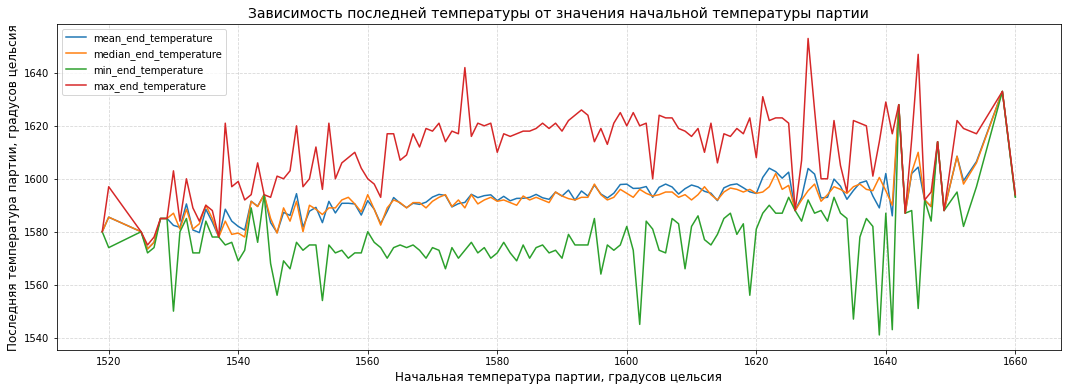

In [163]:
# Построение графика зависимости последней температуры от значения начальной температуры партии
plt.figure(figsize=(18, 6))
plt.plot(start_temperature_end_temperature['start_temperature'], 
         start_temperature_end_temperature['mean_end_temperature'], 
         label='mean_end_temperature')
plt.plot(start_temperature_end_temperature['start_temperature'], 
         start_temperature_end_temperature['median_end_temperature'], 
         label='median_end_temperature')
plt.plot(start_temperature_end_temperature['start_temperature'], 
         start_temperature_end_temperature['min_end_temperature'], 
         label='min_end_temperature')
plt.plot(start_temperature_end_temperature['start_temperature'], 
         start_temperature_end_temperature['max_end_temperature'], 
         label='max_end_temperature')
plt.grid(linestyle='--', alpha=0.5)
plt.title('Зависимость последней температуры от значения начальной температуры партии', fontsize=14)
plt.xlabel('Начальная температура партии, градусов цельсия', fontsize=12)
plt.ylabel('Последняя температура партии, градусов цельсия', fontsize=12)
plt.legend()
plt.show()

## Вывод

В данном проекте мы разработали и обучили модель `CatBoostRegressor`, способную прогнозировать температуру сплава стали (последняя в производственном цикле температура партии в градусах цельсия). 

Параметры пайплайна и модели: количественные признаки без масштабированния,`{'preprocessor': 'passthrough', 'model__learning_rate': 0.05, 'model__iterations': 500, 'model__depth': 5}`

По результатам тестирования модель `CatBoostRegressor` показала результат `MAE` = `~6.2`, удовлетворяющий требование заказчика, где `MAE` должно быть менее `6.8` В нашем случае модель объясняет ~45% дисперсии целевого признака.


В рамках решения указанной задачи были выполненны следующие этапы:


1. Загрузили и проанализировали исходные данные:

    - `data_arc` — данные об электродах;
    - `data_bulk` — данные об объёме сыпучих материалов;
    - `data_bulk_time` — данные о времени подачи сыпучих материалов;
    - `data_gas` — данные о продувке сплава газом;
    - `data_temp` — данные об измерениях температуры;
    - `data_wire` — данные об объёме проволочных материалов;
    - `data_wire_time` — данные о времени подачи проволочных материалов.


2. Выполнили предобработку данных:

    - Привели наименования столбцов к стандарту PEP8
    - Для столбцов, содержащих дату и время изменили тип данных на `datetime`. Для столбцов, содержащих численные значения изменили тип на `float`/`int`.
    - Отрицательное значение реактивной мощности заменили его на медианное значение
    - В столбце `Температура` были пропуски. Исключили данные строки и строки, где значения температуры были ниже 1500 градусов как аномальные по условию заказчика.
    - Исключили строки с общим объемом сыпучих материалов более 1500 кг как аномальные.
    - Дополнительно исключили строки с партиями, где было всего одно измерение температуры
    - Добавили дополнительные признаки:
        - `heating_time` длительность нагрева (суммарное время нагрева для одной партии в секундах), 
        - `total_power` общую мощность (S) (векторная сумма активной (P) и реактивной мощностей (Q): $ S=\sqrt{P^2 + Q^2} $)
        - `power_factor` соотношение активной мощности к реактивной (PF) (показатель, характеризующий эффективность использования электроэнергии: $ PF=P/S $), 
        - `count_heating_cycles` количество циклов нагрева для одной партии 
        - `mean_heating_time_cycles` среднее время нагрева в цикле для одной партии в секундах
        - `max_heating_time_cycles` максимальное время нагрева в цикле для одной партии в секундах
        - `work_active_power` работа, совершаемая активной мощностью (произведение активной мощности на длительность нагрева)
        - `bulk_total`, `wire_total` с расчетом суммы объёма подаваемого материала
        - `bulk_count`, `wire_count` с расчетом количества раз, когда подавали материал
        - `bulk_duration`, `wire_duration` с расчетом разницы в секундах между первым и последним добавлением материала
        - Начальная `start_temperature` и последняя `end_temperature` температура партии. Последняя температура партии является целевым признаком в данном проекте.
        - Длительность измерения температуры в секундах `duration_temperature_measurement_time`
    - Объединили предобработанные таблицы в один датафрейм `final_df` с учетом:
        - Каждой партии должно соответствовать одно наблюдение.
        - Во все партии точно добавлялись сыпучие и проволочные материалы, везде была выполнена продувка газом и сплав всегда нагревался.
    - Провели корреляционный анализ, в результате которого ислючили три признака с высокой степенью мультиколлинеарности: `total_active_power`, `total_reactive_power` и `work_active_power`. В результате для обучения модели осталось 15 признаков в `final_df`(2329, 16). Наибольшее влияние на целевой признак имеют:
        - Количество раз `wire_count` и длительность `wire_duration` подачи проволочных материалов 
        - Длительность подачи сыпучих материалов `bulk_duration`
        - Общая мощность `total_power`
        - Температура старта нагрева `start_temperature`
        - Количество циклов нагрева `count_heating_cycles` 
        - Длительность измерения температуры `duration_temperature_measurement_time`


3. Подготовили тренировочную и тестовую выборки в соотношении 75% / 25%:

    - Целевой признак - `end_temperature`
    - X_train (1743, 15) | y_train (1746)
    - X_test (582, 15) | y_test (583)


4. Выполнили обучение различных моделей и нашли лучшую:

    - 1 место `LinearRegression`, `MAE` = `6.313`
    - 2 место `CatBoostRegressor` с параметрами `{'preprocessor': 'passthrough', 'model__learning_rate': 0.05, 'model__iterations': 500, 'model__depth': 5}`, где `MAE` на кроссвалидации = `6.321` 
    - 3 место `RandomForestRegressor`, `MAE` = `6.395`
    - 4 место `LGBMRegressor`, `MAE` = `6.481` 
    - 5 место полносвязная нейронная сеть `FNN-Model`, `MAE` на валидации `6.693`
                
Можно отметить, что все модели показали схожее качество предсказаний на валидации, выбрали в качестве лучшей `CatBoostRegressor`

5. Выполнили тестирование модели:

    - По результатам тестирования модель `CatBoostRegressor` показала результат `MAE` = ~6.2, удовлетворяющий требование заказчика, где `MAE` должно быть менее 6.8. В нашем случае модель в среднем ошибается на 6.2 градуса цельсия в прогнозах последней температуры партии и объясняет ~51% дисперсии данного признака. 
    - В рамках анализа важности признаков, особо выделяются следующие признаки:
        - время нагрева `heating_time`, рост которого влияет на рост последней температуры партии
        - аналогично влияет и значение начальной температуры партии `start_temperature` 
        - далее менее влияют такие признаки, как: 
            - время процесса измерения температуры`duration_temperature_measurement_time`, что фактически является временем всего процесса
            - объем проволочных материалов и количество раз их добавления `wire_total` и `wire_count`
            - среднее время нагрева в цикле `mean_heating_time_cycles` 
            - количество раз добавления сыпучих материалов`bulk_count`
            - объем продувки сплава инертным газом`volume_inert_gas`

___

Рекомендации для бизнеса:
- Дополнительно использовать данные о химическом составе стали, которая подаётся на вход. Вероятно, сплавы с разным составом нагреваются по-разному.
- Предоставить больше информации о технологическом процессе и какие данные по признакам считаются аномальными.
- Повысить качество данных по основным этапам производственного цикла: добавляление сыпучих и проволочных материалов, продувка газом, нагрев сплава. В некоторых случаях нет данных об одном из перечисленных этапов.